In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [5]:
import os
BASE = '/content/drive/MyDrive/Project59'

if not os.path.exists(BASE):
    print("Project59 folder available")
    print("\nMyDrive present in my drive:")
    for f in sorted(os.listdir('/content/drive/MyDrive'))[:30]:
        print("  ", f)
else:
    print(" Project59 found\n")
    for root, dirs, files in os.walk(BASE):
        lvl = root.replace(BASE,'').count(os.sep)
        print('  '*lvl + os.path.basename(root) + '/')
        for f in sorted(files):
            mb = os.path.getsize(f'{root}/{f}')/1e6
            print('  '*(lvl+1) + f'{f}  ({mb:.1f} MB)')

 Project59 found

Project59/
  Project59_bortezomib.pptx  (1.0 MB)
  Project59_slides.zip  (0.9 MB)
  data/
    cmap_to_gtex.json  (0.0 MB)
    sb_library_sets.json  (2.4 MB)
    top50_names.json  (0.0 MB)
    gtex/
      sbgenes_raw.csv  (10.1 MB)
    cmap/
      cellinfo.csv  (0.0 MB)
      geneinfo.csv  (1.1 MB)
    reference/
      cmap_to_gtex.json  (0.0 MB)
      gid_to_ensg.json  (0.3 MB)
      sb_library_sets.json  (2.4 MB)
      top50_names.json  (0.0 MB)
  results/
    bortezomib_comparisons.xlsx  (0.0 MB)
    per_signature_categories.csv  (2.7 MB)
    per_signature_v3_no_filter.csv  (3.2 MB)
    50_drugs/
      per_drug_4category_counts.csv  (0.0 MB)
      per_drug_lineage.csv  (0.1 MB)
      significant_hits.csv  (0.0 MB)
    sig_known/
      sig_known.csv  (242.6 MB)
      sig_known_top50.csv  (13.4 MB)
    tables/
      4_category_breakdown.xlsx  (0.0 MB)
      4_category_breakdown_FIXED.xlsx  (0.0 MB)
      50_drugs_44_tissues_FULL.csv  (0.1 MB)
      50_drugs_44_tissues

In [6]:
import json, pandas as pd

BASE = '/content/drive/MyDrive/Project59'
REF  = f'{BASE}/data/reference'

# ---- reference objects (sets, lists nahi — yeh bug tha pehle) ----
cmap_to_gtex    = {k: set(v) for k,v in json.load(open(f'{REF}/cmap_to_gtex.json')).items()}
sb_library_sets = {k: set(v) for k,v in json.load(open(f'{REF}/sb_library_sets.json')).items()}
gid_to_ensg     = json.load(open(f'{REF}/gid_to_ensg.json'))
top50_names     = json.load(open(f'{REF}/top50_names.json'))

# ---- dataframes ----
genes_info = pd.read_csv(f'{BASE}/data/cmap/geneinfo.csv')
sig_known  = pd.read_csv(f'{BASE}/results/sig_known/sig_known.csv', low_memory=False)

# ---- verify ----
print(f"cmap_to_gtex    : {len(cmap_to_gtex)} lineages   (expected 20)")
print(f"sb_library_sets : {len(sb_library_sets)} tissues  (expected 44)")
print(f"  type check    : {type(list(sb_library_sets.values())[0]).__name__}  (MUST be 'set')")
print(f"gid_to_ensg     : {len(gid_to_ensg):,} genes")
print(f"top50_names     : {len(top50_names)} drugs")
print(f"genes_info      : {len(genes_info):,} rows")
print(f"sig_known       : {len(sig_known):,} rows")
print(f"  columns       : {list(sig_known.columns)}")

cmap_to_gtex    : 20 lineages   (expected 20)
sb_library_sets : 44 tissues  (expected 44)
  type check    : set  (MUST be 'set')
gid_to_ensg     : 12,277 genes
top50_names     : 50 drugs
genes_info      : 12,328 rows
sig_known       : 596,117 rows
  columns       : ['bead_batch', 'nearest_dose', 'pert_dose', 'pert_dose_unit', 'pert_idose', 'pert_itime', 'pert_time', 'pert_time_unit', 'cell_mfc_name', 'pert_mfc_id', 'nsample', 'cc_q75', 'ss_ngene', 'tas', 'pct_self_rank_q25', 'wt', 'median_recall_rank_spearman', 'median_recall_rank_wtcs_50', 'median_recall_score_spearman', 'median_recall_score_wtcs_50', 'batch_effect_tstat', 'batch_effect_tstat_pct', 'is_hiq', 'qc_pass', 'pert_id', 'sig_id', 'pert_type', 'cell_iname', 'det_wells', 'det_plates', 'distil_ids', 'build_name', 'project_code', 'cmap_name', 'is_exemplar_sig', 'is_ncs_sig', 'is_null_sig', 'donor_sex', 'cell_type', 'cell_lineage']


In [7]:
!pip install cmapPy -q
print(" cmapPy installed")

import os
os.makedirs('/content/cmap', exist_ok=True)

gctx_file = '/content/cmap/level5_beta_trt_cp_n720216x12328.gctx'

if os.path.exists(gctx_file):
    print(f"✅ Already here: {os.path.getsize(gctx_file)/1e9:.1f} GB")
else:
    print("⏳ Downloading 33 GB — ~15-20 min. Tab band mat karna.\n")
    !cd /content/cmap && curl -O https://cmapreg.s3.amazonaws.com/galenAI/level5_beta_trt_cp_n720216x12328.gctx

print("\nVerify:")
!ls -lh /content/cmap/

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.2/150.2 kB 867.0 kB/s eta 0:00:00
 cmapPy installed
⏳ Downloading 33 GB — ~15-20 min. Tab band mat karna.

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 33.0G  100 33.0G    0     0  11.4M      0  0:49:22  0:49:22 --:--:-- 11.8M

Verify:
total 34G
-rw-r--r-- 1 root root 34G Sep 28 05:52 level5_beta_trt_cp_n720216x12328.gctx


In [8]:
!pip install gseapy -q
print(" gseapy installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 17.2 MB/s eta 0:00:00
 gseapy installed


In [9]:
from cmapPy.pandasGEXpress.parse import parse
import pandas as pd, numpy as np, gseapy

gctx_file = '/content/cmap/level5_beta_trt_cp_n720216x12328.gctx'

# gctx ke andar kaunse signatures hain
col_meta  = parse(gctx_file, col_meta_only=True)
gctx_sigs = set(col_meta.index)
print(f"gctx signatures: {len(gctx_sigs):,}")


def per_lineage_DE_v3(drug_name, lineage, min_sigs=3):

    # check: gctx have minimum signatures .

    sigs = sig_known[(sig_known['cmap_name']   == drug_name) &
                     (sig_known['cell_lineage'] == lineage)]

    valid_ids = [s for s in sigs['sig_id'] if s in gctx_sigs]
    if len(valid_ids) < min_sigs:
        return None

    expr   = parse(gctx_file, cid=valid_ids).data_df
    mean_z = expr.mean(axis=1)# avg of every gene
    strong = mean_z[mean_z.abs() > 2] # this is a filter

    if len(strong) == 0:# if in a signature there is no any gene with z+_ 2 return none
        return None

    de = pd.DataFrame({'gene_id': strong.index.astype(str), # create a table and make datatype same so that we can use after
                       'z_score': strong.values, # we have a dataframe with gene_id index , another col is z_score and score  both z score and score are same
                       'score'  : strong.values})
    de['ensembl_id'] = de['gene_id'].map(gid_to_ensg)# create another col ensemble id to match cmap and gtex gene kind of translator
    de = de.merge(genes_info[['gene_id','gene_symbol']].astype({'gene_id':str}),
                  on='gene_id', how='left')# primary value merge
    return de.sort_values('score', ascending=False)


def run_gsea(de_results, gene_sets_dict, min_genes=15):
    ranked = de_results.dropna(subset=['ensembl_id']).copy()
    ranked = ranked.groupby('ensembl_id')['score'].mean().sort_values(ascending=False)

    gene_sets = {name: list(genes & set(ranked.index))
                 for name, genes in gene_sets_dict.items()}
    gene_sets = {n: g for n, g in gene_sets.items() if len(g) >= min_genes}
    if not gene_sets:
        return pd.DataFrame()

    pre = gseapy.prerank(rnk=ranked, gene_sets=gene_sets,
                         permutation_num=1000, min_size=min_genes,
                         max_size=5000, seed=42, no_plot=True,
                         outdir=None, threads=4, verbose=False)
    return pre.res2d


print(" per_lineage_DE_v3 + run_gsea ready")

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


gctx signatures: 720,216
 per_lineage_DE_v3 + run_gsea ready


In [10]:
d, l = 'bortezomib', 'haematopoietic_and_lymphoid_tissue' # i created 2 variables one drug and second lineage name

print(f"Testing: {d} × {l}\n") # add value to them

de = per_lineage_DE_v3(d, l) # take 255 signatures from cmap and measure their z score
if de is None:
    print(" DE = None — something is wrong ")
else:
    print(f"DE genes: {len(de)}")
    g = run_gsea(de, sb_library_sets)
    if g is None or len(g) == 0:
        print(" GSEA empty")
    else:
        fdr = g['FDR q-val'].astype(float) # how many tissues are significant
        print(f"GSEA tissues : {len(g)}") # how many tissues passed the test
        print(f"FDR < 0.05   : {(fdr<0.05).sum()}   ← expected ~29")
        print(f"Min FDR      : {fdr.min():.4f}")

Testing: bortezomib × haematopoietic_and_lymphoid_tissue



/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


DE genes: 2059
GSEA tissues : 44
FDR < 0.05   : 29   ← expected ~29
Min FDR      : 0.0000


In [12]:
import pandas as pd, time

all_tissues = sorted(sb_library_sets.keys())

print(f"Drugs: {len(top50_names)} | Tissues: {len(all_tissues)}")
print("Sample-size filter REMOVED (Marouen's instruction)")
print("Categories:  A = home significant | B = cross significant")
print("             C = tested, NOT significant | D = could NOT be tested")
print("Time: ~30-50 min\n")

rows = []
t0 = time.time()

for i, drug in enumerate(top50_names, 1):
    lineages = sorted(set(sig_known[sig_known['cmap_name'] == drug]['cell_lineage']
                          .dropna().unique()) - {'unknown'})

    for lin in lineages:
        home = set(cmap_to_gtex.get(lin, []))

        s = sig_known[(sig_known['cmap_name'] == drug) &
                      (sig_known['cell_lineage'] == lin)]
        n_m   = s[s['donor_sex'] == 'M']['cell_iname'].nunique()
        n_f   = s[s['donor_sex'] == 'F']['cell_iname'].nunique()
        n_sig = s['sig_id'].nunique()

        base = dict(drug=drug, lineage=lin, n_M=n_m, n_F=n_f, n_signatures=n_sig)

        # D = could NOT be tested
        def all_untested(reason):
            for t in all_tissues:
                rows.append({**base, 'tissue': t, 'is_home_tissue': t in home,
                             'NES': None, 'FDR': None,
                             'category': 'D', 'skip_reason': reason})

        if not home:
            all_untested('no_GTEx_home_tissue')
            continue

        de = per_lineage_DE_v3(drug, lin)
        if de is None:
            all_untested('too_few_signatures_or_DE_genes')
            continue

        try:
            g = run_gsea(de, sb_library_sets)
        except Exception as e:
            print(f"  !! GSEA error: {drug} x {lin} -> {type(e).__name__}: {e}")
            all_untested('gsea_error')
            continue

        if g is None or len(g) == 0 or 'FDR q-val' not in g.columns:
            print(f"  !! GSEA empty: {drug} x {lin}")
            all_untested('gsea_empty')
            continue

        gres = g.drop_duplicates(subset='Term').set_index('Term')

        for t in all_tissues:
            # D = this tissue could not be tested (too few matching genes)
            if t not in gres.index:
                rows.append({**base, 'tissue': t, 'is_home_tissue': t in home,
                             'NES': None, 'FDR': None,
                             'category': 'D', 'skip_reason': 'gene_set_too_small'})
                continue

            fdr = float(gres.loc[t, 'FDR q-val'])
            nes = float(gres.loc[t, 'NES'])

            # A / B = significant   |   C = tested but not significant
            cat = ('A' if t in home else 'B') if fdr < 0.05 else 'C'

            rows.append({**base, 'tissue': t, 'is_home_tissue': t in home,
                         'NES': nes, 'FDR': fdr,
                         'category': cat, 'skip_reason': None})

    print(f"[{i:2}/50] {drug:24} · {len(lineages)} lin · {time.time()-t0:.0f}s")

sig_table = pd.DataFrame(rows)[
    ['drug', 'lineage', 'tissue', 'is_home_tissue', 'n_M', 'n_F',
     'n_signatures', 'NES', 'FDR', 'category', 'skip_reason']]

out = f'{BASE}/results/per_signature_v4_ABCD.csv'
sig_table.to_csv(out, index=False)

print(f"\n{'='*58}")
print(f"Rows: {len(sig_table):,}   Time: {(time.time()-t0)/60:.1f} min")
print('='*58)
print("A = home significant   B = cross significant")
print("C = tested, NOT significant   D = could NOT be tested\n")
print(sig_table['category'].value_counts().reindex(['A','B','C','D']).to_string())
print("\nD ke reasons (why not tested):")
print(sig_table[sig_table['category'] == 'D']['skip_reason']
      .value_counts().to_string())
print(f"\nDrugs with hits (A or B): "
      f"{sig_table[sig_table['category'].isin(['A','B'])]['drug'].nunique()} / 50")
print(f"\nSaved: {out}")

Drugs: 50 | Tissues: 44
Sample-size filter REMOVED (Marouen's instruction)
Categories:  A = home significant | B = cross significant
             C = tested, NOT significant | D = could NOT be tested
Time: ~30-50 min



/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


  !! GSEA empty: selumetinib x breast


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


  !! GSEA empty: selumetinib x central_nervous_system


...

  !! GSEA empty: crizotinib x soft_tissue


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


  !! GSEA empty: crizotinib x stomach


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress

  !! GSEA empty: crizotinib x urinary_tract
[50/50] crizotinib               · 19 lin · 1427s

Rows: 39,996   Time: 23.8 min
A = home significant   B = cross significant
C = tested, NOT significant   D = could NOT be tested

category
A       29
B      717
C     5376
D    33874

D ke reasons (why not tested):
skip_reason
gsea_empty                        19624
too_few_signatures_or_DE_genes     9064
no_GTEx_home_tissue                2948
gene_set_too_small                 2238

Drugs with hits (A or B): 17 / 50

Saved: /content/drive/MyDrive/Project59/results/per_signature_v4_ABCD.csv


In [14]:
import inspect, gseapy # actually i was confusing why do we set minimum 15 genes but it is by defaultv in  gsea set
print("gseapy version:", gseapy.__version__)
print(inspect.signature(gseapy.prerank))

gseapy version: 1.3.1
(rnk: Union[pandas.core.frame.DataFrame, pandas.core.series.Series, str], gene_sets: Union[List[str], str, Dict[str, str]], *, organism: str = 'human', outdir: Optional[str] = None, pheno_pos: str = 'Pos', pheno_neg: str = 'Neg', min_size: int = 15, max_size: int = 500, permutation_num: int = 1000, weight: float = 1.0, ascending: Optional[bool] = False, threads: int = 4, figsize: Tuple[float, float] = (6.5, 6), format: str = 'pdf', graph_num: int = 20, no_plot: bool = False, seed: int = 123, verbose: bool = False, method: str = 'permutation', sample_size: int = 101, eps: float = 1e-50, **kwargs) -> gseapy.gsea.Prerank


In [16]:
import pandas as pd
pd.set_option('display.width', 200)

# ---------- per-drug summary ----------
per_drug = sig_table.pivot_table(index='drug', columns='category',
                                 values='tissue', aggfunc='count', fill_value=0)
for c in ['A', 'B', 'C', 'D']:
    if c not in per_drug.columns:
        per_drug[c] = 0
per_drug = per_drug[['A', 'B', 'C', 'D']]
per_drug['n_hits'] = per_drug['A'] + per_drug['B']
per_drug = per_drug.sort_values(['A', 'B'], ascending=False)

print("A = home significant | B = cross significant")
print("C = tested, not significant | D = could not be tested\n")

print("DRUGS WITH HITS")
print(per_drug[per_drug['n_hits'] > 0].to_string())

print(f"\nDrugs with Cat A : {(per_drug['A'] > 0).sum()} / {len(per_drug)}")
print(f"Drugs with hits  : {(per_drug['n_hits'] > 0).sum()} / {len(per_drug)}")

# ---------- all Category A rows ----------
catA = sig_table[sig_table['category'] == 'A'].copy()
catA['nes_side'] = catA['NES'].apply(
    lambda x: None if pd.isna(x) else ('up-end' if x > 0 else 'down-end'))

print(f"\n--- CAT A HITS ({len(catA)}) ---")
print(catA[['drug', 'lineage', 'tissue', 'NES', 'FDR', 'nes_side']]
      .sort_values('FDR').to_string(index=False))

# ---------- which end of the ranking (NOT sex) ----------
hits = sig_table[sig_table['category'].isin(['A', 'B'])].copy()
hits['nes_side'] = hits['NES'].apply(
    lambda x: None if pd.isna(x) else ('up-end' if x > 0 else 'down-end'))

print("\n--- WHICH END OF THE RANKING ---")
print(hits['nes_side'].value_counts().to_string())
print("\nup-end   = drug ne un genes ko UP kiya")
print("down-end = drug ne un genes ko DOWN kiya")
print("Ye sex NAHI batata. Sex ke liye F/M split GSEA chahiye.")

# ---------- save for the meeting ----------
catA.sort_values('FDR').to_csv(f'{BASE}/results/category_A_hits.csv', index=False)
per_drug.to_csv(f'{BASE}/results/per_drug_summary.csv')
print(f"\nSaved: category_A_hits.csv  +  per_drug_summary.csv")

A = home significant | B = cross significant
C = tested, not significant | D = could not be tested

DRUGS WITH HITS
category       A    B    C    D  n_hits
drug                                   
bortezomib    13  214  521   88     227
emetine       11  219  365  153     230
YM-155         2  144  447  199     146
idarubicin     1   72  401  274      73
mitoxantrone   1   31  637  211      32
fostamatinib   1    1    9  825       2
RITA           0   10  123  615      10
NVP-BEZ235     0    9  234  593       9
NVP-AUY922     0    5  399  344       5
AZ-628         0    2  116  762       2
TW-37          0    2  355  391       2
dasatinib      0    2   62  816       2
vorinostat     0    2  655  223       2
ABT-751        0    1   10  737       1
KU-0063794     0    1   77  670       1
calcitriol     0    1   11  780       1
selumetinib    0    1  125  710       1

Drugs with Cat A : 6 / 50
Drugs with hits  : 17 / 50

--- CAT A HITS (29) ---
        drug                            linea

In [24]:
import pandas as pd, re
from openpyxl.styles import PatternFill, Font, Alignment
from openpyxl.utils import get_column_letter

OUT = f'{BASE}/results/Project59_ABCD_MASTER.xlsx'

# ---------------- prepare tables ----------------
st = sig_table.copy()
st['nes_side'] = st['NES'].apply(
    lambda x: None if pd.isna(x) else ('up-end' if x > 0 else 'down-end'))

# 1. legend
readme = pd.DataFrame({
    'item': ['A', 'B', 'C', 'D', '', 'NES', 'FDR', 'nes_side', '',
             'total rows', 'drugs', 'tissues', 'significance cut-off', '',
             'filter on drug signature', 'min gene set size', 'permutations', 'seed'],
    'meaning': [
        'home tissue, significant (FDR < 0.05)',
        'cross tissue, significant (FDR < 0.05)',
        'tested, NOT significant (FDR >= 0.05)',
        'could NOT be tested (see skip_reason)',
        '',
        'normalised enrichment score',
        'false discovery rate',
        'which END of the drug ranking the set sits at — NOT sex',
        '',
        f'{len(st):,}', f"{st['drug'].nunique()}", f"{st['tissue'].nunique()}",
        'FDR < 0.05', '',
        '|z| > 2 on mean z-score', '15 genes (GSEA default)', '1000', '42']})

# 2. per drug
by_drug = st.pivot_table(index='drug', columns='category',
                         values='tissue', aggfunc='count', fill_value=0)
for c in ['A', 'B', 'C', 'D']:
    if c not in by_drug.columns:
        by_drug[c] = 0
by_drug = by_drug[['A', 'B', 'C', 'D']]
by_drug['n_hits'] = by_drug['A'] + by_drug['B']
by_drug = by_drug.sort_values(['A', 'B'], ascending=False).reset_index()

# 3. per lineage
by_lin = st.pivot_table(index='lineage', columns='category',
                        values='tissue', aggfunc='count', fill_value=0)
for c in ['A', 'B', 'C', 'D']:
    if c not in by_lin.columns:
        by_lin[c] = 0
by_lin = by_lin[['A', 'B', 'C', 'D']]
by_lin['n_home_tissues'] = by_lin.index.map(lambda l: len(cmap_to_gtex.get(l, [])))
by_lin['home_tests'] = st[(st['is_home_tissue']) &
                          (st['category'] != 'D')].groupby('lineage').size()
by_lin['A_rate_%'] = (by_lin['A'] / by_lin['home_tests'] * 100).round(1)
by_lin = by_lin.sort_values('A', ascending=False).reset_index()

# 4. hit tables
catA    = st[st['category'] == 'A'].sort_values('FDR')
all_sig = st[st['category'].isin(['A', 'B'])].sort_values(['drug', 'category', 'FDR'])

# 5. why not tested
whyD = (st[st['category'] == 'D']['skip_reason']
        .value_counts().rename_axis('skip_reason')
        .reset_index(name='rows'))
whyD['pairs'] = (whyD['rows'] / st['tissue'].nunique()).round(1)

hit_drugs = by_drug[by_drug['n_hits'] > 0]['drug'].tolist()

def safe(name):
    return re.sub(r'[\[\]\:\*\?\/\\]', '_', str(name))[:31]

# ---------------- write ----------------
with pd.ExcelWriter(OUT, engine='openpyxl') as w:
    readme.to_excel(w,  sheet_name='README', index=False)
    by_drug.to_excel(w, sheet_name='by_drug', index=False)
    by_lin.to_excel(w,  sheet_name='by_lineage', index=False)
    catA.to_excel(w,    sheet_name='category_A', index=False)
    all_sig.to_excel(w, sheet_name='all_significant', index=False)
    whyD.to_excel(w,    sheet_name='why_not_tested', index=False)

    for d in hit_drugs:
        sub = st[st['drug'] == d]
        sub.pivot_table(index='lineage', columns='tissue',
                        values='category', aggfunc='first').to_excel(
            w, sheet_name=safe(d))

# ---------------- colour the grids ----------------
FILL = {'A': PatternFill('solid', fgColor='C6E7C6'),   # green
        'B': PatternFill('solid', fgColor='FFF0B3'),   # yellow
        'C': PatternFill('solid', fgColor='EFEFEF'),   # grey
        'D': PatternFill('solid', fgColor='FFFFFF')}   # white

try:
    from openpyxl import load_workbook
    wb = load_workbook(OUT)
    for d in hit_drugs:
        ws = wb[safe(d)]
        ws.freeze_panes = 'B2'
        ws.column_dimensions['A'].width = 38
        for col in range(2, ws.max_column + 1):
            ws.column_dimensions[get_column_letter(col)].width = 5
            ws.cell(row=1, column=col).alignment = Alignment(
                textRotation=90, vertical='bottom')
        ws.row_dimensions[1].height = 170
        for row in ws.iter_rows(min_row=2, min_col=2):
            for cell in row:
                if cell.value in FILL:
                    cell.fill = FILL[cell.value]
                    cell.alignment = Alignment(horizontal='center')
    for s in ['README', 'by_drug', 'by_lineage', 'category_A',
              'all_significant', 'why_not_tested']:
        ws = wb[s]
        ws.freeze_panes = 'A2'
        for c in ws[1]:
            c.font = Font(bold=True)
        ws.column_dimensions['A'].width = 34
        ws.column_dimensions['B'].width = 34
        ws.column_dimensions['C'].width = 38
    wb.save(OUT)
    print("colours applied")
except Exception as e:
    print("styling skipped:", type(e).__name__, e)

print(f"\nSaved: {OUT}")
print(f"Sheets: README, by_drug, by_lineage, category_A, all_significant, "
      f"why_not_tested, + {len(hit_drugs)} drug grids")

colours applied

Saved: /content/drive/MyDrive/Project59/results/Project59_ABCD_MASTER.xlsx
Sheets: README, by_drug, by_lineage, category_A, all_significant, why_not_tested, + 17 drug grids


## How 836 tests were run for one drug

Bortezomib was tested **836 times**. Here is where that number comes from.

### The two things that vary

| | What it is | How many |
|---|---|---|
| **Lineage** | The type of cell the drug was added to in the lab (CMap) | **19** |
| **Tissue** | The human tissue whose sex-biased gene list we compare against (GTEx) | **44** |

### The maths


### Why it works this way

The drug experiment happened in a fixed place. Bortezomib was added to blood
cells, and separately to lung cells, and separately to brain cells, and so on —
19 different cell types in total. Each of those is its own experiment, and each
produces its own list of genes the drug moved.

GTEx is separate. It tells us, for 44 human tissues, which genes differ between
men and women. That list exists already; no drug was involved.

So for each of the 19 drug experiments, we ask the same question 44 times —
once per tissue list:

> Are the genes this drug moved the same genes that differ between men and women
> in this tissue?

### What the table looks like

| # | Drug | Lineage (where the drug was tested) | Tissue (whose sex genes we compare) |
|---|---|---|---|
| 1 | bortezomib | blood | Whole_Blood |
| 2 | bortezomib | blood | Cells_EBV.transformed_lymphocytes |
| … | bortezomib | blood | … up to 44 |
| 45 | bortezomib | lung | Whole_Blood |
| 46 | bortezomib | lung | Cells_EBV.transformed_lymphocytes |
| … | … | … | … |
| 836 | bortezomib | (19th lineage) | (44th tissue) |

### Every test gets one of four answers

| Category | Meaning |
|---|---|
| **A** | Significant, and this tissue is the lineage's own home tissue |
| **B** | Significant, but a different tissue |
| **C** | Tested, nothing significant found |
| **D** | Could not be tested at all |

### Across all 50 drugs

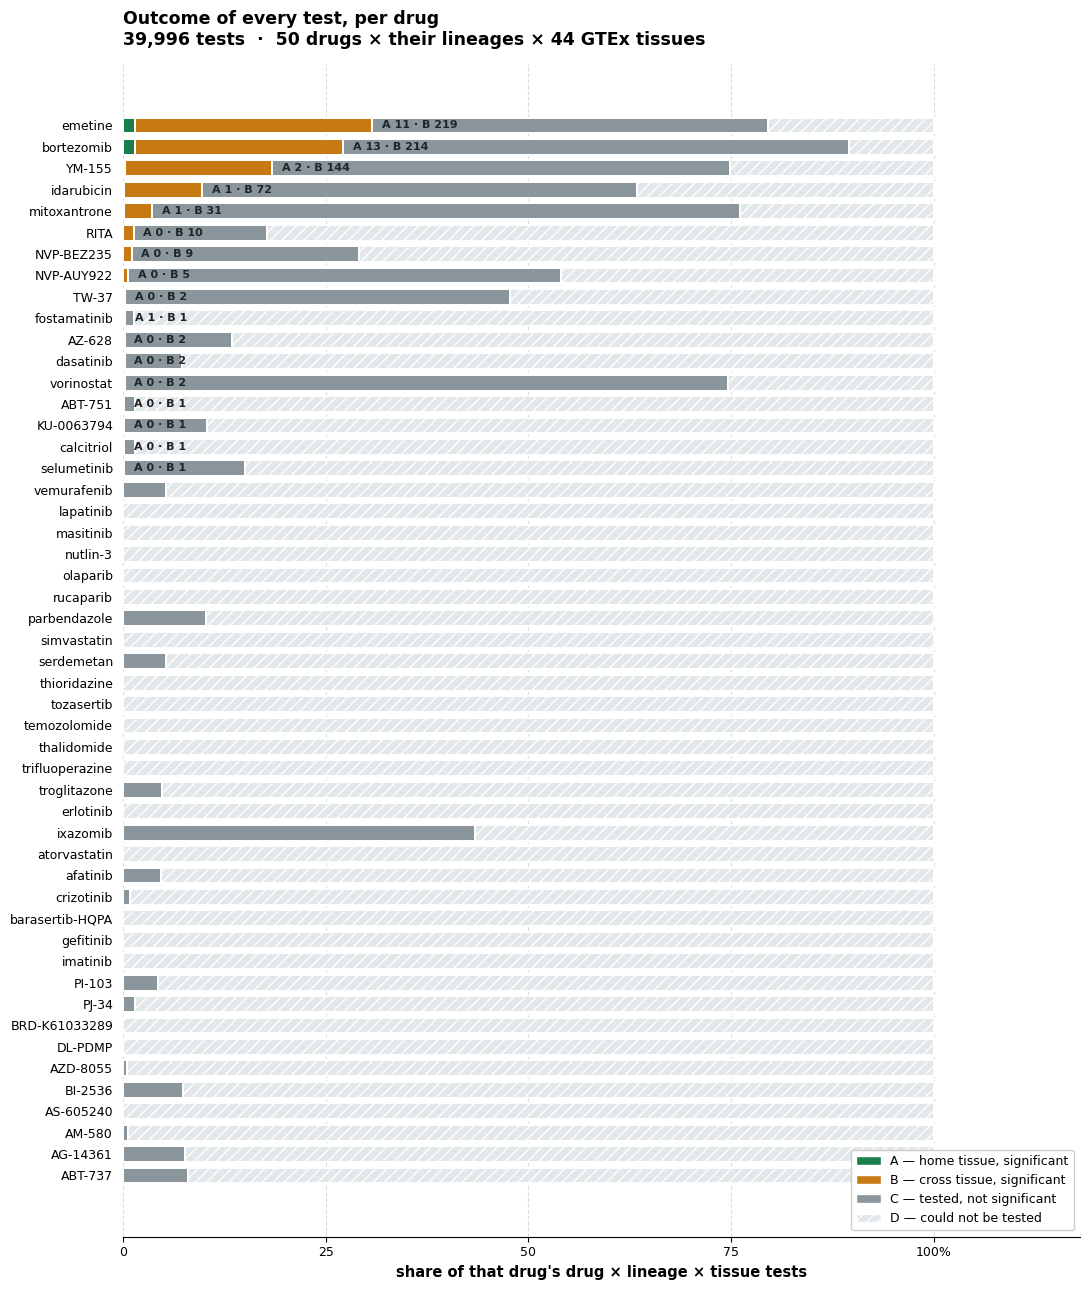

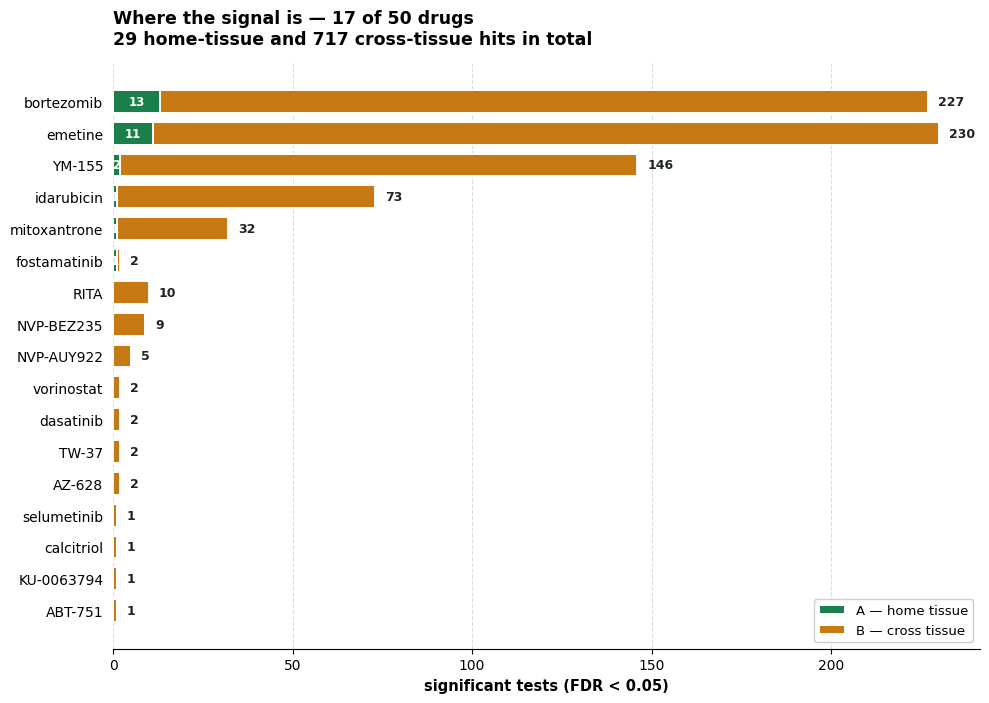

A 29 | B 717 | C 5376 | D 33874


In [26]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ---- palette: A/B carry meaning, C/D are recessive "no result" states ----
COL = {'A': '#1B7F4B',    # green  — home significant
       'B': '#C77A14',    # amber  — cross significant
       'C': '#8A959C',    # slate  — tested, nothing
       'D': '#E2E7EA'}    # pale   — could not test
INK, GRID = '#1F2427', '#D8DEE1'

cnt = sig_table.pivot_table(index='drug', columns='category',
                            values='tissue', aggfunc='count', fill_value=0)
for c in ['A', 'B', 'C', 'D']:
    if c not in cnt.columns:
        cnt[c] = 0
cnt = cnt[['A', 'B', 'C', 'D']]
cnt['total']  = cnt.sum(axis=1)
cnt['n_hits'] = cnt['A'] + cnt['B']

# =====================================================================
# FIGURE 1 — all 50 drugs, share of each outcome
# =====================================================================
p = cnt[['A','B','C','D']].div(cnt['total'], axis=0) * 100
order = (cnt['n_hits'] / cnt['total']).sort_values().index
p, c1 = p.loc[order], cnt.loc[order]

fig, ax = plt.subplots(figsize=(11, 13))
y, left = np.arange(len(p)), np.zeros(len(p))
for k in ['A', 'B', 'C', 'D']:
    ax.barh(y, p[k], 0.74, left=left, color=COL[k],
            edgecolor='white', linewidth=1.4,
            hatch='///' if k == 'D' else None)
    left += p[k].values

for i, d in enumerate(p.index):                      # direct labels on findings
    if c1.loc[d, 'n_hits'] > 0:
        ax.text(p.loc[d, ['A','B']].sum() + 1.2, i,
                f"A {c1.loc[d,'A']} · B {c1.loc[d,'B']}",
                va='center', fontsize=8, color=INK, fontweight='bold')

ax.set_yticks(y); ax.set_yticklabels(p.index, fontsize=9)
ax.set_xlim(0, 118); ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticklabels(['0', '25', '50', '75', '100%'], fontsize=9)
ax.set_xlabel('share of that drug\'s drug × lineage × tissue tests',
              fontsize=10.5, fontweight='bold')
ax.set_title('Outcome of every test, per drug\n'
             f'{len(sig_table):,} tests  ·  50 drugs × their lineages × 44 GTEx tissues',
             fontsize=12.5, fontweight='bold', loc='left', pad=14)
ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(left=False)
ax.legend(handles=[
    Patch(fc=COL['A'], ec='white', label='A — home tissue, significant'),
    Patch(fc=COL['B'], ec='white', label='B — cross tissue, significant'),
    Patch(fc=COL['C'], ec='white', label='C — tested, not significant'),
    Patch(fc=COL['D'], ec='white', hatch='///', label='D — could not be tested')],
    loc='lower right', fontsize=9, framealpha=.96)
plt.tight_layout()
plt.savefig(f'{BASE}/figures/ABCD_all50_share.png', dpi=170, bbox_inches='tight')
plt.show()

# =====================================================================
# FIGURE 2 — only the drugs that actually found something
# =====================================================================
h = cnt[cnt['n_hits'] > 0].sort_values(['A', 'B'])
fig, ax = plt.subplots(figsize=(10, max(5, 0.42 * len(h))))
y = np.arange(len(h))
ax.barh(y, h['A'], 0.72, color=COL['A'], edgecolor='white', linewidth=1.4,
        label='A — home tissue')
ax.barh(y, h['B'], 0.72, left=h['A'], color=COL['B'], edgecolor='white',
        linewidth=1.4, label='B — cross tissue')

for i, d in enumerate(h.index):                       # every bar labelled
    a, b = h.loc[d, 'A'], h.loc[d, 'B']
    if a: ax.text(a/2, i, str(a), va='center', ha='center',
                  fontsize=8.5, color='white', fontweight='bold')
    ax.text(a + b + max(h['n_hits'])*0.012, i, f"{a+b}",
            va='center', fontsize=9, color=INK, fontweight='bold')

ax.set_yticks(y); ax.set_yticklabels(h.index, fontsize=10)
ax.set_xlabel('significant tests (FDR < 0.05)', fontsize=10.5, fontweight='bold')
ax.set_title(f'Where the signal is — {len(h)} of 50 drugs\n'
             f'{int(cnt["A"].sum())} home-tissue and {int(cnt["B"].sum())} '
             f'cross-tissue hits in total',
             fontsize=12.5, fontweight='bold', loc='left', pad=14)
ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(left=False)
ax.legend(loc='lower right', fontsize=9.5, framealpha=.96)
plt.tight_layout()
plt.savefig(f'{BASE}/figures/ABCD_hits_only.png', dpi=170, bbox_inches='tight')
plt.show()

print(f"A {int(cnt['A'].sum())} | B {int(cnt['B'].sum())} | "
      f"C {int(cnt['C'].sum())} | D {int(cnt['D'].sum())}")

In [28]:
import gseapy

In [29]:
need = ['gctx_file','gctx_sigs','sig_known','gid_to_ensg','ENS2SYM',
        'split_sets','_running_es','_leading_edge','sbg','cmap_to_gtex','BASE']
missing = [n for n in need if n not in globals()]
print("MISSING:" , missing if missing else "kuch nahi — chala sakti ho")

MISSING: ['ENS2SYM', 'split_sets', '_running_es', '_leading_edge', 'sbg']


In [34]:
DRUG, LIN = 'bortezomib', 'haematopoietic_and_lymphoid_tissue'
T_ISSUE   = 'Cells_EBV.transformed_lymphocytes'

s = sig_known[(sig_known['cmap_name'] == DRUG) &
              (sig_known['cell_lineage'] == LIN)].copy()
s = s[s['sig_id'].isin(gctx_sigs)]

cols = [c for c in ['sig_id','cell_iname','donor_sex','pert_idose','pert_itime',
                    'tas','cc_q75','ss_ngene','nsample','is_exemplar_sig','qc_pass']
        if c in s.columns]

print(f"{len(s)} signatures for {DRUG} × {LIN}\n")
print("--- 10 best by TAS (signature quality) ---")
print(s.sort_values('tas', ascending=False)[cols].head(10).to_string(index=False))

print("\n--- donor sex ---")
print(s['donor_sex'].value_counts(dropna=False).to_string())
print("\n--- cell lines ---")
print(s['cell_iname'].value_counts().head(10).to_string())

255 signatures for bortezomib × haematopoietic_and_lymphoid_tissue

--- 10 best by TAS (signature quality) ---
                 sig_id cell_iname donor_sex pert_idose pert_itime      tas  cc_q75  ss_ngene  nsample  is_exemplar_sig  qc_pass
  AICHI002_BJAB_24H:I09       BJAB         F    0.66 uM       24 h 0.878981  0.8900       849        3                0        0
   EMU001_NALM6_24H:C05      NALM6         M    0.04 uM       24 h 0.872665  0.8835       843        3                0        0
    EMU001_TMD8_24H:C05       TMD8         M    0.04 uM       24 h 0.856906  0.8844       812        2                0        0
  AICHI002_BJAB_24H:I10       BJAB         F   0.125 uM       24 h 0.846139  0.9000       778        3                0        0
    EMU001_TMD8_24H:C06       TMD8         M    0.01 uM       24 h 0.838156  0.8730       787        3                0        0
AICHI002_OCILY3_24H:I12     OCILY3         M    0.01 uM       24 h 0.836991  0.8469       809        3             

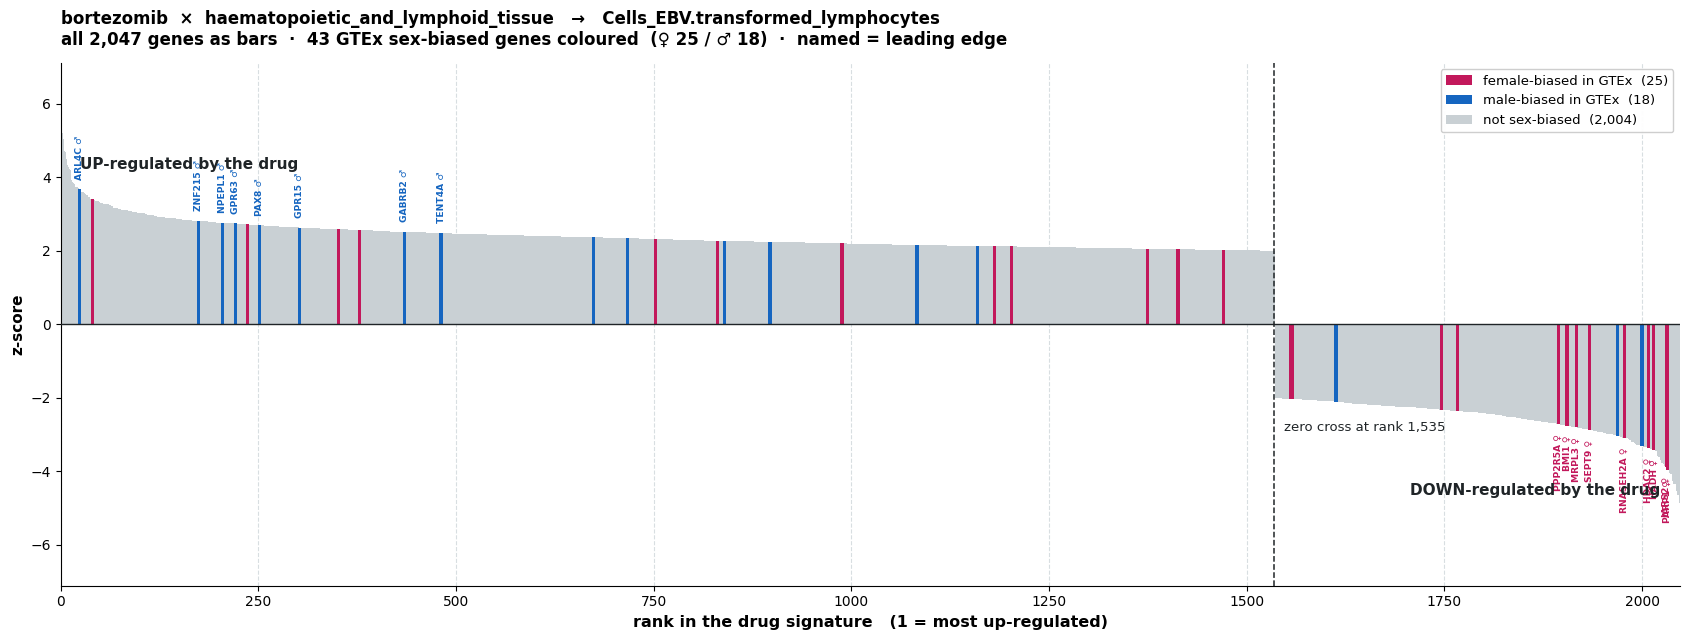

saved: /content/drive/MyDrive/Project59/figures/allbars_bortezomib_haematopoiet_Cells_EBV.transf_filtered.png


In [61]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# (ALL upar wali cell se aata hai — wo pehle chala lo)

x    = ALL['rank'].values
z    = ALL['z'].values
zmax = np.abs(z).max()

fig, ax = plt.subplots(figsize=(17, 6.5))

# 1. saare genes — patli grey bars
ax.bar(x, z, width=1.0, color='#C9D0D4', linewidth=0, zorder=1)

# 2. sex-biased genes — moti rangeen bars, upar draw
for sx, col in [('M', M_COL), ('F', F_COL)]:
    sub = ALL[ALL['sex'] == sx]
    ax.bar(sub['rank'], sub['z'], width=4.0, color=col,
           linewidth=0, zorder=3 if sx == 'F' else 2)

ax.axhline(0, color=INK, lw=1.0, zorder=4)

zero = int((ALL['z'] > 0).sum())
ax.axvline(zero, color=INK, ls='--', lw=1.1, zorder=4)
ax.text(zero + len(x)*.006, -zmax*.55, f'zero cross at rank {zero:,}',
        fontsize=9.5, color=INK)

# leading-edge genes ke naam
lead = ALL[ALL['LE']].copy()
for j, r in enumerate(lead.itertuples()):
    col = F_COL if r.sex == 'F' else M_COL
    ax.text(r.rank, r.z + (zmax*.05 if r.z > 0 else -zmax*.05),
            f"{r.gene} {'\u2640' if r.sex=='F' else '\u2642'}",
            rotation=90, fontsize=6.6, color=col, fontweight='bold',
            ha='center', va='bottom' if r.z > 0 else 'top')

ax.text(len(x)*.012,  zmax*.80, 'UP-regulated by the drug', fontsize=11,
        color=INK, fontweight='bold')
ax.text(len(x)*.988, -zmax*.88, 'DOWN-regulated by the drug', fontsize=11,
        color=INK, fontweight='bold', ha='right')

nF, nM = (ALL['sex'] == 'F').sum(), (ALL['sex'] == 'M').sum()
ax.set_xlim(0, len(x) + 1); ax.set_ylim(-zmax*1.35, zmax*1.35)
ax.set_xlabel('rank in the drug signature   (1 = most up-regulated)',
              fontsize=11.5, fontweight='bold')
ax.set_ylabel('z-score', fontsize=11, fontweight='bold')
ax.set_title(f'{DRUG}  ×  {LIN}   →   {T_ISSUE}\n'
             f'all {len(ALL):,} genes as bars  ·  '
             f'{nF + nM} GTEx sex-biased genes coloured  '
             f'(\u2640 {nF} / \u2642 {nM})  ·  named = leading edge',
             fontsize=12, fontweight='bold', loc='left', pad=13)
ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[
    Patch(fc=F_COL,     label=f'female-biased in GTEx  ({nF})'),
    Patch(fc=M_COL,     label=f'male-biased in GTEx  ({nM})'),
    Patch(fc='#C9D0D4', label=f'not sex-biased  ({len(ALL)-nF-nM:,})')],
    loc='upper right', fontsize=9.5, framealpha=.96)

plt.tight_layout()
fn = f'{BASE}/figures/allbars_{DRUG}_{LIN[:12]}_{T_ISSUE[:16]}_{MODE}.png'
plt.savefig(fn, dpi=180, bbox_inches='tight')
plt.show()
print("saved:", fn)

In [60]:
V1, src = build_V1(DRUG, LIN, 'filtered')
G  = _gsea(V1, T_ISSUE, quiet=True)
kF, kM = G['kF'], G['kM']
Fset, Mset = set(G['gs'][kF]), set(G['gs'][kM])

t = sbg[sbg['tissue'] == T_ISSUE].copy()
t['ens'] = t['gene'].astype(str).str.split('.').str[0]
eff = t.groupby('ens')['effsize'].mean()
le  = ({V1.index[i] for i in G['leF']} | {V1.index[i] for i in G['leM']})

ALL = pd.DataFrame({'rank': np.arange(1, len(V1) + 1),
                    'ens': V1.index, 'z': V1.values})
ALL['gene'] = ALL['ens'].map(lambda g: ENS2SYM.get(g, g))
ALL['sex']  = np.where(ALL['ens'].isin(Fset), 'F',
              np.where(ALL['ens'].isin(Mset), 'M', ''))
ALL['eff']  = ALL['ens'].map(eff)
ALL['LE']   = ALL['ens'].isin(le)

out = f'{BASE}/results/all_genes_{DRUG}_{LIN[:12]}_{T_ISSUE[:16]}_filtered.csv'
ALL[['rank','gene','z','sex','eff','LE']].to_csv(out, index=False)
print(f"saare {len(ALL):,} genes saved: {out}\n")

print(f"sex-biased : {(ALL['sex'] != '').sum()}   "
      f"(F {(ALL['sex']=='F').sum()} / M {(ALL['sex']=='M').sum()})\n")
print("saare sex-biased genes, rank ke hisaab se:")
print(ALL[ALL['sex'] != ''][['rank','gene','z','sex','eff','LE']]
        .to_string(index=False))

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


   |z| > 2 filter : 12,328 -> 2,059 genes
saare 2,047 genes saved: /content/drive/MyDrive/Project59/results/all_genes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv

sex-biased : 43   (F 25 / M 18)

saare sex-biased genes, rank ke hisaab se:
 rank     gene         z sex       eff    LE
   24    ARL4C  3.670063   M -0.238940  True
   40     XIST  3.402932   F 11.081655 False
  174   ZNF215  2.816474   M -0.126656  True
  205   NPEPL1  2.763776   M -0.058401  True
  221    GPR63  2.746092   M -0.161356  True
  236   PRSS16  2.722288   F  0.237137 False
  251     PAX8  2.694363   M -0.382815  True
  302    GPR15  2.631033   M -0.061961  True
  351   CA5BP1  2.592278   F  0.334745 False
  378      CA4  2.573224   F  0.187873 False
  435   GABRB2  2.514840   M -0.695495  True
  481   TENT4A  2.482184   M -0.033721  True
  674 KIAA0556  2.366217   M -0.070973 False
  717    LMTK2  2.342661   M -0.031844 False
  752 SLC26A10  2.323413   F  0.112020 False
  831     INE1  2.273709   F  0

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


   |z| > 2 filter : 12,328 -> 2,059 genes
255 signatures  ·  cell line 15 lines  ·  donor F/M   [filtered]
total genes : 2,047
sex-biased  : 43   (F 25 / M 18)
saved       : /content/drive/MyDrive/Project59/results/allgenes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv



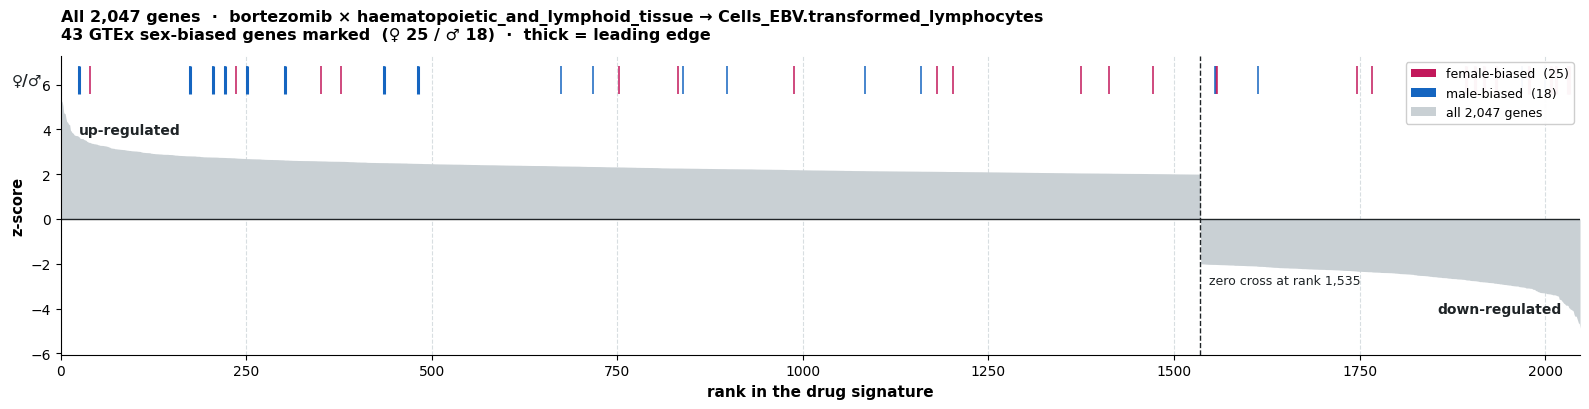


saare sex-biased genes, rank ke hisaab se:
 rank     gene         z sex       eff    LE
   24    ARL4C  3.670063   M -0.238940  True
   40     XIST  3.402932   F 11.081655 False
  174   ZNF215  2.816474   M -0.126656  True
  205   NPEPL1  2.763776   M -0.058401  True
  221    GPR63  2.746092   M -0.161356  True
  236   PRSS16  2.722288   F  0.237137 False
  251     PAX8  2.694363   M -0.382815  True
  302    GPR15  2.631033   M -0.061961  True
  351   CA5BP1  2.592278   F  0.334745 False
  378      CA4  2.573224   F  0.187873 False
  435   GABRB2  2.514840   M -0.695495  True
  481   TENT4A  2.482184   M -0.033721  True
  674 KIAA0556  2.366217   M -0.070973 False
  717    LMTK2  2.342661   M -0.031844 False
  752 SLC26A10  2.323413   F  0.112020 False
  831     INE1  2.273709   F  0.289788 False
  839     E2F4  2.270716   M -0.044888 False
  897    NRDE2  2.245016   M -0.015330 False
  988     PRKX  2.202530   F  0.633654 False
 1083    PLCH2  2.157992   M -0.211902 False
 1159     T

In [59]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

DRUG    = 'bortezomib'
LIN     = 'haematopoietic_and_lymphoid_tissue'
T_ISSUE = 'Cells_EBV.transformed_lymphocytes'
MODE    = 'filtered'

# ---------- 1. saare genes ki table ----------
V1, src = build_V1(DRUG, LIN, MODE)
G = _gsea(V1, T_ISSUE, quiet=True)
kF, kM = G['kF'], G['kM']
Fset, Mset = set(G['gs'][kF]), set(G['gs'][kM])

t = sbg[sbg['tissue'] == T_ISSUE].copy()
t['ens'] = t['gene'].astype(str).str.split('.').str[0]
eff = t.groupby('ens')['effsize'].mean()
le  = ({V1.index[i] for i in G['leF']} | {V1.index[i] for i in G['leM']})

ALL = pd.DataFrame({'rank': np.arange(1, len(V1) + 1),
                    'ens': V1.index, 'z': V1.values})
ALL['gene'] = ALL['ens'].map(lambda g: ENS2SYM.get(g, g))
ALL['sex']  = np.where(ALL['ens'].isin(Fset), 'F',
              np.where(ALL['ens'].isin(Mset), 'M', ''))
ALL['eff']  = ALL['ens'].map(eff)
ALL['LE']   = ALL['ens'].isin(le)

out = f'{BASE}/results/allgenes_{DRUG}_{LIN[:12]}_{T_ISSUE[:16]}_{MODE}.csv'
ALL[['rank','gene','z','sex','eff','LE']].to_csv(out, index=False)

nF, nM = (ALL['sex'] == 'F').sum(), (ALL['sex'] == 'M').sum()
print(f"{src}   [{MODE}]")
print(f"total genes : {len(ALL):,}")
print(f"sex-biased  : {nF + nM}   (F {nF} / M {nM})")
print(f"saved       : {out}\n")

# ---------- 2. ek patti mein saare genes ----------
fig, ax = plt.subplots(figsize=(16, 4.2))
x    = ALL['rank'].values
zmax = ALL['z'].abs().max()

ax.fill_between(x, ALL['z'].values, 0, color='#C9D0D4', linewidth=0, zorder=1)
ax.axhline(0, color=INK, lw=1.0)

for sx, col in [('F', F_COL), ('M', M_COL)]:
    sub  = ALL[ALL['sex'] == sx]
    ax.vlines(sub['rank'],  zmax*1.06, zmax*1.30, color=col, lw=1.1)
    ax.vlines(sub[sub['LE']]['rank'], zmax*1.06, zmax*1.30, color=col, lw=2.2)

ax.text(-len(x)*.012, zmax*1.18, '\u2640/\u2642', fontsize=11,
        fontweight='bold', ha='right', va='center', color=INK)

zero = int((ALL['z'] > 0).sum())
ax.axvline(zero, color=INK, ls='--', lw=1.0)
ax.text(zero + len(x)*.006, -zmax*.55, f'zero cross at rank {zero:,}',
        fontsize=9, color=INK)
ax.text(len(x)*.012,  zmax*.72, 'up-regulated',   fontsize=10,
        color=INK, fontweight='bold')
ax.text(len(x)*.988, -zmax*.80, 'down-regulated', fontsize=10,
        color=INK, fontweight='bold', ha='right')

ax.set_xlim(0, len(x)); ax.set_ylim(-zmax*1.15, zmax*1.38)
ax.set_xlabel('rank in the drug signature', fontsize=11, fontweight='bold')
ax.set_ylabel('z-score', fontsize=10.5, fontweight='bold')
ax.set_title(f'All {len(ALL):,} genes  ·  {DRUG} × {LIN} → {T_ISSUE}\n'
             f'{nF + nM} GTEx sex-biased genes marked  '
             f'(\u2640 {nF} / \u2642 {nM})  ·  thick = leading edge',
             fontsize=11.5, fontweight='bold', loc='left', pad=12)
ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
ax.legend(handles=[
    Patch(fc=F_COL,      label=f'female-biased  ({nF})'),
    Patch(fc=M_COL,      label=f'male-biased  ({nM})'),
    Patch(fc='#C9D0D4',  label=f'all {len(ALL):,} genes')],
    loc='upper right', fontsize=9, framealpha=.96)

plt.tight_layout()
plt.savefig(f'{BASE}/figures/allgenes_strip_{DRUG}_{T_ISSUE[:16]}_{MODE}.png',
            dpi=170, bbox_inches='tight')
plt.show()

print("\nsaare sex-biased genes, rank ke hisaab se:")
print(ALL[ALL['sex'] != ''][['rank','gene','z','sex','eff','LE']]
        .to_string(index=False))

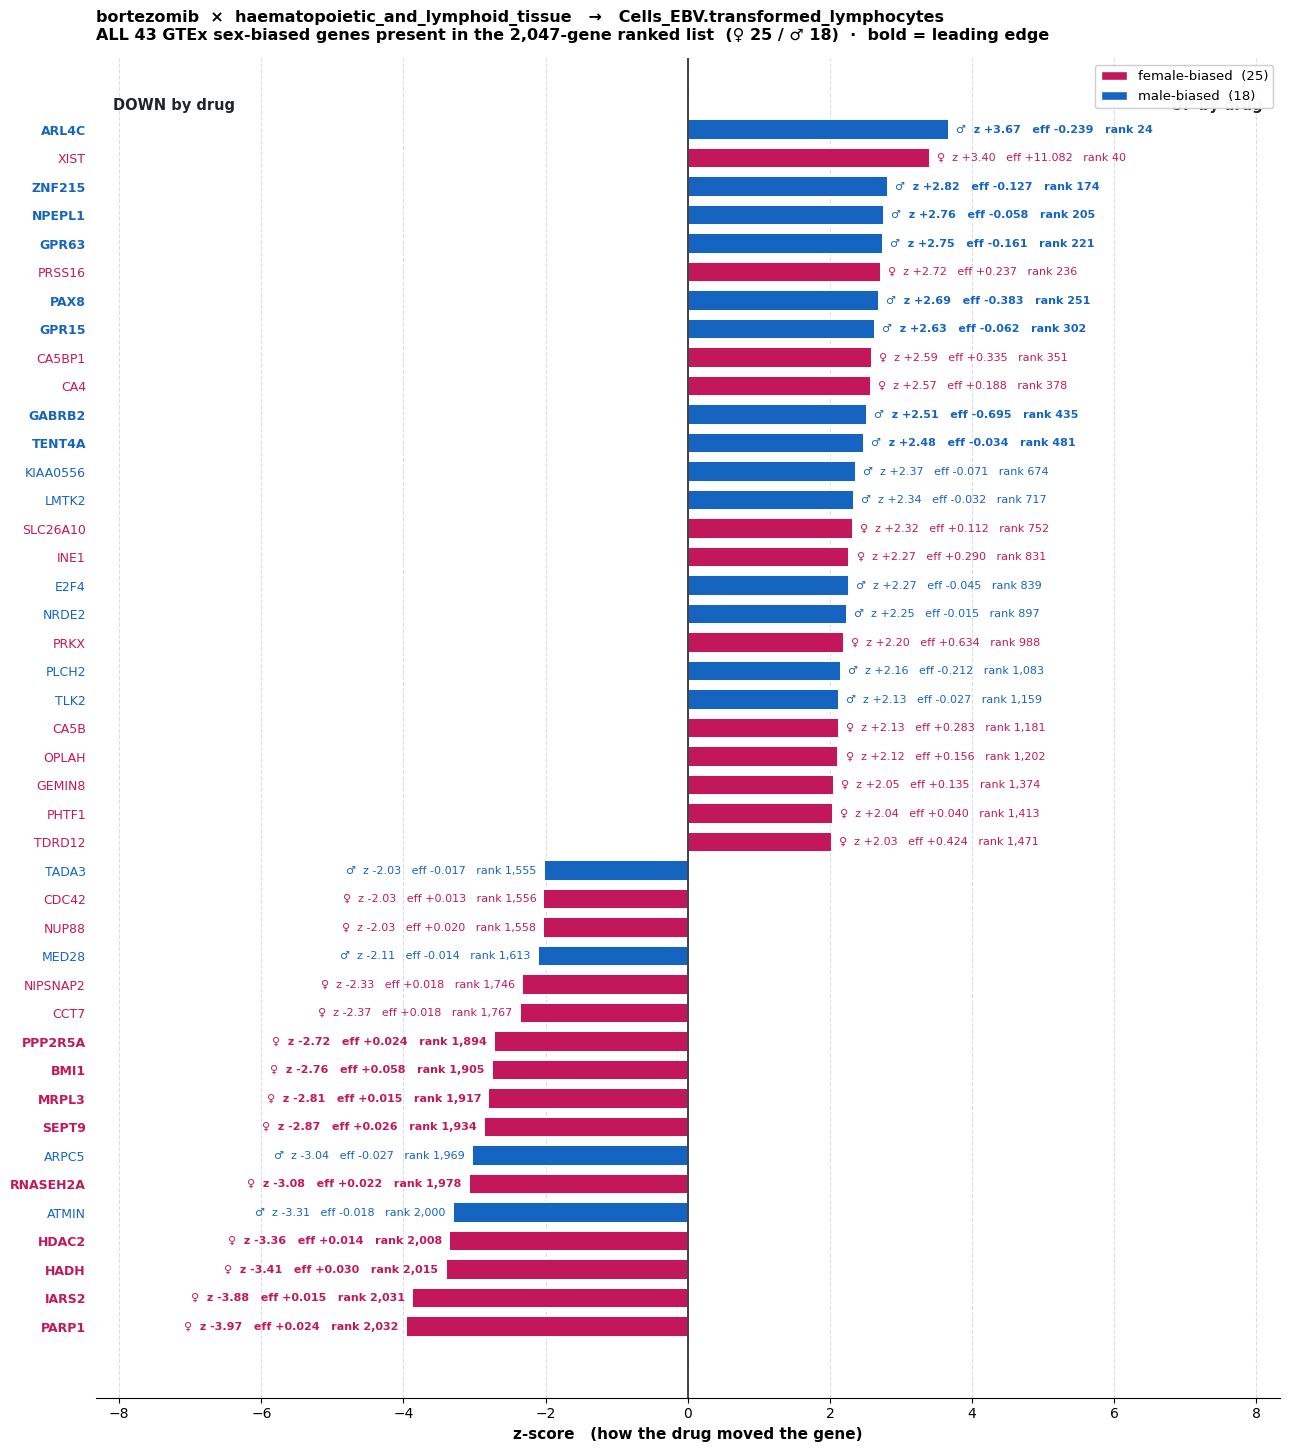

saved: /content/drive/MyDrive/Project59/figures/all_sexgenes_bortezomib_Cells_EBV.transf_filtered.png

43 genes shown — 2,047 mein se saare sex-biased


In [62]:
# ALL upar wali cell se aana chahiye
sb = ALL[ALL['sex'] != ''].sort_values('z').reset_index(drop=True)

y    = np.arange(len(sb))
cols = [F_COL if s_ == 'F' else M_COL for s_ in sb['sex']]

fig, ax = plt.subplots(figsize=(13, max(7, 0.34 * len(sb))))
ax.barh(y, sb['z'], 0.72, color=cols, edgecolor='white', linewidth=1.4)
ax.axvline(0, color=INK, lw=1.2)
pad = sb['z'].abs().max() * 2.1
ax.set_xlim(-pad, pad)

for i, r in enumerate(sb.itertuples()):
    c = F_COL if r.sex == 'F' else M_COL
    ax.text(r.z + (0.10 if r.z > 0 else -0.10), i,
            f"{'\u2640' if r.sex=='F' else '\u2642'}  z {r.z:+.2f}   "
            f"eff {r.eff:+.3f}   rank {r.rank:,}",
            va='center', ha='left' if r.z > 0 else 'right',
            fontsize=8, color=c, fontweight='bold' if r.LE else 'normal')

ax.set_yticks(y); ax.set_yticklabels(sb['gene'], fontsize=9)
for lab, s_, le_ in zip(ax.get_yticklabels(), sb['sex'], sb['LE']):
    lab.set_color(F_COL if s_ == 'F' else M_COL)
    if le_: lab.set_fontweight('bold')

nF, nM = (sb['sex'] == 'F').sum(), (sb['sex'] == 'M').sum()
ax.set_xlabel('z-score   (how the drug moved the gene)',
              fontsize=11, fontweight='bold')
ax.set_title(f'{DRUG}  ×  {LIN}   →   {T_ISSUE}\n'
             f'ALL {len(sb)} GTEx sex-biased genes present in the '
             f'{len(ALL):,}-gene ranked list  (\u2640 {nF} / \u2642 {nM})  ·  '
             f'bold = leading edge',
             fontsize=11.5, fontweight='bold', loc='left', pad=13)
ax.text(-pad*.97, len(sb)-.3, 'DOWN by drug', fontsize=10.5,
        color=INK, fontweight='bold')
ax.text( pad*.97, len(sb)-.3, 'UP by drug', fontsize=10.5,
        color=INK, fontweight='bold', ha='right')
ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(left=False)
ax.legend(handles=[
    Patch(fc=F_COL, ec='white', label=f'female-biased  ({nF})'),
    Patch(fc=M_COL, ec='white', label=f'male-biased  ({nM})')],
    loc='upper right', fontsize=9.5, framealpha=.96)

plt.tight_layout()
fn = f'{BASE}/figures/all_sexgenes_{DRUG}_{T_ISSUE[:16]}_{MODE}.png'
plt.savefig(fn, dpi=175, bbox_inches='tight')
plt.show()
print("saved:", fn)
print(f"\n{len(sb)} genes shown — 2,047 mein se saare sex-biased")

FILTERED  (|z| > 2)


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


library 473  (F 243 / M 230)   ->  matched 43  (F 25 / M 18)


/tmp/ipykernel_1808/2640957907.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_Cells_EBV.transfor_lineage_filtered.png


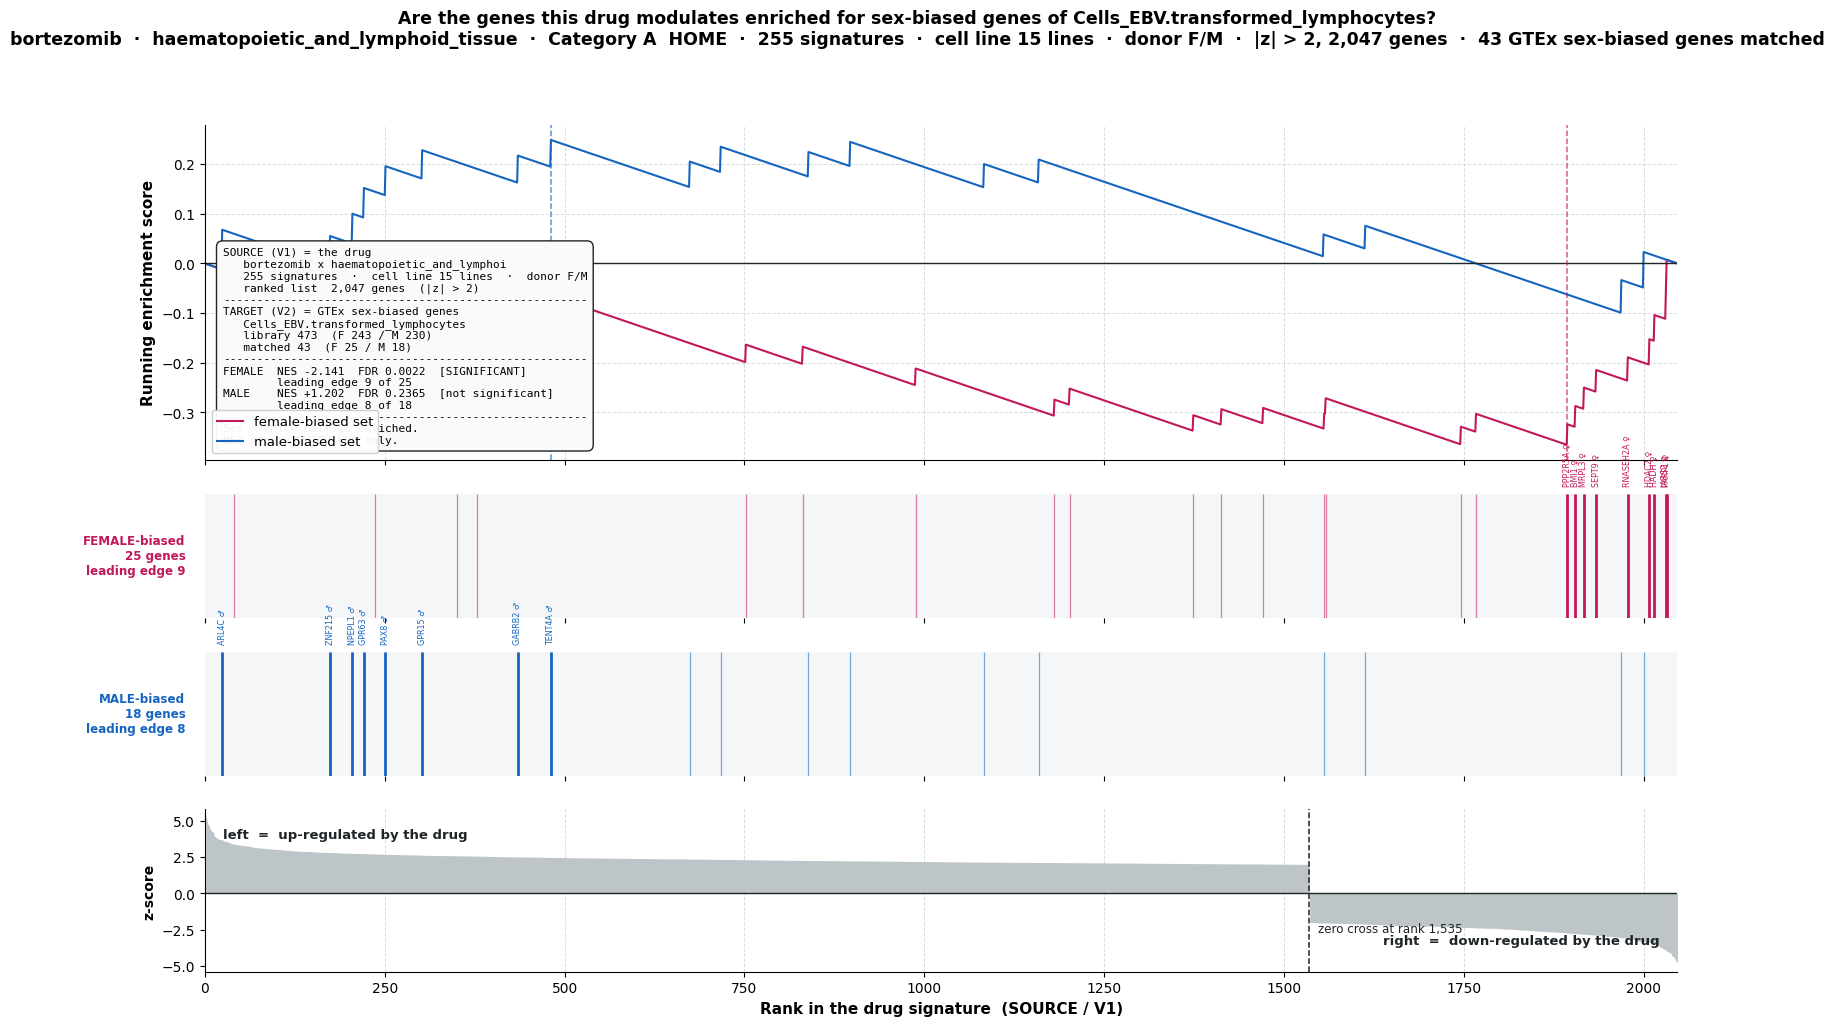


255 signatures  ·  cell line 15 lines  ·  donor F/M   [filtered]
FEMALE  NES -2.141  FDR 0.0022  SIGNIFICANT   (leading edge 9 of 25)
MALE    NES +1.202  FDR 0.2365  not significant   (leading edge 8 of 18)

FULL  (no filter)


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 13:41:21,576 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


library 473  (F 243 / M 230)   ->  matched 298  (F 162 / M 136)


/tmp/ipykernel_1808/2640957907.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_Cells_EBV.transfor_lineage_full.png


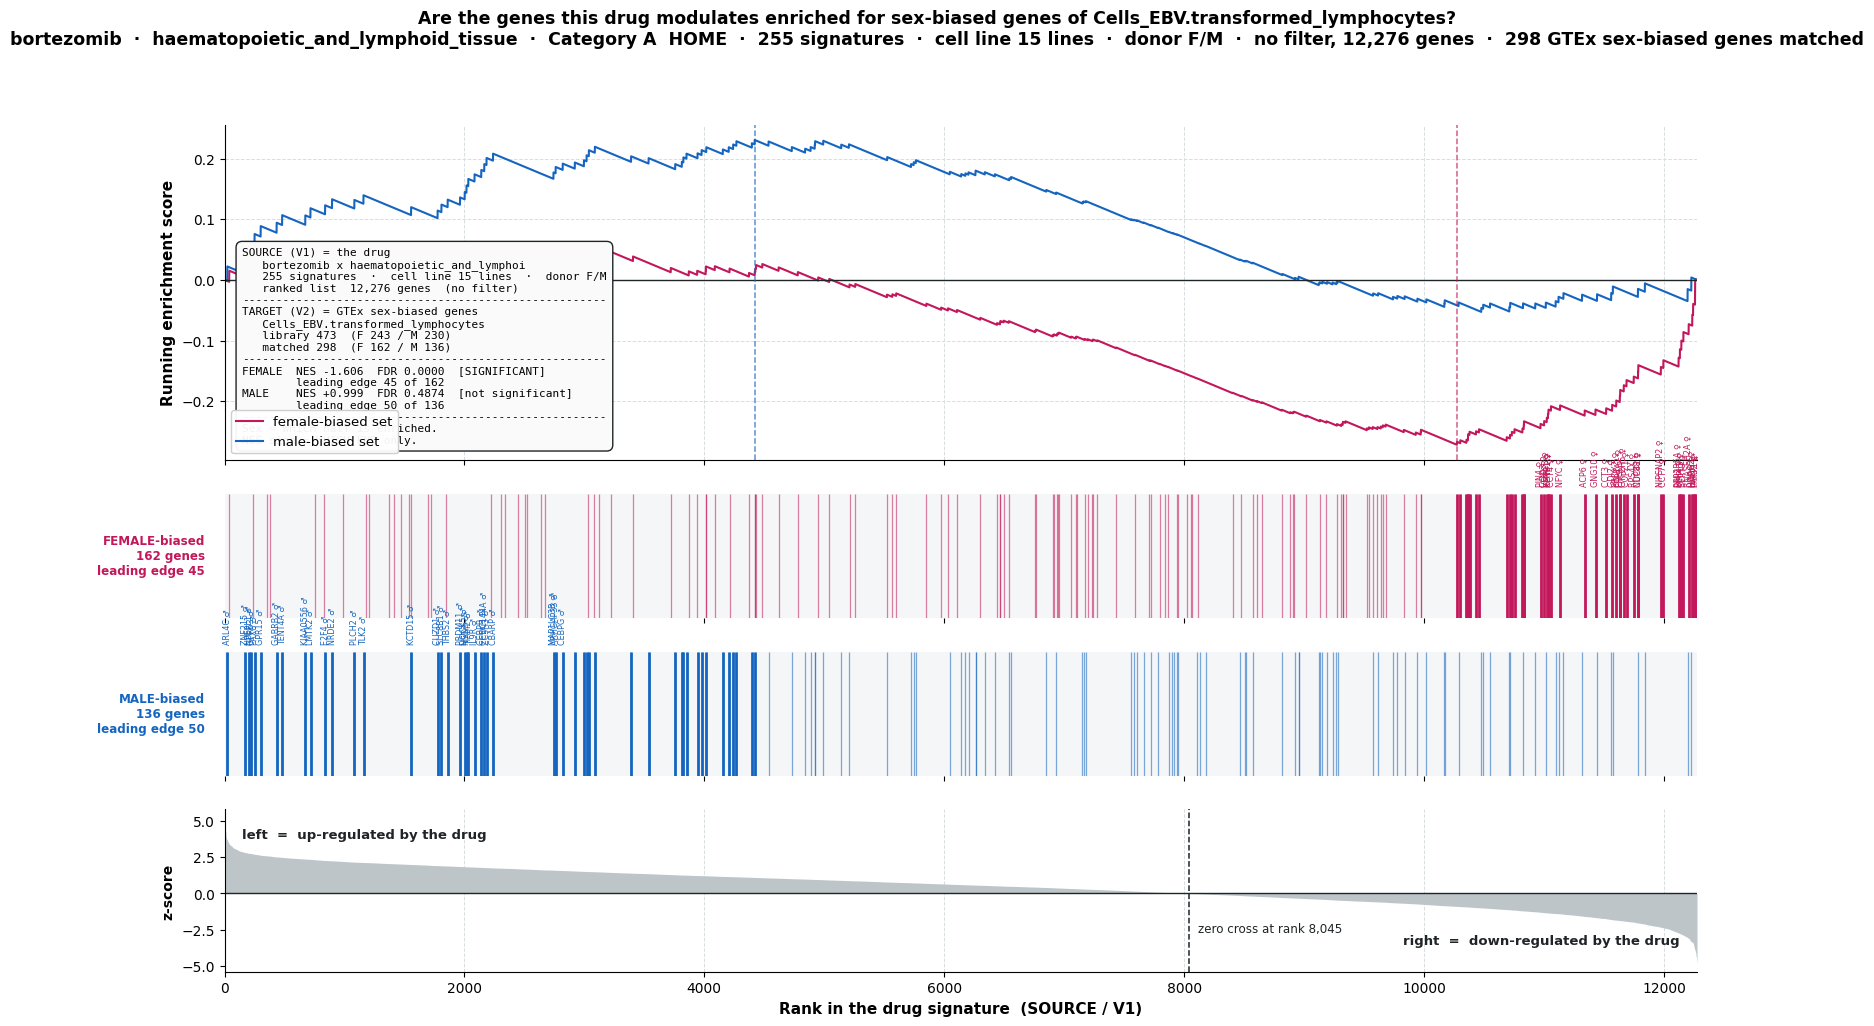


255 signatures  ·  cell line 15 lines  ·  donor F/M   [full]
FEMALE  NES -1.606  FDR 0.0000  SIGNIFICANT   (leading edge 45 of 162)
MALE    NES +0.999  FDR 0.4874  not significant   (leading edge 50 of 136)

DENSITY RATIOS


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))



[filtered]  ranked list 2,047   UP 1,535 (75%)   DOWN 512 (25%)
   set  matched  UP_obs  UP_exp  UP_ratio  DN_obs  DN_exp  DN_ratio
FEMALE       25      12    18.7      0.64      13     6.3      2.08
  MALE       18      14    13.5      1.04       4     4.5      0.89


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))



[full]  ranked list 12,276   UP 8,045 (66%)   DOWN 4,231 (34%)
   set  matched  UP_obs  UP_exp  UP_ratio  DN_obs  DN_exp  DN_ratio
FEMALE      162      86   106.2      0.81      76    55.8      1.36
  MALE      136      89    89.1      1.00      47    46.9      1.00

ratio 1.0 = chance   |   ratio > 1 = enriched


In [80]:
# ============================================================
#  GENE SET ENRICHMENT ANALYSIS  —  ek hi cell
#  bortezomib × blood lineage  →  Cells_EBV   (Category A, HOME)
#  definition + run + ratio table, sab ek saath
# ============================================================
import numpy as np, pandas as pd, gseapy
import matplotlib.pyplot as plt

# ---------- 0. zaroori cheezein maujood hain? ----------
need = ['build_V1', 'split_sets', '_running_es', '_leading_edge',
        'sbg', 'ENS2SYM', 'cmap_to_gtex', 'BASE']
missing = [n for n in need if n not in globals()]
if missing:
    raise NameError(f"pehle ye restore karo: {missing}")

F_COL = globals().get('F_COL', '#C2185B')
M_COL = globals().get('M_COL', '#1565C0')
INK   = globals().get('INK',   '#1F2427')
GRID  = globals().get('GRID',  '#D8DEE1')
GREY  = globals().get('GREY',  '#BDC5C9')


# ---------- 1. function ----------
def sex_enrichment(drug, lineage, tissue, mode='filtered', sig_id=None,
                   cell_line=None, n_perm=1000, min_set=15,
                   max_labels=30, save=True):

    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line, quiet=True)
    if V1 is None: return None

    halves = split_sets(tissue)
    Fkey, Mkey = f'{tissue}__FEMALE', f'{tissue}__MALE'
    idx    = set(V1.index)
    mF, mM = halves[Fkey] & idx, halves[Mkey] & idx
    libN   = len(halves[Fkey]) + len(halves[Mkey])

    print(f"library {libN:,}  (F {len(halves[Fkey]):,} / M {len(halves[Mkey]):,})"
          f"   ->  matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})")

    use = {k: v for k, v in halves.items() if len(v & idx) >= min_set}
    if not use:
        print(f"dono halves {min_set} se chhote — skip"); return None
    for k in halves:
        if k not in use:
            print(f"   SKIPPED (below {min_set}): {k} -> {len(halves[k] & idx)}")

    res = gseapy.prerank(rnk=V1, gene_sets=use, permutation_num=n_perm,
                         min_size=min_set, max_size=100000, seed=42,
                         no_plot=True, verbose=False)
    r, stat = res.res2d.set_index('Term'), {}
    for key, lab in [(Fkey, 'F'), (Mkey, 'M')]:
        stat[lab] = ((float(r.loc[key, 'NES']), float(r.loc[key, 'NOM p-val']),
                      float(r.loc[key, 'FDR q-val'])) if key in r.index
                     else (np.nan, np.nan, np.nan))

    def walk(gs_):
        cum, hit = _running_es(V1, gs_)
        if hit.sum() == 0:
            return np.zeros(len(V1)), hit, 0, 0.0, np.array([], int)
        i, es, le = _leading_edge(cum, hit)
        return cum, hit, i, es, le

    cumF, hitF, iF, esF, leF = walk(halves[Fkey])
    cumM, hitM, iM, esM, leM = walk(halves[Mkey])

    z, x = V1.values, np.arange(1, len(V1) + 1)
    zero = int((z > 0).sum())
    home = set(cmap_to_gtex.get(lineage, []))
    sg   = lambda q: 'SIGNIFICANT' if (q == q and q < 0.05) else 'not significant'

    fig = plt.figure(figsize=(19, 11))
    gsp = fig.add_gridspec(4, 1, height_ratios=[3.1, 1.15, 1.15, 1.5], hspace=.18)

    ax = fig.add_subplot(gsp[0])
    ax.plot(x, cumF, color=F_COL, lw=1.5, label='female-biased set')
    ax.plot(x, cumM, color=M_COL, lw=1.5, label='male-biased set')
    ax.axhline(0, color=INK, lw=1.0)
    if hitF.sum(): ax.axvline(iF+1, color=F_COL, ls='--', lw=1.1, alpha=.7)
    if hitM.sum(): ax.axvline(iM+1, color=M_COL, ls='--', lw=1.1, alpha=.7)
    ax.set_ylabel('Running enrichment score', fontsize=11, fontweight='bold')
    ax.set_xlim(0, len(V1)); ax.set_xticklabels([])
    ax.grid(color=GRID, lw=.7, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(loc='lower left', fontsize=9.5, framealpha=.95)
    ax.text(.012, .045,
        f"SOURCE (V1) = the drug\n   {drug} x {lineage[:26]}\n   {src}\n"
        f"   ranked list  {len(V1):,} genes  "
        f"({'no filter' if mode=='full' else '|z| > 2'})\n{'-'*54}\n"
        f"TARGET (V2) = GTEx sex-biased genes\n   {tissue}\n"
        f"   library {libN:,}  (F {len(halves[Fkey]):,} / M {len(halves[Mkey]):,})\n"
        f"   matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})\n{'-'*54}\n"
        f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  "
        f"[{sg(stat['F'][2])}]\n        leading edge {len(leF)} of {int(hitF.sum())}\n"
        f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  "
        f"[{sg(stat['M'][2])}]\n        leading edge {len(leM)} of {int(hitM.sum())}\n"
        f"{'-'*54}\nSex = WHICH half is enriched.\nNES sign = WHICH END only.",
        transform=ax.transAxes, fontsize=8.0, family='monospace',
        va='bottom', ha='left',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='#FAFAFA',
                  edgecolor=INK, linewidth=1.0))

    for k, (hit, le, col, lab, tot) in enumerate([
            (hitF, leF, F_COL, 'FEMALE-biased', len(mF)),
            (hitM, leM, M_COL, 'MALE-biased',   len(mM))]):
        axb = fig.add_subplot(gsp[1+k])
        axb.vlines(np.where(hit)[0]+1, 0, 1, color=col, lw=.9, alpha=.55)
        if len(le):
            axb.vlines(le+1, 0, 1, color=col, lw=2.0)
            sel = le if len(le) <= max_labels else le[np.argsort(-np.abs(z[le]))][:max_labels]
            for i in sorted(sel):
                axb.text(i+1, 1.06,
                         f"{ENS2SYM.get(V1.index[i], V1.index[i])} "
                         f"{'\u2640' if col==F_COL else '\u2642'}",
                         rotation=90, fontsize=5.8, color=col, ha='center', va='bottom')
        axb.set_xlim(0, len(V1)); axb.set_ylim(0, 1)
        axb.set_yticks([]); axb.set_xticklabels([])
        axb.set_ylabel(f'{lab}\n{tot} genes\nleading edge {len(le)}',
                       fontsize=8.6, fontweight='bold', color=col, rotation=0,
                       ha='right', va='center', labelpad=14)
        axb.spines[['top','right','left','bottom']].set_visible(False)
        axb.set_facecolor('#F4F6F7')

    axz = fig.add_subplot(gsp[3])
    axz.fill_between(x, z, 0, color=GREY, lw=0)
    axz.axhline(0, color=INK, lw=1.0)
    axz.axvline(zero, color=INK, ls='--', lw=1.1)
    axz.text(zero + len(V1)*.006, z.min()*.55,
             f'zero cross at rank {zero:,}', fontsize=8.6, color=INK)
    axz.text(len(V1)*.012, z.max()*.72, 'left  =  up-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK)
    axz.text(len(V1)*.988, z.min()*.72, 'right  =  down-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK, ha='right')
    axz.set_xlim(0, len(V1))
    axz.set_ylabel('z-score', fontsize=10, fontweight='bold')
    axz.set_xlabel('Rank in the drug signature  (SOURCE / V1)',
                   fontsize=11, fontweight='bold')
    axz.grid(axis='x', color=GRID, lw=.7, ls='--'); axz.set_axisbelow(True)
    axz.spines[['top','right']].set_visible(False)

    fig.suptitle(
        f'Are the genes this drug modulates enriched for sex-biased genes of {tissue}?\n'
        f'{drug}  ·  {lineage}  ·  '
        f'Category {"A  HOME" if tissue in home else "B  CROSS"}  ·  {src}  ·  '
        f'{"no filter" if mode=="full" else "|z| > 2"}, {len(V1):,} genes  ·  '
        f'{len(mF)+len(mM)} GTEx sex-biased genes matched',
        fontsize=12.5, fontweight='bold', y=.985)

    plt.tight_layout(rect=[0, 0, 1, .955])
    tag = (sig_id or cell_line or 'lineage').replace(':', '_')
    if save:
        fn = f'{BASE}/figures/enrich_{drug}_{tissue[:18]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=165, bbox_inches='tight'); print("saved:", fn)
    plt.show()

    print(f"\n{src}   [{mode}]")
    print(f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  {sg(stat['F'][2])}"
          f"   (leading edge {len(leF)} of {int(hitF.sum())})")
    print(f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  {sg(stat['M'][2])}"
          f"   (leading edge {len(leM)} of {int(hitM.sum())})")
    return stat


# ---------- 2. RUN ----------
DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_A  = 'Cells_EBV.transformed_lymphocytes'

print("="*78); print("FILTERED  (|z| > 2)"); print("="*78)
sex_enrichment(DRUG, LIN, T_A, mode='filtered')

print("\n" + "="*78); print("FULL  (no filter)"); print("="*78)
sex_enrichment(DRUG, LIN, T_A, mode='full')


# ---------- 3. density ratio table ----------
print("\n" + "="*78); print("DENSITY RATIOS"); print("="*78)
for mode in ['filtered', 'full']:
    V1, src = build_V1(DRUG, LIN, mode, quiet=True)
    z, ens  = V1.values, V1.index
    up_n, dn_n, tot = int((z>0).sum()), int((z<0).sum()), len(V1)
    h = split_sets(T_A)
    rows = []
    for lab, S in [('FEMALE', h[f'{T_A}__FEMALE'] & set(ens)),
                   ('MALE',   h[f'{T_A}__MALE']   & set(ens))]:
        m = np.isin(ens, list(S))
        oU, oD = int((m & (z>0)).sum()), int((m & (z<0)).sum())
        eU, eD = len(S)*up_n/tot, len(S)*dn_n/tot
        rows.append(dict(set=lab, matched=len(S),
                         UP_obs=oU, UP_exp=round(eU,1), UP_ratio=round(oU/eU,2),
                         DN_obs=oD, DN_exp=round(eD,1), DN_ratio=round(oD/eD,2)))
    print(f"\n[{mode}]  ranked list {tot:,}   "
          f"UP {up_n:,} ({100*up_n/tot:.0f}%)   DOWN {dn_n:,} ({100*dn_n/tot:.0f}%)")
    print(pd.DataFrame(rows).to_string(index=False))
print("\nratio 1.0 = chance   |   ratio > 1 = enriched")

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


   |z| > 2 filter : 12,328 -> 2,059 genes
saved: /content/drive/MyDrive/Project59/figures/highlight_bortezomib_haematopoiet_Cells_EBV.transf_lineage_filtered.png


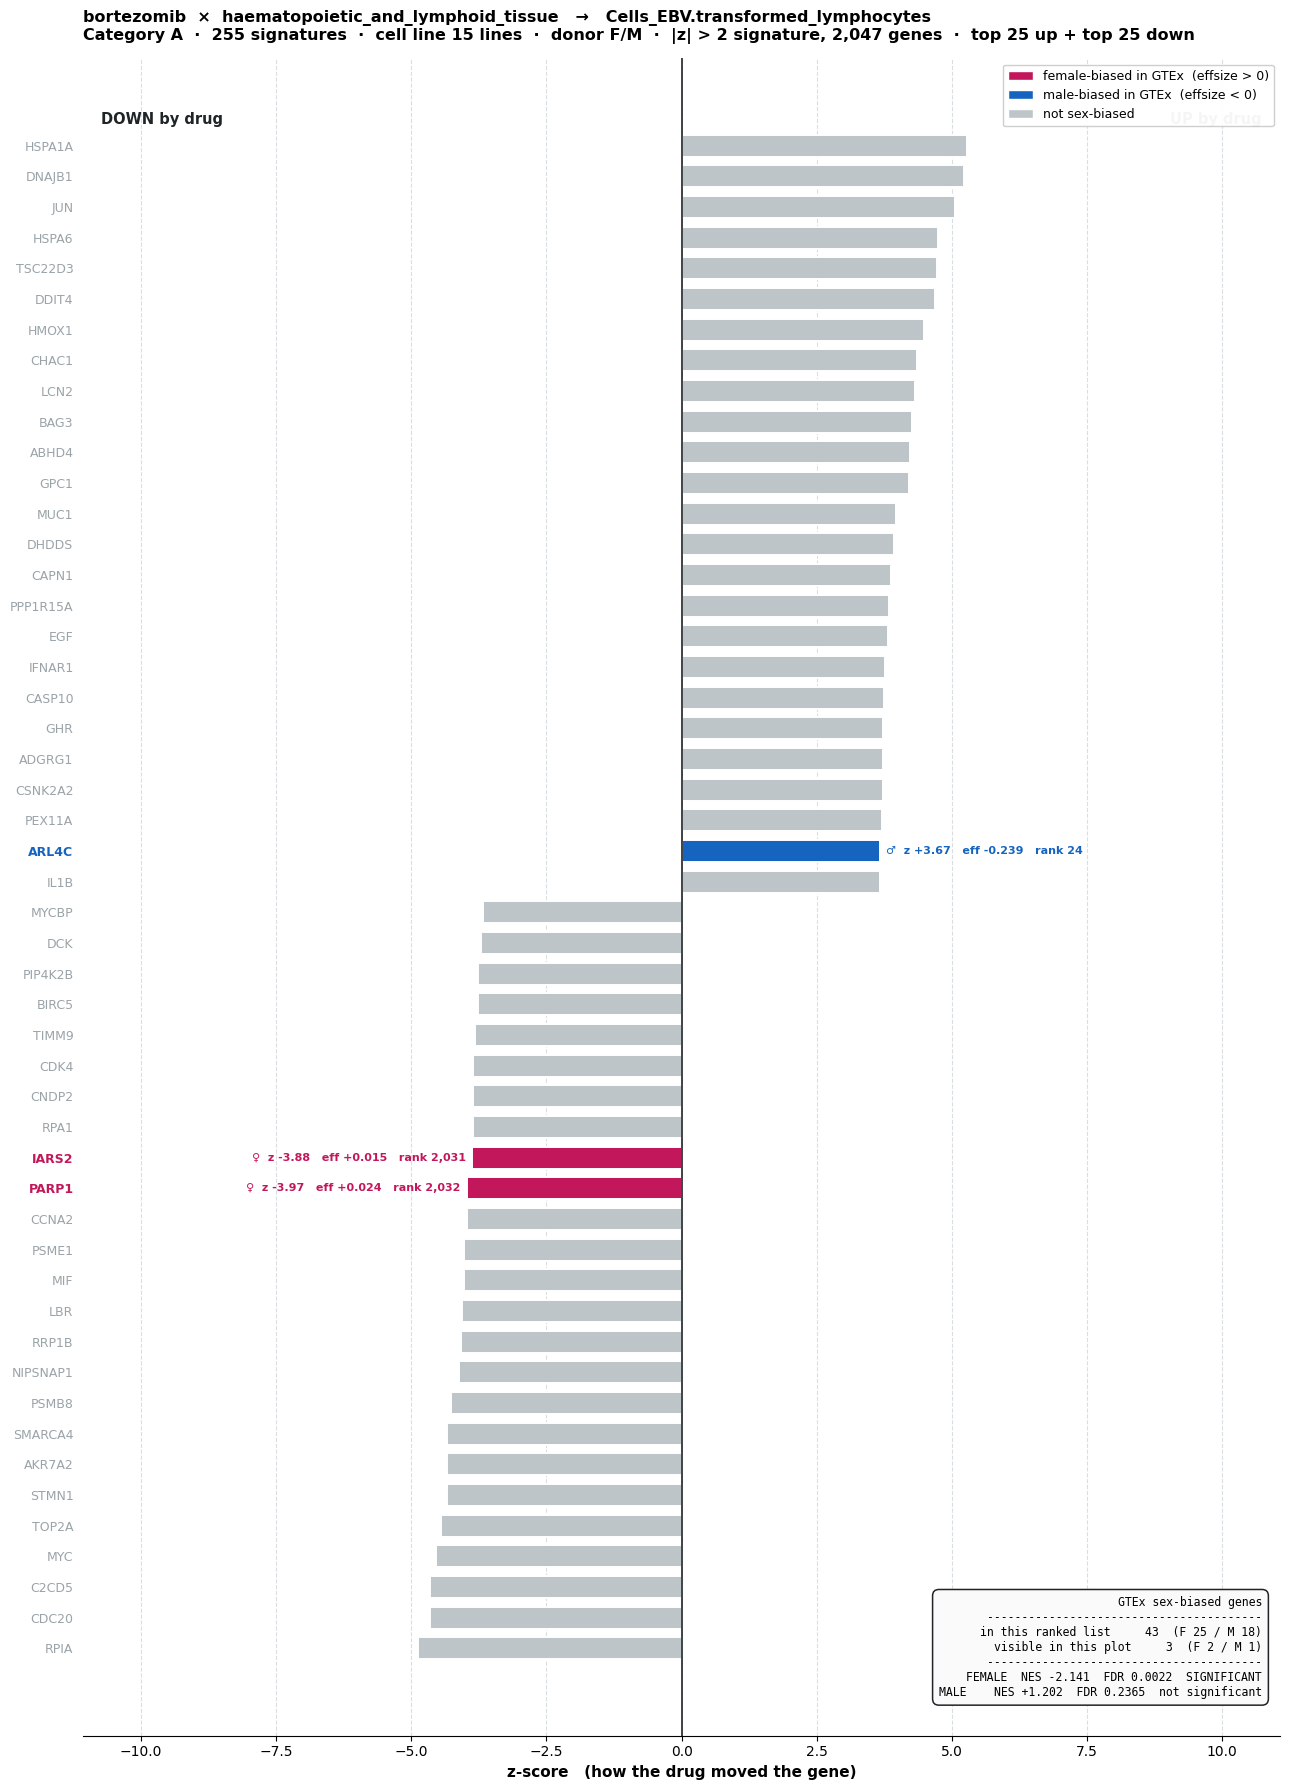


255 signatures  ·  cell line 15 lines  ·  donor F/M   [filtered]
sex-biased in ranked list : 43 (F 25 / M 18)
visible in top 25+25    : 3 (F 2 / M 1)


In [46]:
def sex_bar_highlight(drug, lineage, tissue, mode='filtered', sig_id=None,
                      cell_line=None, top_n=25, n_perm=1000, save=True):
    """Drug ke top up + top down genes. Sex-biased pink/blue, baaki grey."""
    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line)
    if V1 is None: return None
    G = _gsea(V1, tissue, n_perm)
    if G is None: return None

    kF, kM, gs, stat = G['kF'], G['kM'], G['gs'], G['stat']
    Fset, Mset = set(gs[kF]), set(gs[kM])

    t = sbg[sbg['tissue'] == tissue].copy()
    t['ens'] = t['gene'].astype(str).str.split('.').str[0]
    eff = t.groupby('ens')['effsize'].mean()
    le  = ({V1.index[i] for i in G['leF']} | {V1.index[i] for i in G['leM']})

    D = pd.DataFrame({'ens': V1.index, 'z': V1.values})
    D['rank'] = np.arange(1, len(D) + 1)
    D['gene'] = D['ens'].map(lambda g: ENS2SYM.get(g, g))
    D['sex']  = np.where(D['ens'].isin(Fset), 'F',
                np.where(D['ens'].isin(Mset), 'M', ''))
    D['eff']  = D['ens'].map(eff)
    D['LE']   = D['ens'].isin(le)

    shown = pd.concat([D.head(top_n), D.tail(top_n)]).sort_values('z')
    y = np.arange(len(shown))
    cols = [F_COL if s_ == 'F' else M_COL if s_ == 'M' else GREY
            for s_ in shown['sex']]

    fig, ax = plt.subplots(figsize=(13, max(7, 0.36 * len(shown))))
    ax.barh(y, shown['z'], 0.72, color=cols, edgecolor='white', linewidth=1.4)
    ax.axvline(0, color=INK, lw=1.2)
    pad = shown['z'].abs().max() * 2.1
    ax.set_xlim(-pad, pad)

    for i, r in enumerate(shown.itertuples()):        # label sex-biased only
        if r.sex:
            c = F_COL if r.sex == 'F' else M_COL
            ax.text(r.z + (0.12 if r.z > 0 else -0.12), i,
                    f"{'\u2640' if r.sex=='F' else '\u2642'}  z {r.z:+.2f}   "
                    f"eff {r.eff:+.3f}   rank {r.rank:,}",
                    va='center', ha='left' if r.z > 0 else 'right',
                    fontsize=8, color=c, fontweight='bold')

    ax.set_yticks(y); ax.set_yticklabels(shown['gene'], fontsize=9)
    for lab, s_, le_ in zip(ax.get_yticklabels(), shown['sex'], shown['LE']):
        lab.set_color(F_COL if s_ == 'F' else M_COL if s_ == 'M' else '#9AA3A8')
        if s_: lab.set_fontweight('bold')

    nF_shown = (shown['sex'] == 'F').sum(); nM_shown = (shown['sex'] == 'M').sum()
    home = set(cmap_to_gtex.get(lineage, []))
    sg = lambda q: ('n/a' if np.isnan(q) else
                    'SIGNIFICANT' if q < 0.05 else 'not significant')

    ax.set_xlabel('z-score   (how the drug moved the gene)',
                  fontsize=11, fontweight='bold')
    ax.set_title(f'{drug}  ×  {lineage}   →   {tissue}\n'
                 f'Category {"A" if tissue in home else "B"}  ·  {src}  ·  '
                 f'{"full" if mode=="full" else "|z| > 2"} signature, '
                 f'{len(V1):,} genes  ·  top {top_n} up + top {top_n} down',
                 fontsize=11.5, fontweight='bold', loc='left', pad=13)
    ax.text(-pad*.97, len(shown)-.3, 'DOWN by drug', fontsize=10.5,
            color=INK, fontweight='bold')
    ax.text(pad*.97, len(shown)-.3, 'UP by drug', fontsize=10.5,
            color=INK, fontweight='bold', ha='right')
    ax.grid(axis='x', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top','right','left']].set_visible(False)
    ax.tick_params(left=False)

    ax.text(.985, .022,
            f"GTEx sex-biased genes\n{'-'*40}\n"
            f"in this ranked list   {len(Fset)+len(Mset):>4}  "
            f"(F {len(Fset)} / M {len(Mset)})\n"
            f"visible in this plot  {nF_shown+nM_shown:>4}  "
            f"(F {nF_shown} / M {nM_shown})\n{'-'*40}\n"
            f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  "
            f"{sg(stat['F'][2])}\n"
            f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  "
            f"{sg(stat['M'][2])}",
            transform=ax.transAxes, fontsize=8.3, family='monospace',
            va='bottom', ha='right',
            bbox=dict(boxstyle='round,pad=0.55', facecolor='#FAFAFA',
                      edgecolor=INK, linewidth=1.1))
    ax.legend(handles=[
        Patch(fc=F_COL, ec='white', label='female-biased in GTEx  (effsize > 0)'),
        Patch(fc=M_COL, ec='white', label='male-biased in GTEx  (effsize < 0)'),
        Patch(fc=GREY,  ec='white', label='not sex-biased')],
        loc='upper right', fontsize=9, framealpha=.96)

    plt.tight_layout()
    if save:
        tag = sig_id or cell_line or 'lineage'
        fn = f'{BASE}/figures/highlight_{drug}_{lineage[:12]}_{tissue[:16]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=170, bbox_inches='tight'); print("saved:", fn)
    plt.show()

    print(f"\n{src}   [{mode}]")
    print(f"sex-biased in ranked list : {len(Fset)+len(Mset)} "
          f"(F {len(Fset)} / M {len(Mset)})")
    print(f"visible in top {top_n}+{top_n}    : {nF_shown+nM_shown} "
          f"(F {nF_shown} / M {nM_shown})")
    return D


# ---- Category A, whole lineage, |z| > 2 ----
D = sex_bar_highlight('bortezomib',
                      'haematopoietic_and_lymphoid_tissue',
                      'Cells_EBV.transformed_lymphocytes',
                      mode='filtered', top_n=25)

In [47]:
DRUG, LIN = 'bortezomib', 'haematopoietic_and_lymphoid_tissue'
T_ISSUE   = 'Cells_EBV.transformed_lymphocytes'

s = sig_known[(sig_known['cmap_name'] == DRUG) &
              (sig_known['cell_lineage'] == LIN)]
s = s[s['sig_id'].isin(gctx_sigs)]

halves = split_sets(T_ISSUE)
kF, kM = f'{T_ISSUE}__FEMALE', f'{T_ISSUE}__MALE'

# 12 best signatures by quality, only from well-represented cell lines
big   = s['cell_iname'].value_counts()
big   = big[big >= 10].index
cands = (s[s['cell_iname'].isin(big)]
           .sort_values('tas', ascending=False).head(12))

print(f"{'sig_id':<46}{'cell':<9}{'sex':<5}{'dose':<9}{'time':<6}"
      f"{'|z|>2':>7}{'F':>5}{'M':>5}  ok?")
print("-" * 100)

rows = []
for _, r in cands.iterrows():
    mz = parse(gctx_file, cid=[r['sig_id']]).data_df.iloc[:, 0]
    mz = mz[mz.abs() > 2]
    d  = pd.DataFrame({'gene_id': mz.index.astype(str), 'z': mz.values})
    d['ensembl_id'] = d['gene_id'].map(gid_to_ensg)
    V = d.dropna(subset=['ensembl_id']).groupby('ensembl_id')['z'].mean()
    f_ = len(halves[kF] & set(V.index)); m_ = len(halves[kM] & set(V.index))
    ok = 'BOTH' if (f_ >= 15 and m_ >= 15) else ('one' if max(f_, m_) >= 15 else '-')
    rows.append({'sig_id': r['sig_id'], 'n': len(V), 'F': f_, 'M': m_, 'ok': ok})
    print(f"{r['sig_id']:<46}{str(r['cell_iname']):<9}{str(r['donor_sex']):<5}"
          f"{str(r['pert_idose']):<9}{str(r['pert_itime']):<6}"
          f"{len(V):>7,}{f_:>5}{m_:>5}  {ok}")

good = [r for r in rows if r['ok'] == 'BOTH']
print(f"\n{len(good)} of {len(rows)} signatures can be tested with |z| > 2")

sig_id                                        cell     sex  dose     time    |z|>2    F    M  ok?
----------------------------------------------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


AICHI002_BJAB_24H:I09                         BJAB     F    0.66 uM  24 h    9,129  119   94  BOTH


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


EMU001_NALM6_24H:C05                          NALM6    M    0.04 uM  24 h    7,592  100   78  BOTH


...

AICHI002_NALM6_24H:I08                        NALM6    M    2.5 uM   24 h    7,123   92   70  BOTH


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


EMU001_NALM6_24H:C06                          NALM6    M    0.01 uM  24 h    5,218   67   46  BOTH


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


AICHI002_K562_24H:I07                         K562     F    10 uM    24 h    6,016   73   62  BOTH

12 of 12 signatures can be tested with |z| > 2


In [79]:
b = sig_known[(sig_known['cmap_name'] == 'bortezomib') &
              (sig_known['cell_lineage'] == 'haematopoietic_and_lymphoid_tissue')]
b = b[b['sig_id'].isin(gctx_sigs)]
print(f"signatures : {len(b)}")
print(f"cell lines : {b['cell_iname'].nunique()}")
print(f"donor sex  : {dict(b['donor_sex'].value_counts())}")

signatures : 255
cell lines : 15
donor sex  : {'M': np.int64(190), 'F': np.int64(65)}


using: AICHI002_BJAB_24H:I09


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 07:54:59,428 [WARNING] Duplicated values found in preranked stats: 2.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


   |z| > 2 filter : 12,328 -> 9,171 genes
saved: /content/drive/MyDrive/Project59/figures/highlight_bortezomib_haematopoiet_Cells_EBV.transf_AICHI002_BJAB_24H:I09_filtered.png


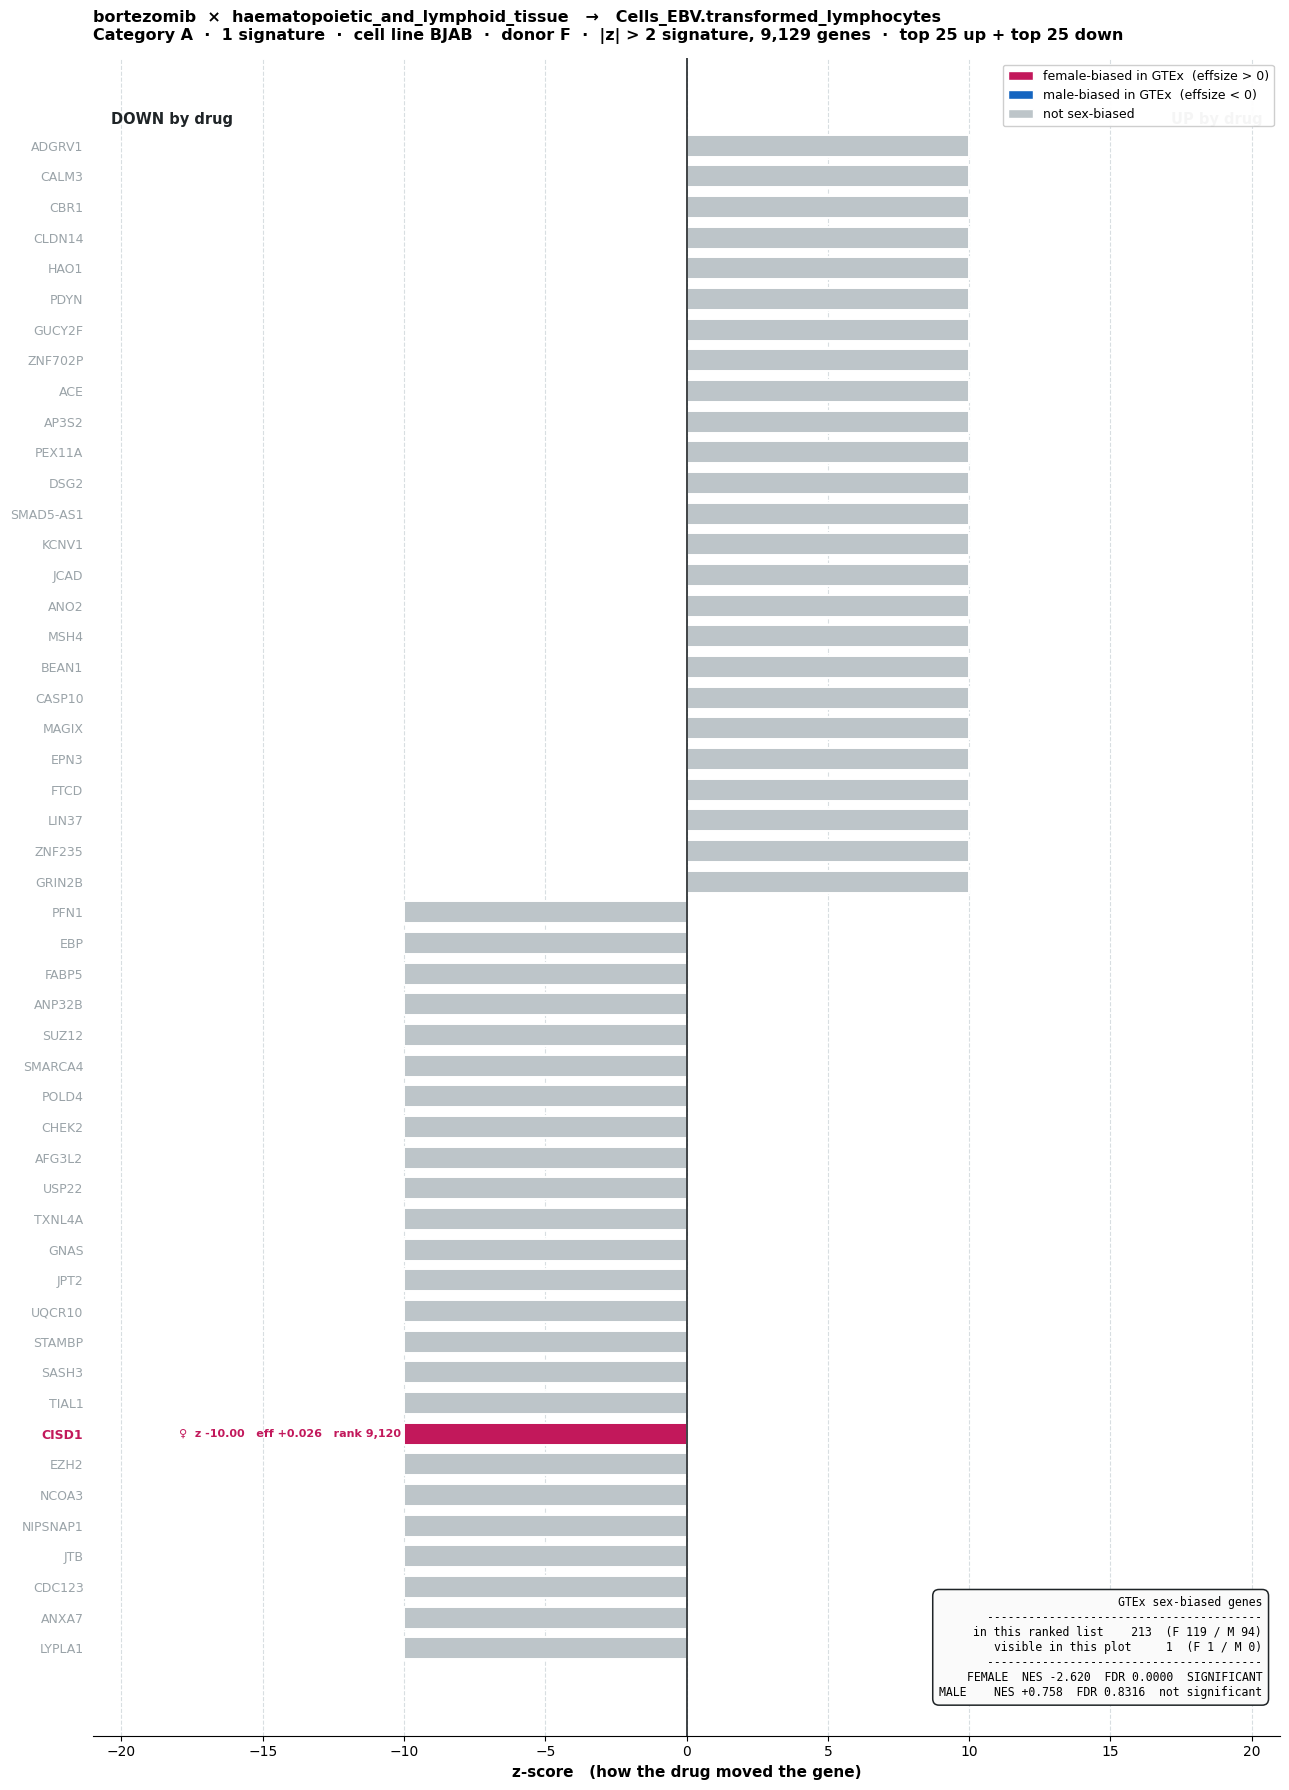


1 signature  ·  cell line BJAB  ·  donor F   [filtered]
sex-biased in ranked list : 213 (F 119 / M 94)
visible in top 25+25    : 1 (F 1 / M 0)


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 07:55:05,014 [WARNING] Duplicated values found in preranked stats: 2.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


   |z| > 2 filter : 12,328 -> 9,171 genes
saved: /content/drive/MyDrive/Project59/figures/grouped_bortezomib_haematopoiet_Cells_EBV.transf_AICHI002_BJAB_24H:I09_filtered.png


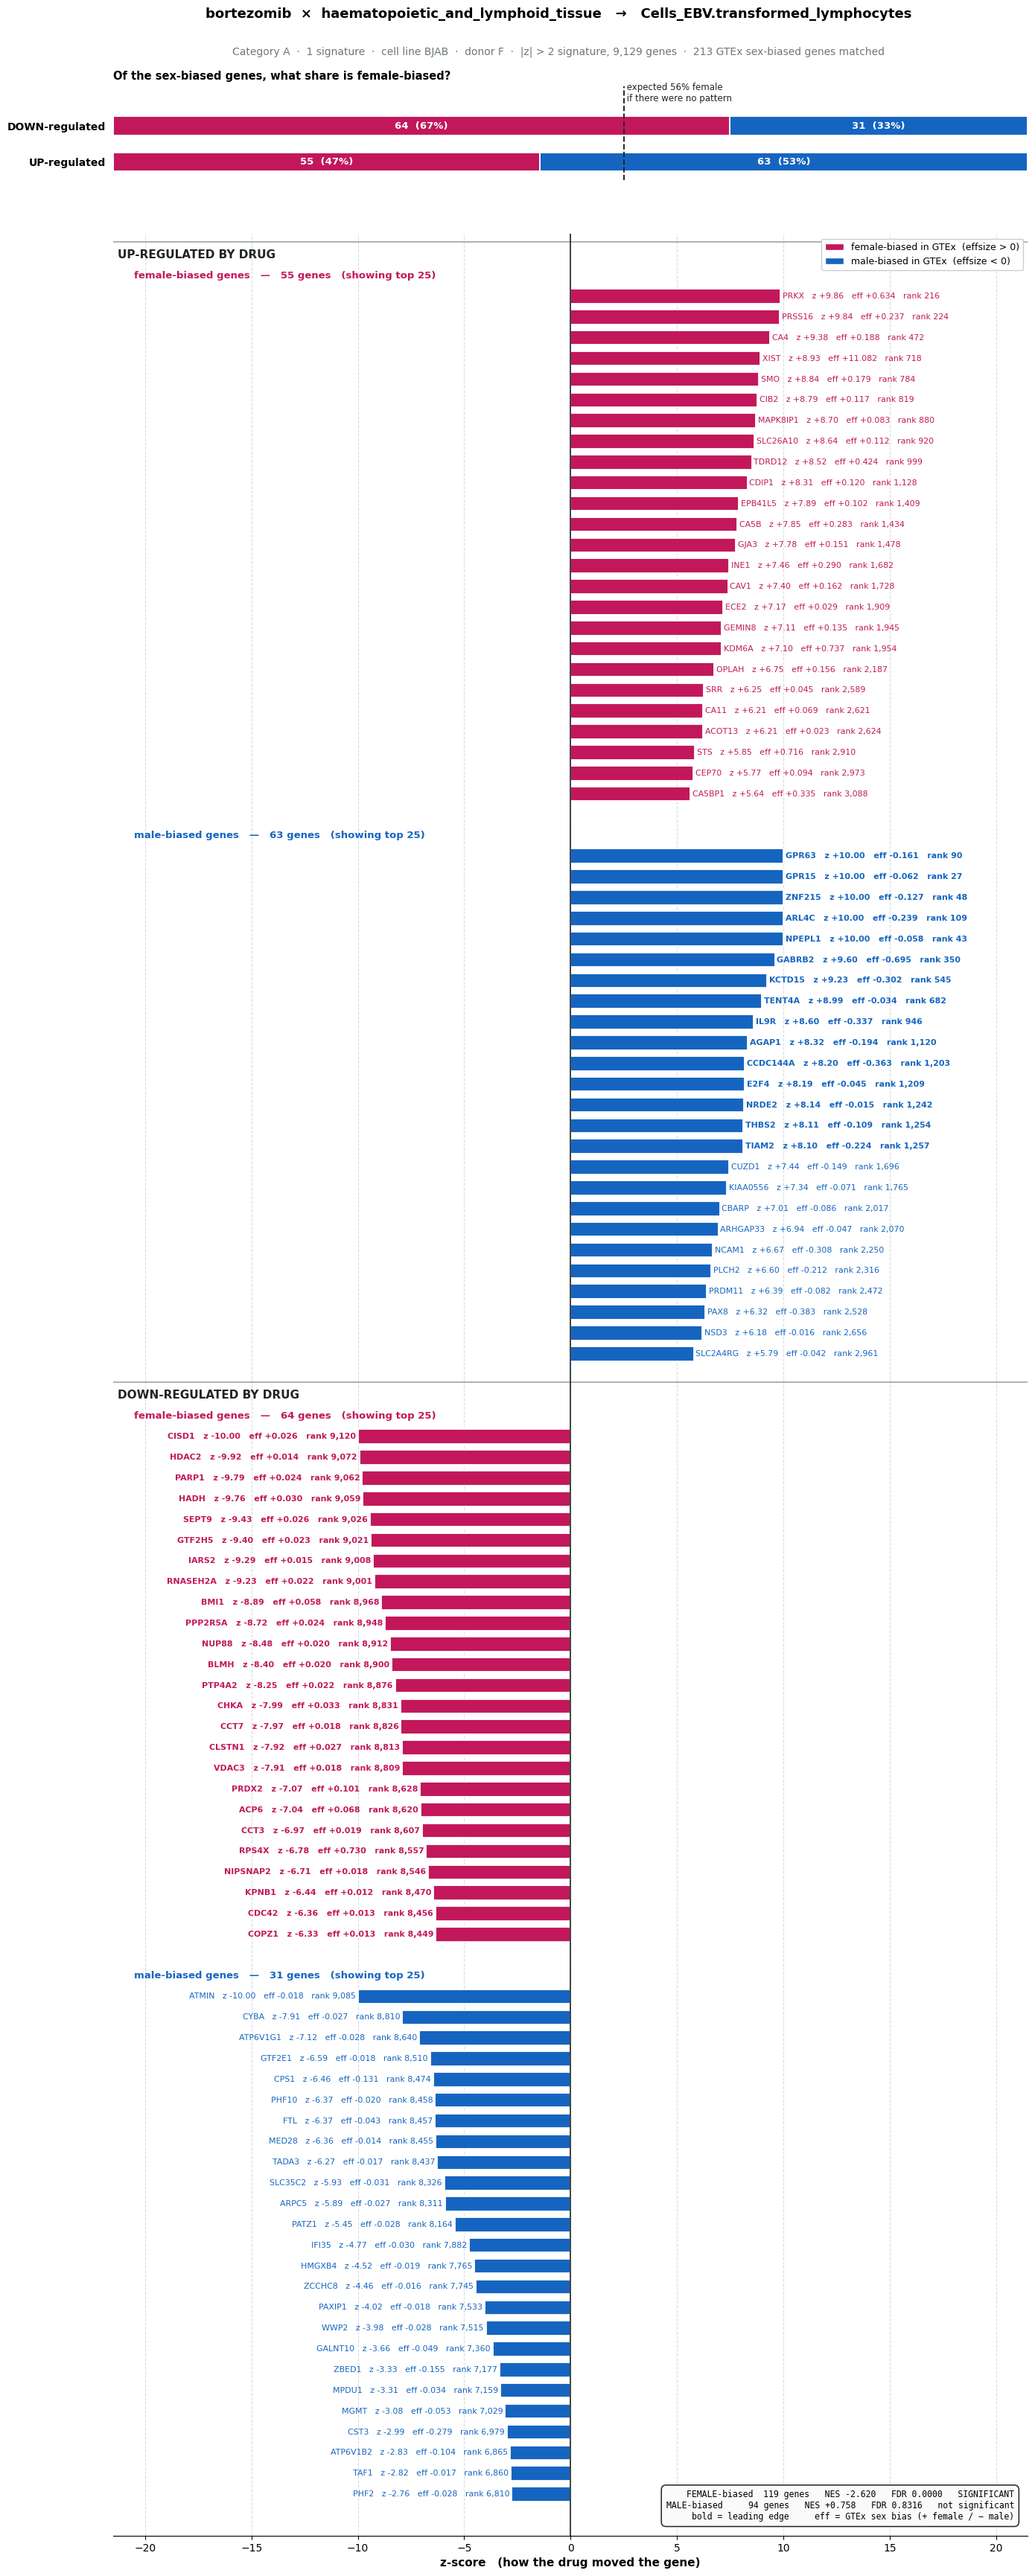


1 signature  ·  cell line BJAB  ·  donor F   [filtered]
                        UP    DOWN   total
------------------------------------------
female-biased           55      64     119
male-biased             63      31      94


,gene,sex,z,eff,rank,LE
0,PNPLA4,F,4.988423,0.890362,3651,False
1,PRSS21,F,-4.519339,0.383448,7767,False
2,PSMB1,F,-4.654238,0.017508,7833,False
3,NCDN,F,4.570761,0.027864,4002,False
4,NLRP2,F,2.224435,0.864181,6147,False
...,...,...,...,...,...,...
208,ZBED1,M,-3.329468,-0.154756,7177,False
209,NPEPL1,M,10.000000,-0.058401,43,True
210,ZNF688,M,3.530340,-0.028116,4932,False
211,RBM15B,M,2.845304,-0.018607,5568,False


In [48]:
SIG1 = good[0]['sig_id'] if good else cands.iloc[0]['sig_id']
print("using:", SIG1)

# bar chart — sex genes highlighted, |z| > 2
sex_bar_highlight(DRUG, LIN, T_ISSUE, sig_id=SIG1, mode='filtered', top_n=25)

# aur sirf sex genes wala grouped version
sex_bar_grouped(DRUG, LIN, T_ISSUE, sig_id=SIG1, mode='filtered', max_per_block=25)

signature : AICHI002_BJAB_24H:I09
mode      : filtered



/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 07:57:52,969 [WARNING] Duplicated values found in preranked stats: 2.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


   |z| > 2 filter : 12,328 -> 9,171 genes
saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_haematopoiet_Cells_EBV.transf_AICHI002_BJAB_24H:I09_filtered.png


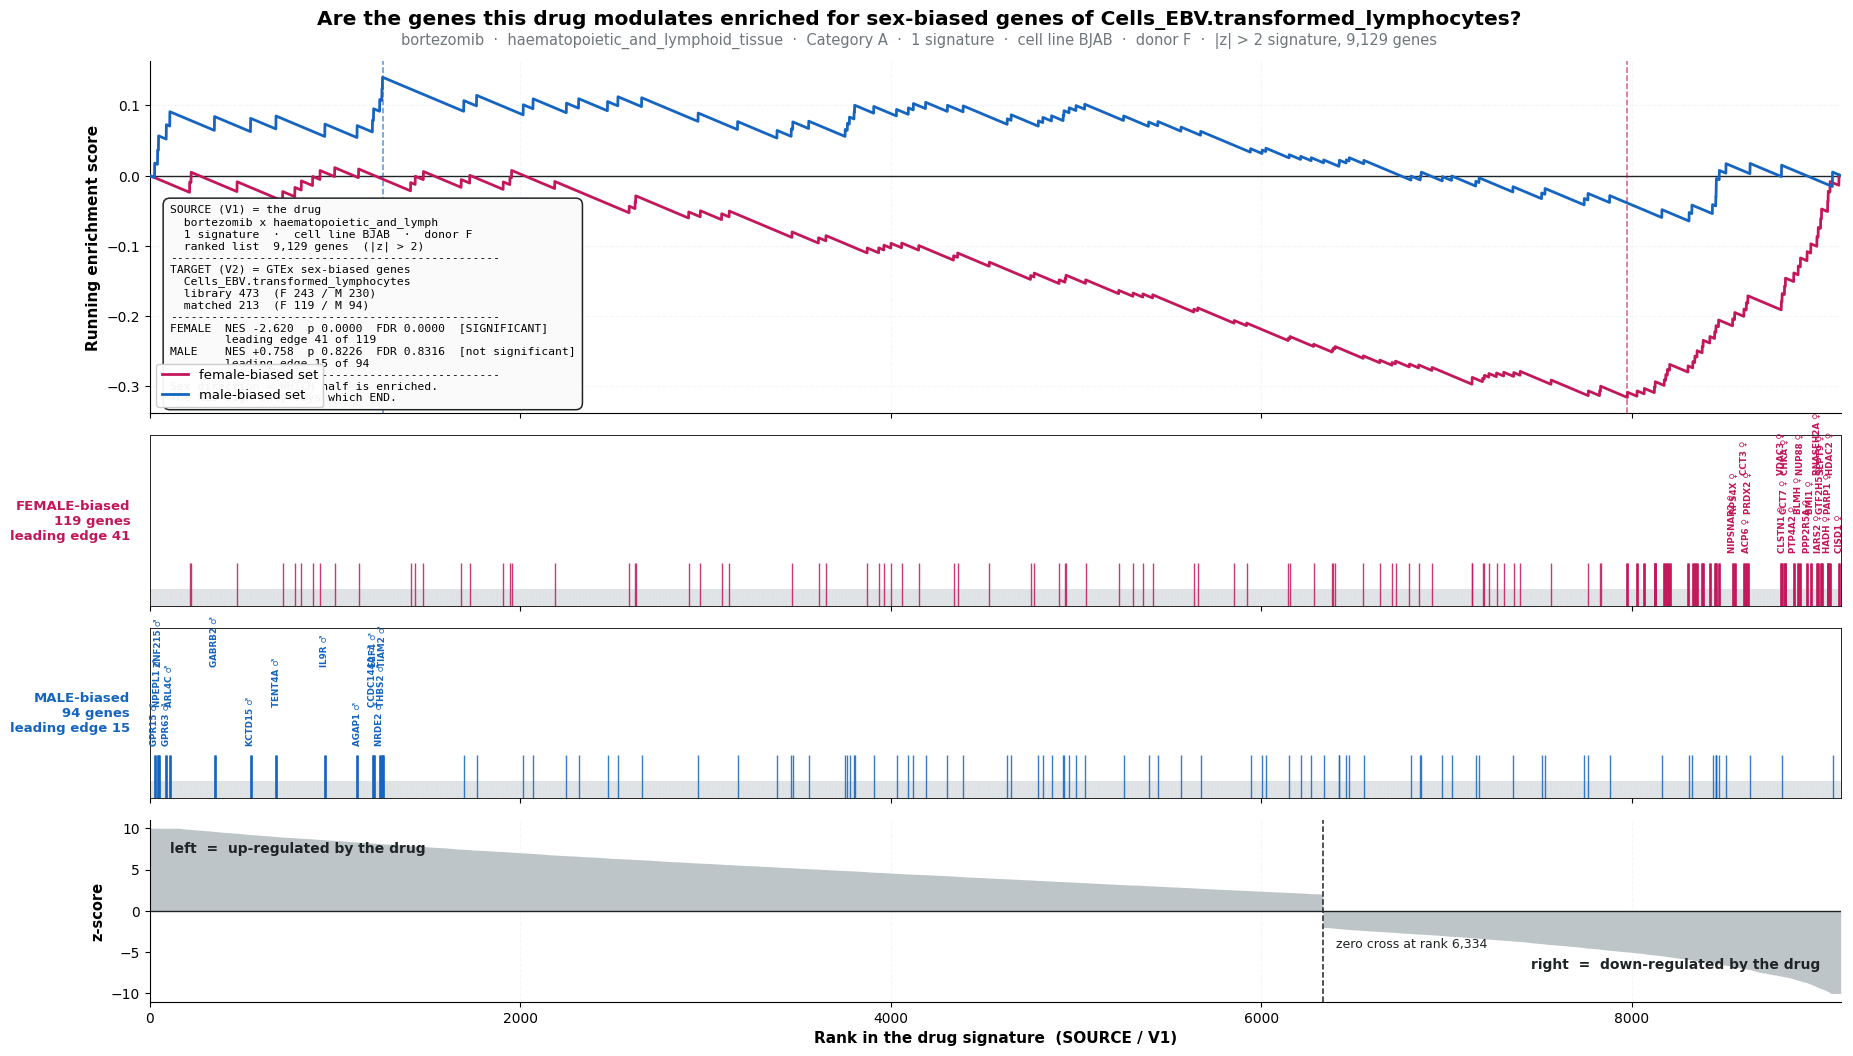


1 signature  ·  cell line BJAB  ·  donor F   [filtered]
FEMALE  NES -2.620  FDR 0.0000
MALE    NES +0.758  FDR 0.8316


In [49]:
# enrichment plot — ek signature, sex genes barcode pe
SIG1 = good[0]['sig_id'] if good else cands.iloc[0]['sig_id']
MODE = 'filtered' if good else 'full'

print(f"signature : {SIG1}")
print(f"mode      : {MODE}"
      f"{'   (filter se kaam nahi chala, full pe ja rahe hain)' if not good else ''}\n")

stat1 = sex_enrichment(DRUG, LIN, T_ISSUE, sig_id=SIG1,
                       mode=MODE, max_labels=22)

#   sig_id                                        cell     sex  dose     time  
----------------------------------------------------------------------------------
1   AICHI002_BJAB_24H:I09                         BJAB     F    0.66 uM  24 h    <- sig 1
2   EMU001_NALM6_24H:C05                          NALM6    M    0.04 uM  24 h  
3   EMU001_TMD8_24H:C05                           TMD8     M    0.04 uM  24 h  
4   AICHI002_BJAB_24H:I10                         BJAB     F    0.125 uM 24 h  
5   EMU001_TMD8_24H:C06                           TMD8     M    0.01 uM  24 h  
6   AICHI002_OCILY3_24H:I12                       OCILY3   M    0.01 uM  24 h  
7   AICHI002_NALM6_24H:I10                        NALM6    M    0.125 uM 24 h  
8   EMU001_BJAB_24H:C05                           BJAB     F    0.04 uM  24 h  
9   EMU001_NALM6_24H:C04                          NALM6    M    0.125 uM 24 h  
10  AICHI002_NALM6_24H:I08                        NALM6    M    2.5 uM   24 h  
11  EMU001_NALM6_24H:C06   

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 08:03:35,080 [WARNING] Duplicated values found in preranked stats: 0.34% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


   |z| > 2 filter : 12,328 -> 7,626 genes
saved: /content/drive/MyDrive/Project59/figures/highlight_bortezomib_haematopoiet_Cells_EBV.transf_EMU001_NALM6_24H:C05_filtered.png


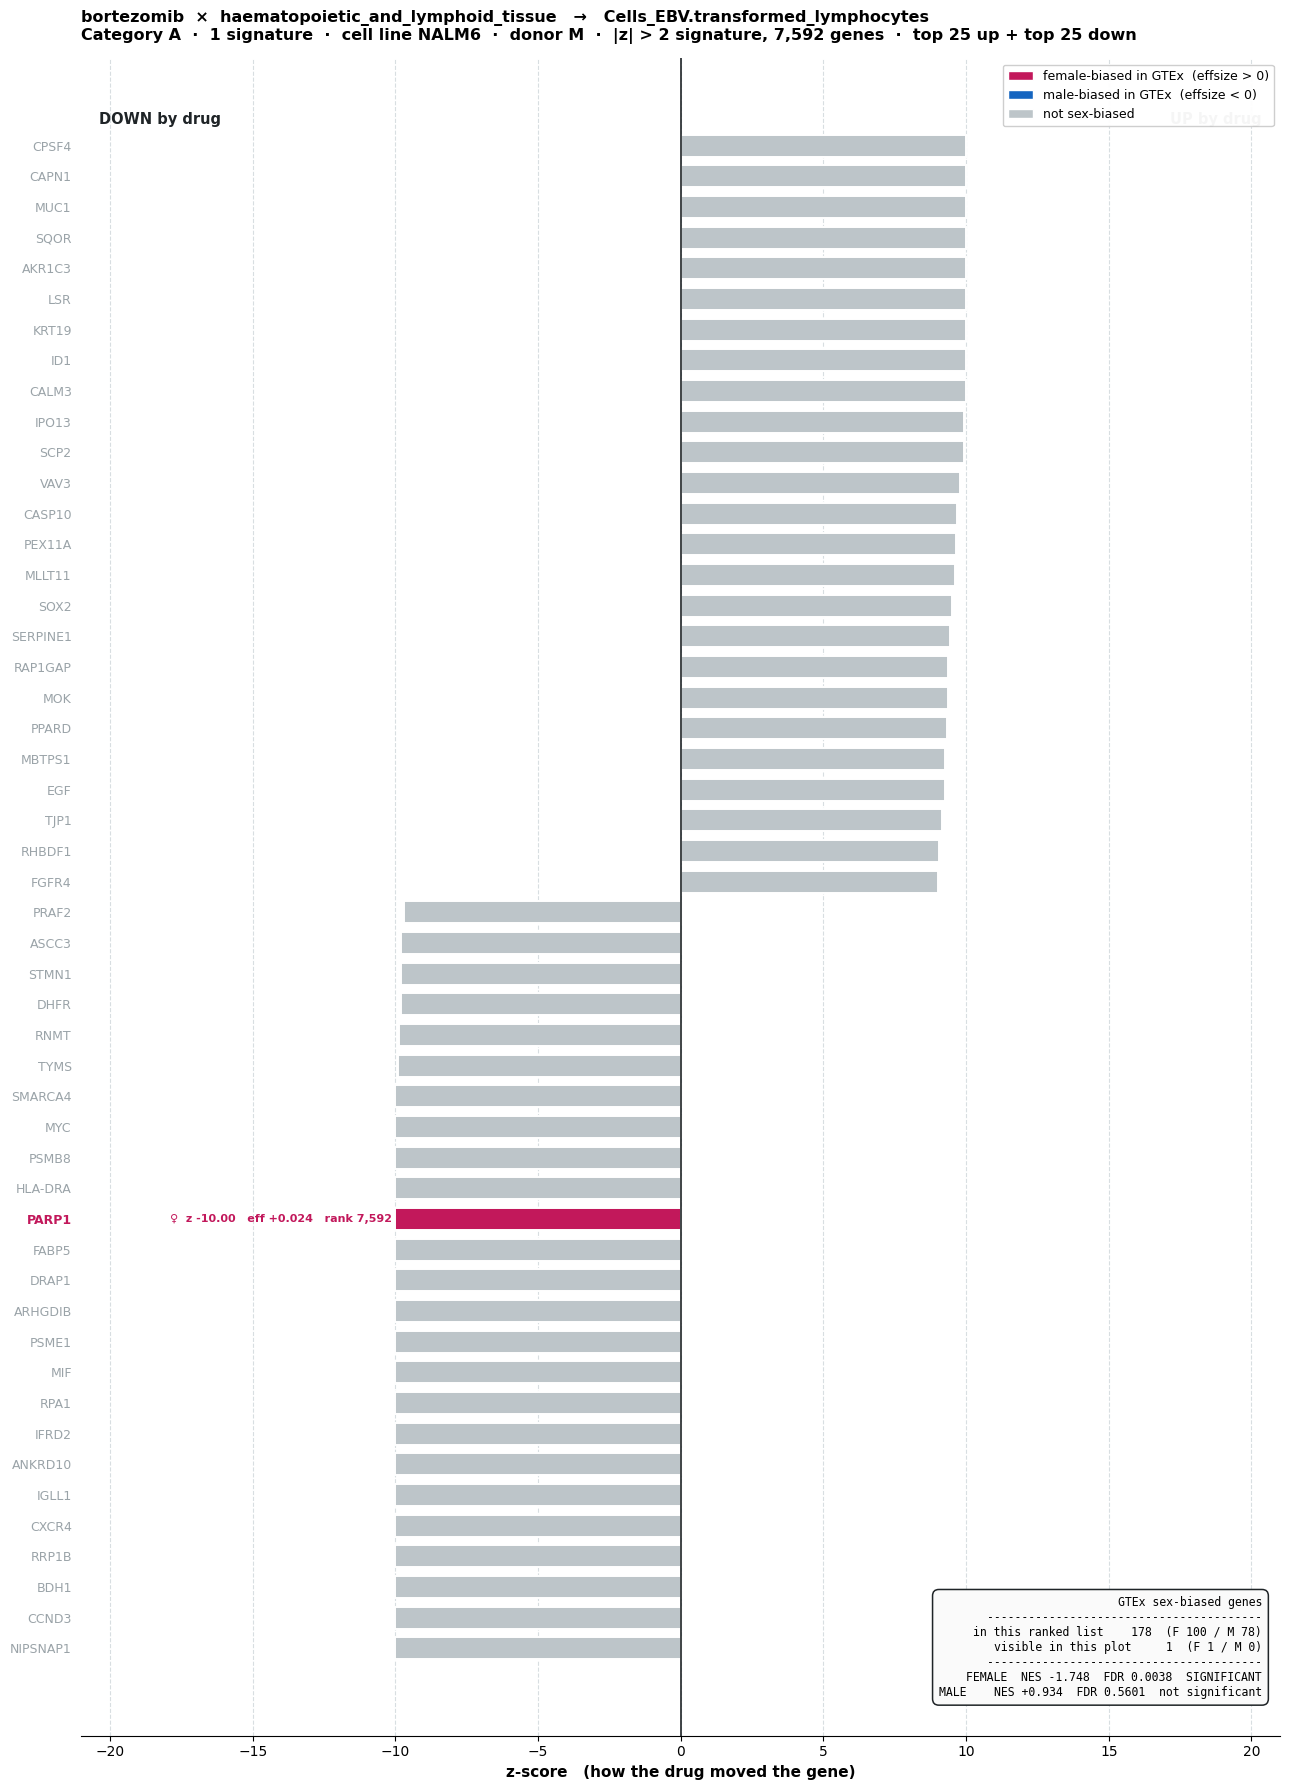


1 signature  ·  cell line NALM6  ·  donor M   [filtered]
sex-biased in ranked list : 178 (F 100 / M 78)
visible in top 25+25    : 1 (F 1 / M 0)


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 08:03:38,829 [WARNING] Duplicated values found in preranked stats: 0.34% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


   |z| > 2 filter : 12,328 -> 7,626 genes
saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_haematopoiet_Cells_EBV.transf_EMU001_NALM6_24H:C05_filtered.png


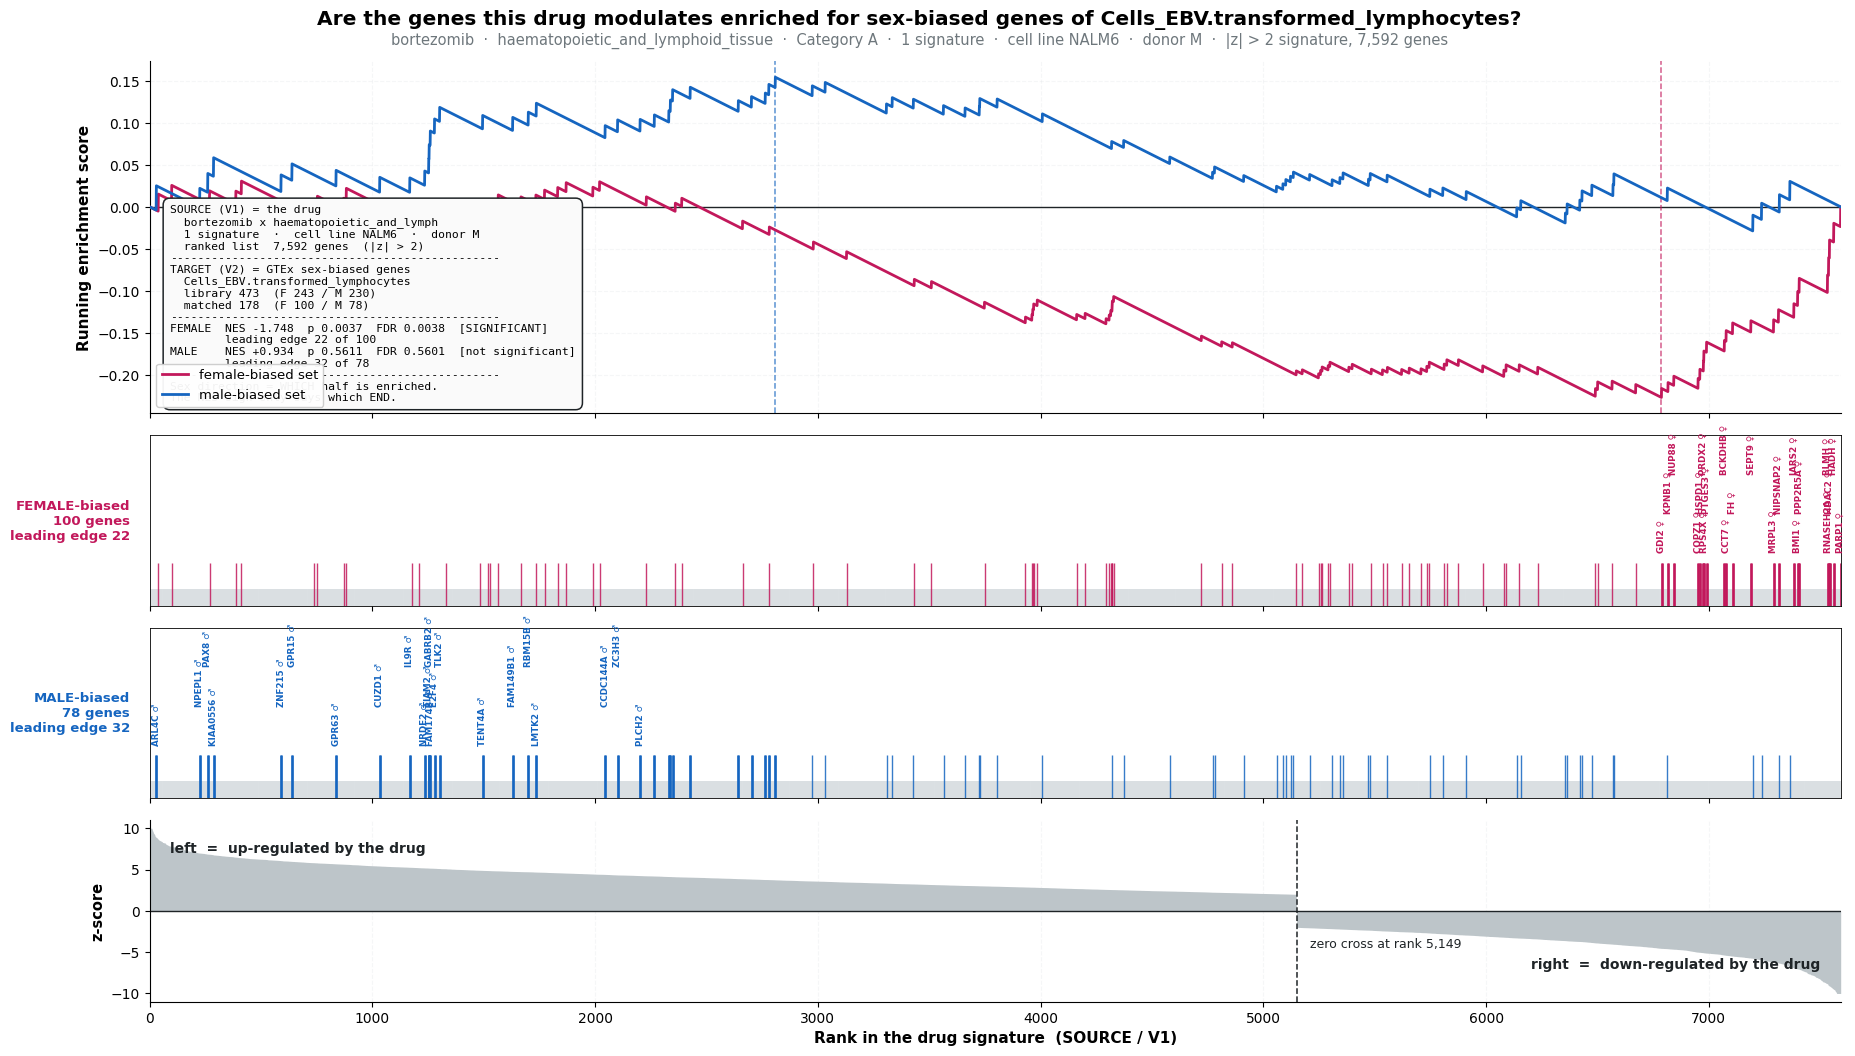


1 signature  ·  cell line NALM6  ·  donor M   [filtered]
FEMALE  NES -1.748  FDR 0.0038
MALE    NES +0.934  FDR 0.5601


In [52]:
# jo scan mein BOTH nikle the
ok_ids = [r['sig_id'] for r in rows if r['ok'] == 'BOTH']
info   = cands.set_index('sig_id')

print(f"{'#':<4}{'sig_id':<46}{'cell':<9}{'sex':<5}{'dose':<9}{'time':<6}")
print("-" * 82)
for i, sid in enumerate(ok_ids, 1):
    r = info.loc[sid]
    mark = '  <- sig 1' if sid == SIG1 else ''
    print(f"{i:<4}{sid:<46}{str(r['cell_iname']):<9}{str(r['donor_sex']):<5}"
          f"{str(r['pert_idose']):<9}{str(r['pert_itime']):<6}{mark}")

# signature 2 = agli wali, alag cell line se (male ho toh behtar)
used_cell = info.loc[SIG1, 'cell_iname']
pool = [x for x in ok_ids
        if x != SIG1 and info.loc[x, 'cell_iname'] != used_cell]
male = [x for x in pool if info.loc[x, 'donor_sex'] == 'M']
SIG2 = (male[0] if male else (pool[0] if pool else
        [x for x in ok_ids if x != SIG1][0]))

r2 = info.loc[SIG2]
print(f"\nSIGNATURE 2")
print(f"  sig_id    : {SIG2}")
print(f"  cell line : {r2['cell_iname']}   donor {r2['donor_sex']}")
print(f"  dose/time : {r2['pert_idose']}  ·  {r2['pert_itime']}")
print(f"  (sig 1 was {info.loc[SIG1,'cell_iname']}, donor "
      f"{info.loc[SIG1,'donor_sex']})\n")

# ---- dono plots ----
sex_bar_highlight(DRUG, LIN, T_ISSUE, sig_id=SIG2, mode='filtered', top_n=25)
stat2 = sex_enrichment(DRUG, LIN, T_ISSUE, sig_id=SIG2, mode='filtered')

DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_A  = 'Cells_EBV.transformed_lymphocytes'

# blood lineage ki cell lines, donor sex ke saath
b = sig_known[(sig_known['cmap_name'] == DRUG) &
              (sig_known['cell_lineage'] == LIN)]
b = b[b['sig_id'].isin(gctx_sigs)]
print(b.groupby(['cell_iname', 'donor_sex']).size()
       .reset_index(name='n_signatures')
       .sort_values('n_signatures', ascending=False)
       .to_string(index=False))

In [67]:
# ============================================================
#  DIRECTION VERIFICATION  —  Marouen's question
#  "check that the library you're enriching against is
#   Cells_EBV, and not the other way around"
# ============================================================
import gseapy, numpy as np, pandas as pd

DRUG   = 'bortezomib'
LIN    = 'haematopoietic_and_lymphoid_tissue'
TISSUE = 'Cells_EBV.transformed_lymphocytes'

# ---- V1 = SOURCE = the drug's ranked list -------------------
V1, src = build_V1(DRUG, LIN, mode='full', quiet=True)

# ---- V2 = TARGET = the GTEx sex-biased halves ---------------
halves = split_sets(TISSUE)
Fkey, Mkey = f'{TISSUE}__FEMALE', f'{TISSUE}__MALE'

print("="*78)
print("DIRECTION VERIFICATION")
print("="*78)

print("\nV1   SOURCE   (goes into  rnk=)")
print(f"   what it is   : {DRUG}  x  {LIN}")
print(f"                  drug-induced z-scores from CMap Level 5")
print(f"   built from   : {src}")
print(f"   length       : {len(V1):,} genes, ranked high -> low")
print(f"   type         : ordered ranked list (pandas Series)")
print(f"   top 3        : {list(V1.index[:3])}")

print("\nV2   TARGET   (goes into  gene_sets=)")
print(f"   what it is   : GTEx v8 sex-biased genes in {TISSUE}")
print(f"   FEMALE half  : {len(halves[Fkey]):,} genes   (effsize > 0)")
print(f"   MALE   half  : {len(halves[Mkey]):,} genes   (effsize < 0)")
print(f"   total        : {len(halves[Fkey])+len(halves[Mkey]):,} genes")
print(f"   type         : unordered gene sets (dict of sets)")

# ---- the actual call ----------------------------------------
res = gseapy.prerank(rnk             = V1,        # SOURCE
                     gene_sets       = halves,    # TARGET
                     permutation_num = 1000,
                     min_size        = 15,
                     max_size        = 5000,
                     seed            = 42,
                     no_plot         = True,
                     verbose         = False)

print("\n" + "-"*78)
print("THE CALL")
print("-"*78)
print("gseapy.prerank(rnk       = V1,        <- SOURCE : the drug's ranked list")
print("               gene_sets = halves)    <- TARGET : the GTEx library")

# ---- the proof ----------------------------------------------
ovF = len(set(V1.index) & halves[Fkey])
ovM = len(set(V1.index) & halves[Mkey])
lib = len(halves[Fkey]) + len(halves[Mkey])

print("\n" + "-"*78)
print("PROOF IT IS NOT INVERTED")
print("-"*78)
print(f"ranked list length   : {len(V1):,}")
print(f"GTEx library size    : {lib:,}")
print(f"overlap              : {ovF+ovM}   (F {ovF} / M {ovM})")
print()
print(f"If the GTEx library had been passed as rnk=, the ranked list")
print(f"would be {lib:,} long. It is {len(V1):,}.")
print(f"The drug is the source. Direction is correct.")

print("\n" + "-"*78)
print("RESULT")
print("-"*78)
cols = [c for c in ['Term','ES','NES','NOM p-val','FDR q-val','Tag %']
        if c in res.res2d.columns]
print(res.res2d[cols].to_string(index=False))

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
2026-09-28 10:31:22,219 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


DIRECTION VERIFICATION

V1   SOURCE   (goes into  rnk=)
   what it is   : bortezomib  x  haematopoietic_and_lymphoid_tissue
                  drug-induced z-scores from CMap Level 5
   built from   : 255 signatures  ·  cell line 15 lines  ·  donor F/M
   length       : 12,276 genes, ranked high -> low
   type         : ordered ranked list (pandas Series)
   top 3        : ['ENSG00000204389', 'ENSG00000132002', 'ENSG00000177606']

V2   TARGET   (goes into  gene_sets=)
   what it is   : GTEx v8 sex-biased genes in Cells_EBV.transformed_lymphocytes
   FEMALE half  : 243 genes   (effsize > 0)
   MALE   half  : 230 genes   (effsize < 0)
   total        : 473 genes
   type         : unordered gene sets (dict of sets)

------------------------------------------------------------------------------
THE CALL
------------------------------------------------------------------------------
gseapy.prerank(rnk       = V1,        <- SOURCE : the drug's ranked list
               gene_sets = halves)    

In [70]:
DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_B  = 'Brain_Hypothalamus'          # CROSS -> Category B

# ---- signatures: drug x lineage ONLY. tissue ka koi role nahi ----
s = sig_known[(sig_known['cmap_name']    == DRUG) &
              (sig_known['cell_lineage'] == LIN)]
s = s[s['sig_id'].isin(gctx_sigs)]

print("="*72)
print(f"{DRUG}  ×  {LIN}")
print("="*72)
print(f"   signatures    : {len(s)}")
print(f"   cell lines    : {s['cell_iname'].nunique()}")
print(f"   donor sex     : {dict(s['donor_sex'].value_counts())}")
print(f"   ^ ye number tissue badalne se NAHI badalta\n")

# ---- GTEx library for this tissue ----
h = split_sets(T_B)
F, M = h[f'{T_B}__FEMALE'], h[f'{T_B}__MALE']
home = set(cmap_to_gtex.get(LIN, []))

print(f"{T_B}  library")
print(f"   total         : {len(F)+len(M):,}   (F {len(F):,} / M {len(M):,})")
print(f"   category      : {'A  HOME' if T_B in home else 'B  CROSS'}")


# ---- kitne genes match honge, dono mode me ----
check_sizes(DRUG, LIN, T_B)

bortezomib  ×  haematopoietic_and_lymphoid_tissue
   signatures    : 255
   cell lines    : 15
   donor sex     : {'M': np.int64(190), 'F': np.int64(65)}
   ^ ye number tissue badalne se NAHI badalta

Brain_Hypothalamus  library
   total         : 2,739   (F 1,397 / M 1,342)
   category      : B  CROSS
bortezomib × haematopoietic_and_lymphoid_tissue → Brain_Hypothalamus
selection: whole lineage

mode                ranked list   F match   M match     verdict
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


full                     12,276       900       705 both halves


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


filtered                  2,047       141        82 both halves

(a half needs at least 15 matched genes — the GSEA default)


sex_panel ready


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/tmp/ipykernel_1808/454327554.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .965])


saved: /content/drive/MyDrive/Project59/figures/panel_bortezomib_Brain_Hypothalam_lineage_filtered.png


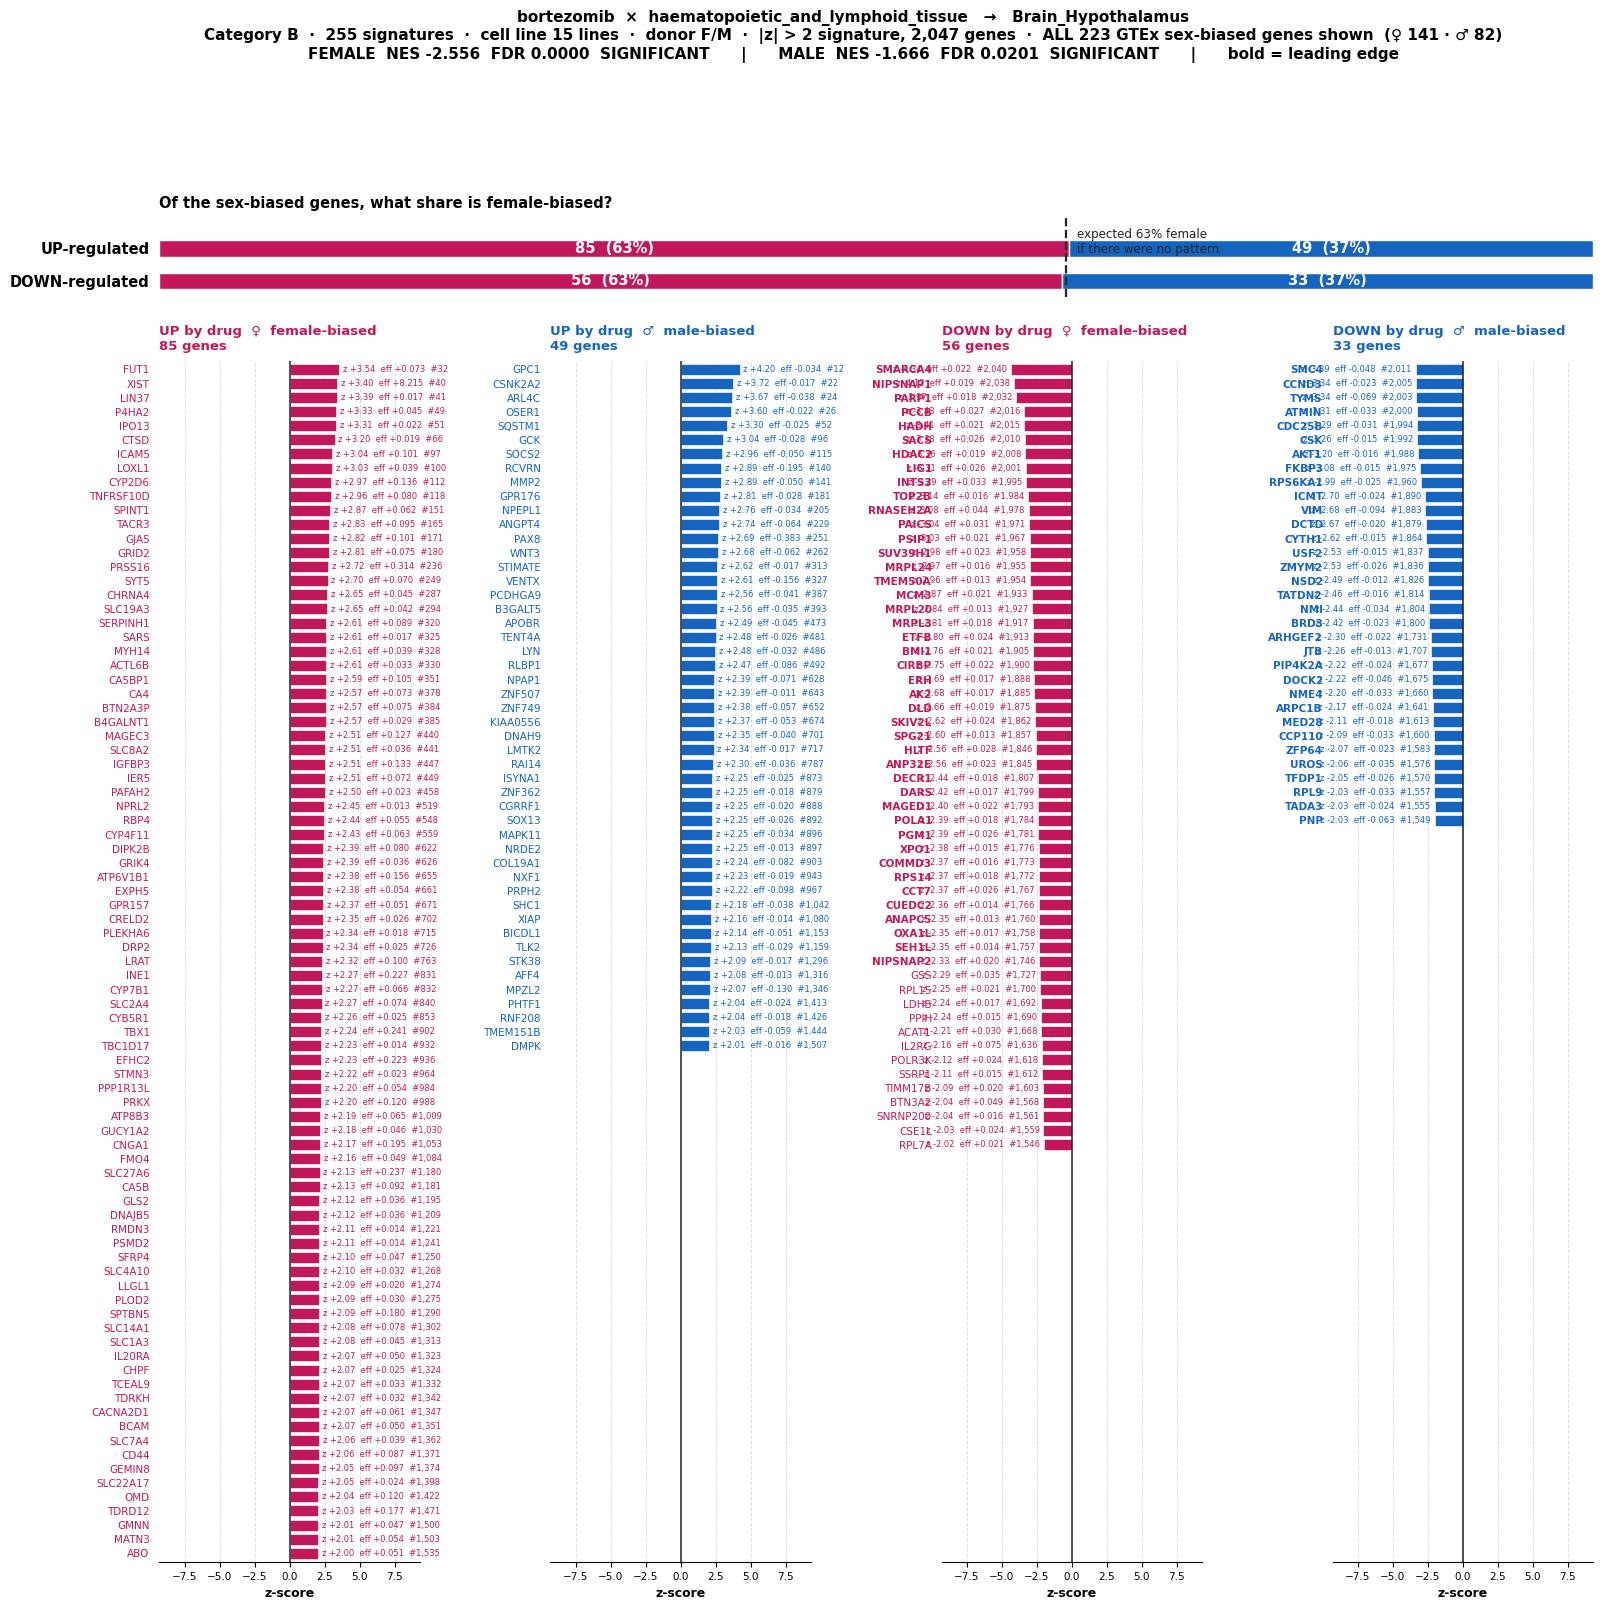


255 signatures  ·  cell line 15 lines  ·  donor F/M   [filtered]   ranked list 2,047 genes
sex-biased matched : 223   (♀ 141 / ♂ 82)
   UP   ♀   85   ♂   49
   DOWN ♀   56   ♂   33    -> DOWN is 63% female vs 63% expected
gene table saved : /content/drive/MyDrive/Project59/results/sexgenes_bortezomib_Brain_Hypothalam_lineage_filtered.csv


In [72]:
# ============================================================
#  sex_panel  —  saare sex-biased genes, 4 blocks me
#  UP ♀ | UP ♂ | DOWN ♀ | DOWN ♂
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

# palette (agar pehle se hai to wahi use hoga)
F_COL = globals().get('F_COL', '#C2185B')
M_COL = globals().get('M_COL', '#1565C0')
INK   = globals().get('INK',   '#1F2427')
GRID  = globals().get('GRID',  '#D8DEE1')


def sex_panel(drug, lineage, tissue, mode='filtered', sig_id=None,
              cell_line=None, n_perm=1000, save=True):
    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line, quiet=True)
    if V1 is None: return None
    G = _gsea(V1, tissue, n_perm, quiet=True)
    if G is None: return None

    gs, stat = G['gs'], G['stat']
    Fset, Mset = set(gs[G['kF']]), set(gs[G['kM']])
    le = ({V1.index[i] for i in G['leF']} | {V1.index[i] for i in G['leM']})

    t = sbg[sbg['tissue'] == tissue].copy()
    t['ens'] = t['gene'].astype(str).str.split('.').str[0]
    eff = t.groupby('ens')['effsize'].mean()

    D = pd.DataFrame({'ens': V1.index, 'z': V1.values})
    D['rank'] = np.arange(1, len(D) + 1)
    D['gene'] = D['ens'].map(lambda g: ENS2SYM.get(g, g))
    D['sex']  = np.where(D['ens'].isin(Fset), 'F',
                np.where(D['ens'].isin(Mset), 'M', ''))
    D['eff']  = D['ens'].map(eff)
    D['LE']   = D['ens'].isin(le)

    S = D[D['sex'] != ''].copy()
    if len(S) == 0:
        print("koi sex-biased gene match nahi hua"); return None
    if len(S) > 400:
        print(f"WARNING: {len(S)} genes — figure bahut lamba hoga. "
              f"mode='filtered' use karo, ya sex_counts() chalao.")

    blocks = [
        ('UP by drug  \u2640  female-biased',
         S[(S.sex=='F') & (S.z>0)].sort_values('z', ascending=False), F_COL),
        ('UP by drug  \u2642  male-biased',
         S[(S.sex=='M') & (S.z>0)].sort_values('z', ascending=False), M_COL),
        ('DOWN by drug  \u2640  female-biased',
         S[(S.sex=='F') & (S.z<0)].sort_values('z'), F_COL),
        ('DOWN by drug  \u2642  male-biased',
         S[(S.sex=='M') & (S.z<0)].sort_values('z'), M_COL)]

    upF, upM, dnF, dnM = [len(b[1]) for b in blocks]
    nF, nM = int((S.sex=='F').sum()), int((S.sex=='M').sum())
    base   = 100 * nF / len(S)
    rows   = max(1, max(len(b[1]) for b in blocks))

    fig = plt.figure(figsize=(18.5, max(8.5, .175*rows + 2.6)))
    gsp = fig.add_gridspec(2, 4, height_ratios=[1, max(6, .175*rows)],
                           hspace=.10, wspace=.50)

    # ---------- summary stacked bar ----------
    axS = fig.add_subplot(gsp[0, :])
    for i, (lab, f, m) in enumerate([('DOWN-regulated', dnF, dnM),
                                     ('UP-regulated',   upF, upM)]):
        tot = f + m
        pf  = 100*f/tot if tot else 0
        axS.barh(i, pf,     .5, color=F_COL, edgecolor='white')
        axS.barh(i, 100-pf, .5, left=pf, color=M_COL, edgecolor='white')
        if f: axS.text(pf/2, i, f'{f}  ({pf:.0f}%)', ha='center', va='center',
                       color='white', fontsize=10.5, fontweight='bold')
        if m: axS.text(pf+(100-pf)/2, i, f'{m}  ({100-pf:.0f}%)', ha='center',
                       va='center', color='white', fontsize=10.5, fontweight='bold')
    axS.axvline(base, ls='--', lw=1.6, color=INK)
    axS.text(base+.8, 1.62, f'expected {base:.0f}% female\nif there were no pattern',
             fontsize=8.6, color=INK, va='top')
    axS.set_yticks([0, 1])
    axS.set_yticklabels(['DOWN-regulated', 'UP-regulated'],
                        fontsize=10.5, fontweight='bold')
    axS.set_xlim(0, 100); axS.set_ylim(-.5, 2.0)
    axS.set_xticks([]); axS.tick_params(left=False)
    axS.spines[['top','right','left','bottom']].set_visible(False)
    axS.set_title('Of the sex-biased genes, what share is female-biased?',
                  fontsize=10.5, fontweight='bold', loc='left', pad=6)

    # ---------- four gene blocks ----------
    pad = S['z'].abs().max() * 2.15
    for j, (lab, B, col) in enumerate(blocks):
        ax = fig.add_subplot(gsp[1, j])
        B  = B.reset_index(drop=True)
        if len(B):
            y = np.arange(len(B))
            ax.barh(y, B['z'], .78, color=col, edgecolor='white', linewidth=.45)
            for i, r in enumerate(B.itertuples()):
                ax.text(r.z + (pad*.03 if r.z > 0 else -pad*.03), i,
                        f"z {r.z:+.2f}  eff {r.eff:+.3f}  #{r.rank:,}",
                        va='center', ha='left' if r.z > 0 else 'right',
                        fontsize=6.0, color=col)
            ax.set_yticks(y); ax.set_yticklabels(B['gene'], fontsize=6.6)
            for tl, le_ in zip(ax.get_yticklabels(), B['LE']):
                tl.set_color(col)
                if le_: tl.set_fontweight('bold')
        ax.axvline(0, color=INK, lw=1.1)
        ax.set_xlim(-pad, pad); ax.set_ylim(rows-.4, -.6)
        ax.set_title(f'{lab}\n{len(B)} genes', fontsize=9.5,
                     fontweight='bold', color=col, loc='left', pad=8)
        ax.set_xlabel('z-score', fontsize=9, fontweight='bold')
        ax.grid(axis='x', color=GRID, lw=.7, ls='--'); ax.set_axisbelow(True)
        ax.spines[['top','right','left']].set_visible(False)
        ax.tick_params(left=False, labelsize=7.5)

    g   = lambda k, i: stat[k][i] if k in stat else float('nan')
    sg  = lambda q: 'SIGNIFICANT' if (q == q and q < 0.05) else 'not significant'
    home = set(cmap_to_gtex.get(lineage, []))
    fig.suptitle(
        f'{drug}  ×  {lineage}   →   {tissue}\n'
        f'Category {"A" if tissue in home else "B"}  ·  {src}  ·  '
        f'{"full" if mode=="full" else "|z| > 2"} signature, {len(V1):,} genes  ·  '
        f'ALL {len(S)} GTEx sex-biased genes shown  (\u2640 {nF} · \u2642 {nM})\n'
        f'FEMALE  NES {g("F",0):+.3f}  FDR {g("F",2):.4f}  {sg(g("F",2))}      |      '
        f'MALE  NES {g("M",0):+.3f}  FDR {g("M",2):.4f}  {sg(g("M",2))}      |      '
        f'bold = leading edge',
        fontsize=11, fontweight='bold', y=.998)

    plt.tight_layout(rect=[0, 0, 1, .965])
    tag = (sig_id or cell_line or 'lineage').replace(':', '_')
    if save:
        fn = f'{BASE}/figures/panel_{drug}_{tissue[:16]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=165, bbox_inches='tight'); print("saved:", fn)
    plt.show()

    print(f"\n{src}   [{mode}]   ranked list {len(V1):,} genes")
    print(f"sex-biased matched : {len(S)}   (\u2640 {nF} / \u2642 {nM})")
    print(f"   UP   \u2640 {upF:>4}   \u2642 {upM:>4}")
    print(f"   DOWN \u2640 {dnF:>4}   \u2642 {dnM:>4}"
          f"    -> DOWN is {100*dnF/max(1,dnF+dnM):.0f}% female "
          f"vs {base:.0f}% expected")
    out = f'{BASE}/results/sexgenes_{drug}_{tissue[:16]}_{tag}_{mode}.csv'
    S[['gene','ens','sex','z','rank','eff','LE']]\
        .sort_values('z', ascending=False).to_csv(out, index=False)
    print("gene table saved :", out)
    return S


print("sex_panel ready")

# ============================================================
#  RUN  —  bortezomib × blood → Brain_Hypothalamus  (Category B)
# ============================================================
DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_B  = 'Brain_Hypothalamus'

S = sex_panel(DRUG, LIN, T_B, mode='filtered')      # 223 genes

sex_enrichment ready


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


library 2,739  (F 1,397 / M 1,342)
matched 223  (F 141 / M 82)


/tmp/ipykernel_1808/1037610357.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_Brain_Hypothalamus_lineage_filtered.png


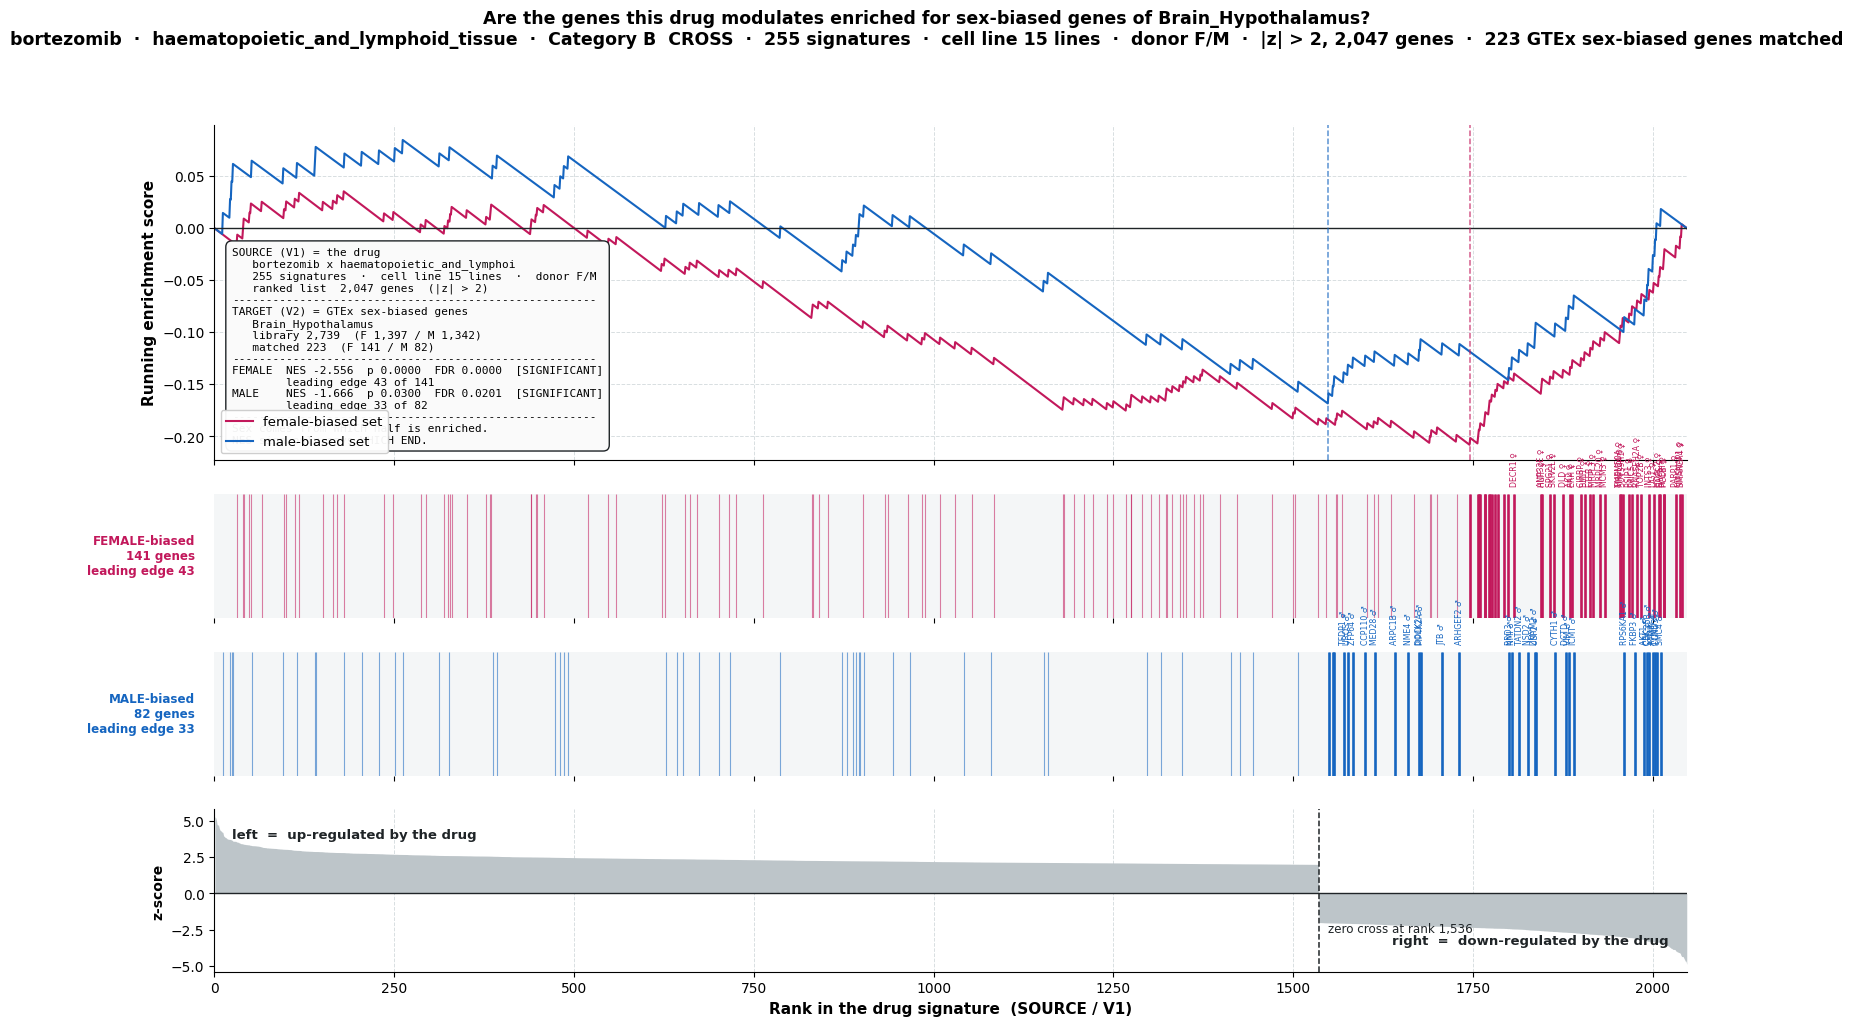


255 signatures  ·  cell line 15 lines  ·  donor F/M   [filtered]
FEMALE  NES -2.556  FDR 0.0000  SIGNIFICANT   (leading edge 43 of 141)
MALE    NES -1.666  FDR 0.0201  SIGNIFICANT   (leading edge 33 of 82)


{'F': (-2.555593109065395, 0.0, 0.0),
 'M': (-1.6658257516036759, 0.02997275204359673, 0.020053475935828877)}

In [74]:
# ============================================================
#  sex_enrichment  —  4 panel enrichment plot
#  curves | FEMALE barcode | MALE barcode | ranked metric
# ============================================================
import numpy as np, pandas as pd, gseapy
import matplotlib.pyplot as plt

F_COL = globals().get('F_COL', '#C2185B')
M_COL = globals().get('M_COL', '#1565C0')
INK   = globals().get('INK',   '#1F2427')
GRID  = globals().get('GRID',  '#D8DEE1')
GREY  = globals().get('GREY',  '#BDC5C9')
MUTED = globals().get('MUTED', '#6E777C')


def sex_enrichment(drug, lineage, tissue, mode='filtered', sig_id=None,
                   cell_line=None, n_perm=1000, min_set=15,
                   max_labels=30, save=True):

    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line, quiet=True)
    if V1 is None: return None

    halves = split_sets(tissue)
    Fkey, Mkey = f'{tissue}__FEMALE', f'{tissue}__MALE'
    idx  = set(V1.index)
    mF, mM = halves[Fkey] & idx, halves[Mkey] & idx
    libN = len(halves[Fkey]) + len(halves[Mkey])

    print(f"library {libN:,}  (F {len(halves[Fkey]):,} / M {len(halves[Mkey]):,})")
    print(f"matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})")

    use = {k: v for k, v in halves.items() if len(v & idx) >= min_set}
    if not use:
        print(f"dono halves {min_set} se chhote — skip"); return None
    for k in halves:
        if k not in use:
            print(f"   SKIPPED (below {min_set}): {k}  ->  {len(halves[k] & idx)} genes")

    res = gseapy.prerank(rnk=V1, gene_sets=use, permutation_num=n_perm,
                         min_size=min_set, max_size=100000, seed=42,
                         no_plot=True, verbose=False)
    r = res.res2d.set_index('Term')
    stat = {}
    for key, lab in [(Fkey, 'F'), (Mkey, 'M')]:
        if key in r.index:
            stat[lab] = (float(r.loc[key, 'NES']),
                         float(r.loc[key, 'NOM p-val']),
                         float(r.loc[key, 'FDR q-val']))
        else:
            stat[lab] = (np.nan, np.nan, np.nan)

    # ---- running enrichment curves ----
    def walk(gene_set):
        cum, hit = _running_es(V1, gene_set)
        if hit.sum() == 0:
            return np.zeros(len(V1)), hit, 0, 0.0, np.array([], int)
        i, es, le = _leading_edge(cum, hit)
        return cum, hit, i, es, le

    cumF, hitF, iF, esF, leF = walk(halves[Fkey])
    cumM, hitM, iM, esM, leM = walk(halves[Mkey])

    z    = V1.values
    x    = np.arange(1, len(V1) + 1)
    zero = int(np.searchsorted(-z, 0)) + 1
    home = set(cmap_to_gtex.get(lineage, []))
    sg   = lambda q: 'SIGNIFICANT' if (q == q and q < 0.05) else 'not significant'

    fig = plt.figure(figsize=(19, 11))
    gsp = fig.add_gridspec(4, 1, height_ratios=[3.1, 1.15, 1.15, 1.5], hspace=.18)

    # ---------- panel 1 : curves ----------
    ax = fig.add_subplot(gsp[0])
    ax.plot(x, cumF, color=F_COL, lw=1.5, label='female-biased set')
    ax.plot(x, cumM, color=M_COL, lw=1.5, label='male-biased set')
    ax.axhline(0, color=INK, lw=1.0)
    if hitF.sum(): ax.axvline(iF + 1, color=F_COL, ls='--', lw=1.1, alpha=.7)
    if hitM.sum(): ax.axvline(iM + 1, color=M_COL, ls='--', lw=1.1, alpha=.7)
    ax.set_ylabel('Running enrichment score', fontsize=11, fontweight='bold')
    ax.set_xlim(0, len(V1)); ax.set_xticklabels([])
    ax.grid(color=GRID, lw=.7, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='lower left', fontsize=9.5, framealpha=.95)
    ax.text(.012, .045,
        f"SOURCE (V1) = the drug\n"
        f"   {drug} x {lineage[:26]}\n"
        f"   {src}\n"
        f"   ranked list  {len(V1):,} genes  "
        f"({'no filter' if mode=='full' else '|z| > 2'})\n"
        f"{'-'*54}\n"
        f"TARGET (V2) = GTEx sex-biased genes\n"
        f"   {tissue}\n"
        f"   library {libN:,}  (F {len(halves[Fkey]):,} / M {len(halves[Mkey]):,})\n"
        f"   matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})\n"
        f"{'-'*54}\n"
        f"FEMALE  NES {stat['F'][0]:+.3f}  p {stat['F'][1]:.4f}  "
        f"FDR {stat['F'][2]:.4f}  [{sg(stat['F'][2])}]\n"
        f"        leading edge {len(leF)} of {int(hitF.sum())}\n"
        f"MALE    NES {stat['M'][0]:+.3f}  p {stat['M'][1]:.4f}  "
        f"FDR {stat['M'][2]:.4f}  [{sg(stat['M'][2])}]\n"
        f"        leading edge {len(leM)} of {int(hitM.sum())}\n"
        f"{'-'*54}\n"
        f"Sex comes from WHICH half is enriched.\n"
        f"NES sign only says WHICH END.",
        transform=ax.transAxes, fontsize=8.0, family='monospace',
        va='bottom', ha='left',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='#FAFAFA',
                  edgecolor=INK, linewidth=1.0))

    # ---------- panels 2 & 3 : barcodes ----------
    for k, (hit, le, col, lab, tot) in enumerate([
            (hitF, leF, F_COL, 'FEMALE-biased', len(mF)),
            (hitM, leM, M_COL, 'MALE-biased',   len(mM))]):
        axb = fig.add_subplot(gsp[1 + k])
        pos = np.where(hit)[0] + 1
        axb.vlines(pos, 0, 1, color=col, lw=.8, alpha=.55)
        if len(le):
            axb.vlines(le + 1, 0, 1, color=col, lw=1.9)
            sel = le
            if len(sel) > max_labels:
                sel = sel[np.argsort(-np.abs(z[sel]))][:max_labels]
            for i in sorted(sel):
                axb.text(i + 1, 1.06,
                         f"{ENS2SYM.get(V1.index[i], V1.index[i])} "
                         f"{'\u2640' if col == F_COL else '\u2642'}",
                         rotation=90, fontsize=5.6, color=col,
                         ha='center', va='bottom')
        axb.set_xlim(0, len(V1)); axb.set_ylim(0, 1)
        axb.set_yticks([]); axb.set_xticklabels([])
        axb.set_ylabel(f'{lab}\n{tot} genes\nleading edge {len(le)}',
                       fontsize=8.6, fontweight='bold', color=col, rotation=0,
                       ha='right', va='center', labelpad=14)
        axb.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
        axb.set_facecolor('#F4F6F7')

    # ---------- panel 4 : ranked metric ----------
    axz = fig.add_subplot(gsp[3])
    axz.fill_between(x, z, 0, color=GREY, lw=0)
    axz.axhline(0, color=INK, lw=1.0)
    axz.axvline(zero, color=INK, ls='--', lw=1.1)
    axz.text(zero + len(V1)*.006, z.min()*.55,
             f'zero cross at rank {zero:,}', fontsize=8.6, color=INK)
    axz.text(len(V1)*.012, z.max()*.72, 'left  =  up-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK)
    axz.text(len(V1)*.988, z.min()*.72, 'right  =  down-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK, ha='right')
    axz.set_xlim(0, len(V1))
    axz.set_ylabel('z-score', fontsize=10, fontweight='bold')
    axz.set_xlabel('Rank in the drug signature  (SOURCE / V1)',
                   fontsize=11, fontweight='bold')
    axz.grid(axis='x', color=GRID, lw=.7, ls='--'); axz.set_axisbelow(True)
    axz.spines[['top', 'right']].set_visible(False)

    fig.suptitle(
        f'Are the genes this drug modulates enriched for sex-biased genes '
        f'of {tissue}?\n'
        f'{drug}  ·  {lineage}  ·  Category {"A  HOME" if tissue in home else "B  CROSS"}'
        f'  ·  {src}  ·  {"no filter" if mode=="full" else "|z| > 2"}, '
        f'{len(V1):,} genes  ·  {len(mF)+len(mM)} GTEx sex-biased genes matched',
        fontsize=12.5, fontweight='bold', y=.985)

    plt.tight_layout(rect=[0, 0, 1, .955])
    tag = (sig_id or cell_line or 'lineage').replace(':', '_')
    if save:
        fn = f'{BASE}/figures/enrich_{drug}_{tissue[:18]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=165, bbox_inches='tight'); print("saved:", fn)
    plt.show()

    print(f"\n{src}   [{mode}]")
    print(f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  {sg(stat['F'][2])}"
          f"   (leading edge {len(leF)} of {int(hitF.sum())})")
    print(f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  {sg(stat['M'][2])}"
          f"   (leading edge {len(leM)} of {int(hitM.sum())})")
    return stat


print("sex_enrichment ready")

# ============================================================
#  RUN  —  bortezomib × blood → Brain_Hypothalamus  (Category B)
# ============================================================
DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_B  = 'Brain_Hypothalamus'

sex_enrichment(DRUG, LIN, T_B, mode='filtered')     # 223 matched

In [75]:
DRUG = 'bortezomib'
LIN  = 'haematopoietic_and_lymphoid_tissue'
T_B  = 'Brain_Hypothalamus'
CELL = 'BJAB'        # 29 signatures, donor F

b = sig_known[(sig_known['cmap_name']    == DRUG) &
              (sig_known['cell_lineage'] == LIN)]
b = b[b['sig_id'].isin(gctx_sigs)]
print(b.groupby(['cell_iname', 'donor_sex']).size()
       .reset_index(name='n_signatures')
       .sort_values('n_signatures', ascending=False).to_string(index=False))

print()
check_sizes(DRUG, LIN, T_B, cell_line=CELL)

cell_iname donor_sex  n_signatures
      THP1         M            61
    JURKAT         M            60
      BJAB         F            29
      TMD8         M            26
      K562         F            18
      MINO         M            15
    OCILY3         M            13
   OCILY19         F            12
     NALM6         M            11
     KMS34         F             5
     NOMO1         F             1
      SKM1         M             1
      PL21         M             1
      U937         M             1
  WSUDLCL2         M             1

bortezomib × haematopoietic_and_lymphoid_tissue → Brain_Hypothalamus
selection: BJAB

mode                ranked list   F match   M match     verdict
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


full                     12,276       900       705 both halves


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


filtered                  2,502       167       121 both halves

(a half needs at least 15 matched genes — the GSEA default)


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/tmp/ipykernel_1808/454327554.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .965])


saved: /content/drive/MyDrive/Project59/figures/panel_bortezomib_Brain_Hypothalam_BJAB_filtered.png


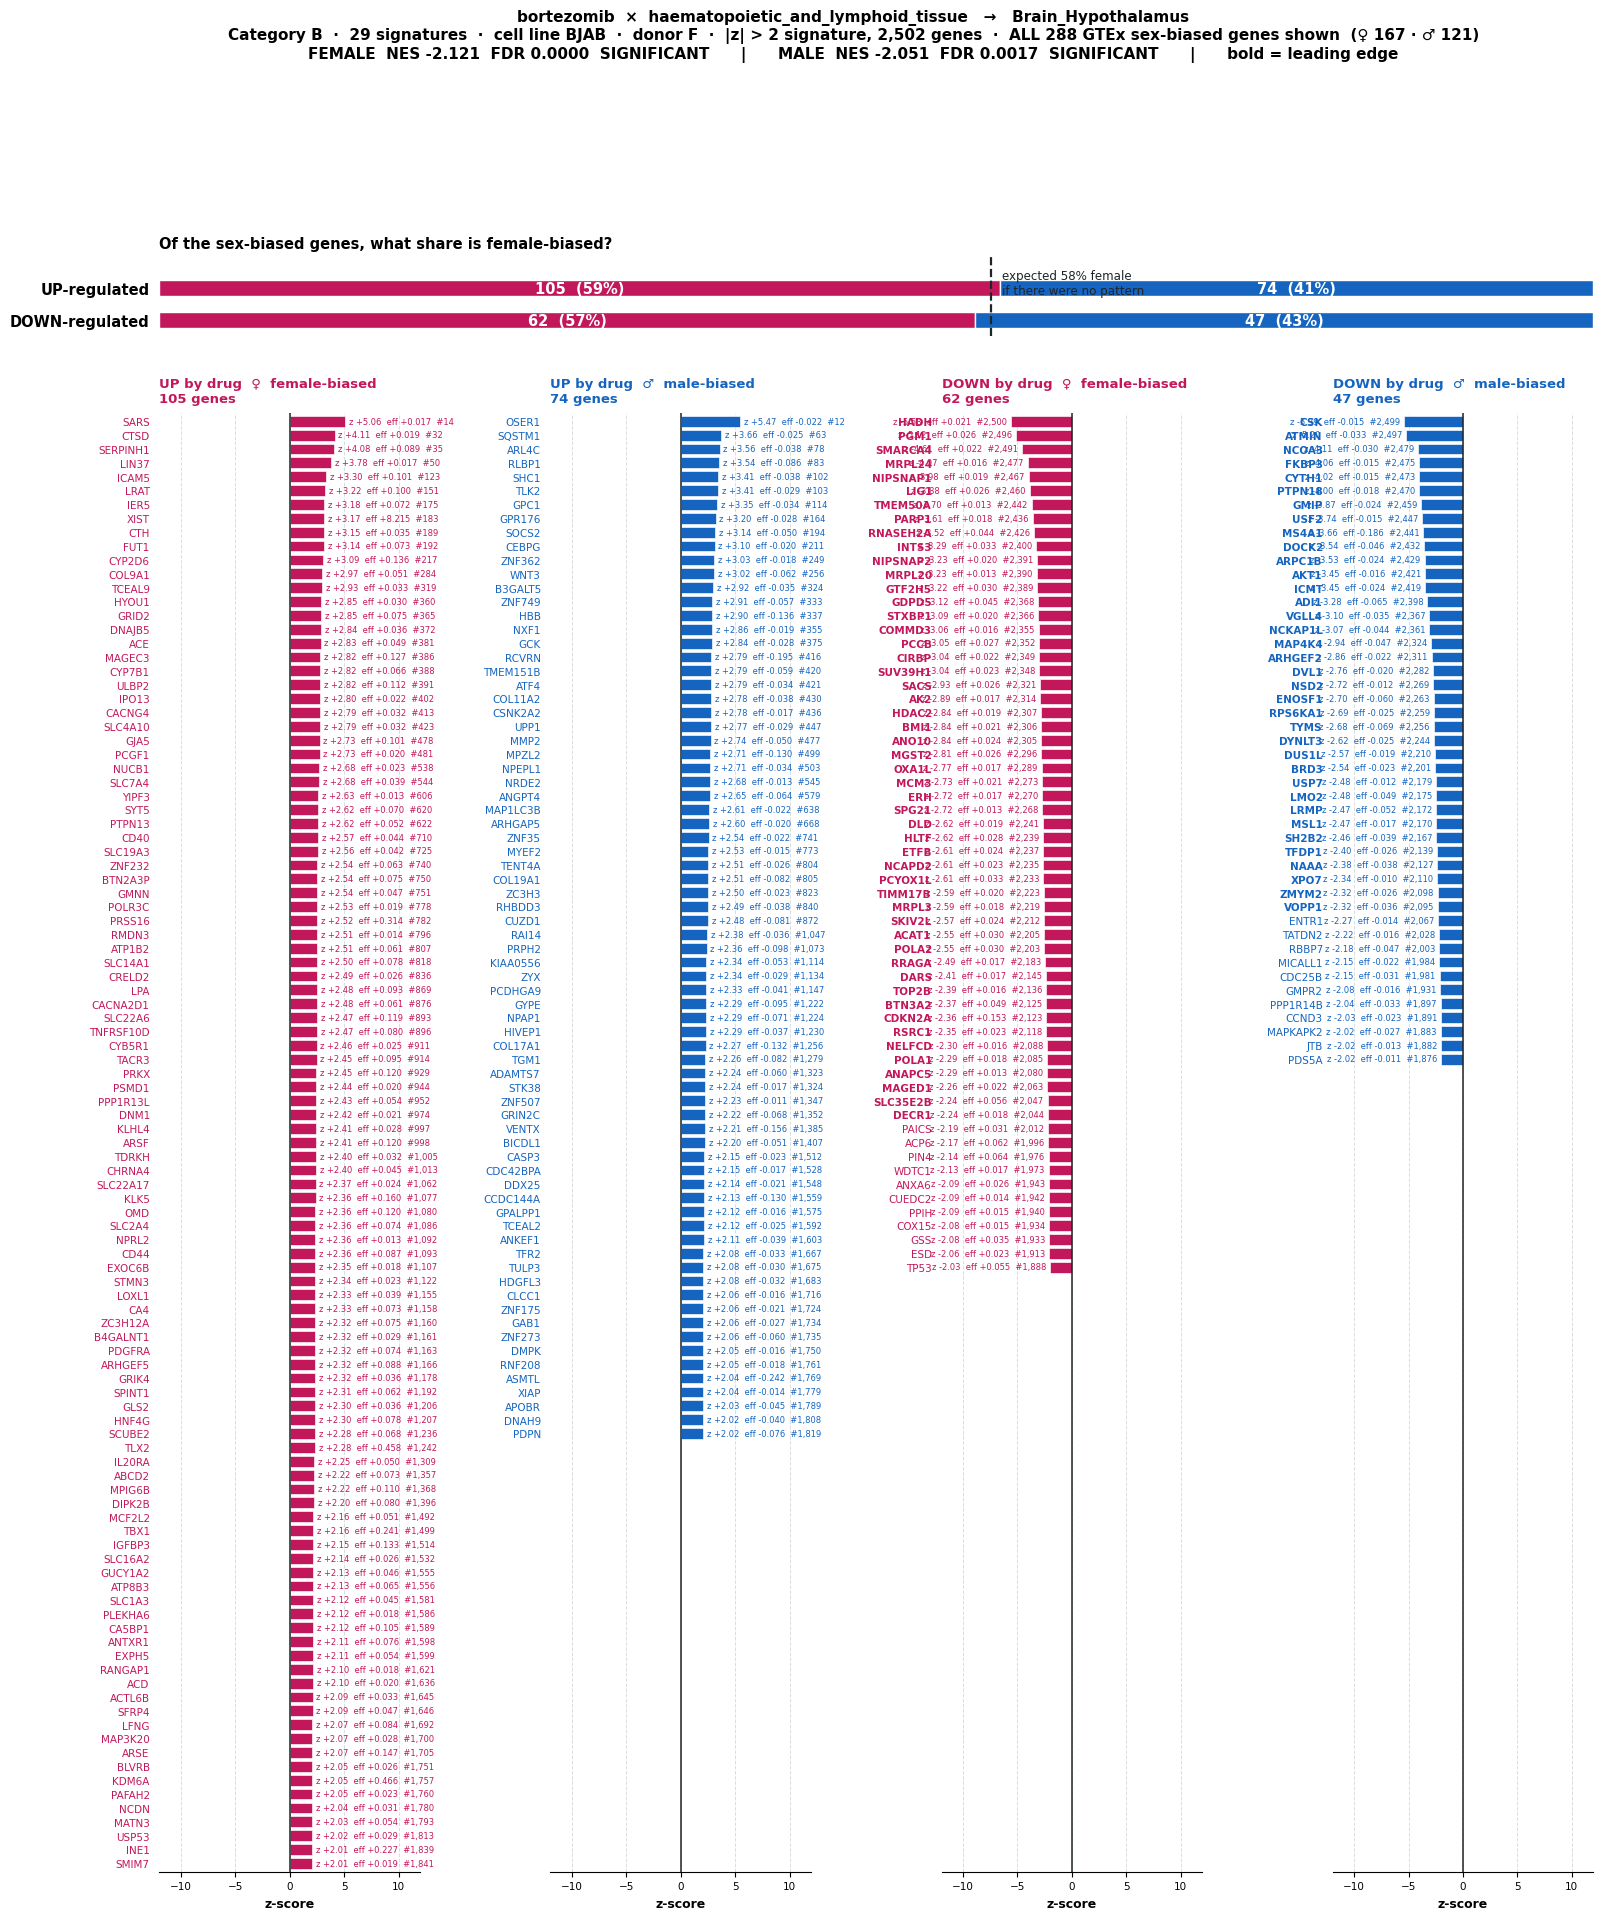


29 signatures  ·  cell line BJAB  ·  donor F   [filtered]   ranked list 2,502 genes
sex-biased matched : 288   (♀ 167 / ♂ 121)
   UP   ♀  105   ♂   74
   DOWN ♀   62   ♂   47    -> DOWN is 57% female vs 58% expected
gene table saved : /content/drive/MyDrive/Project59/results/sexgenes_bortezomib_Brain_Hypothalam_BJAB_filtered.csv


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


library 2,739  (F 1,397 / M 1,342)
matched 288  (F 167 / M 121)


/tmp/ipykernel_1808/1037610357.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_bortezomib_Brain_Hypothalamus_BJAB_filtered.png


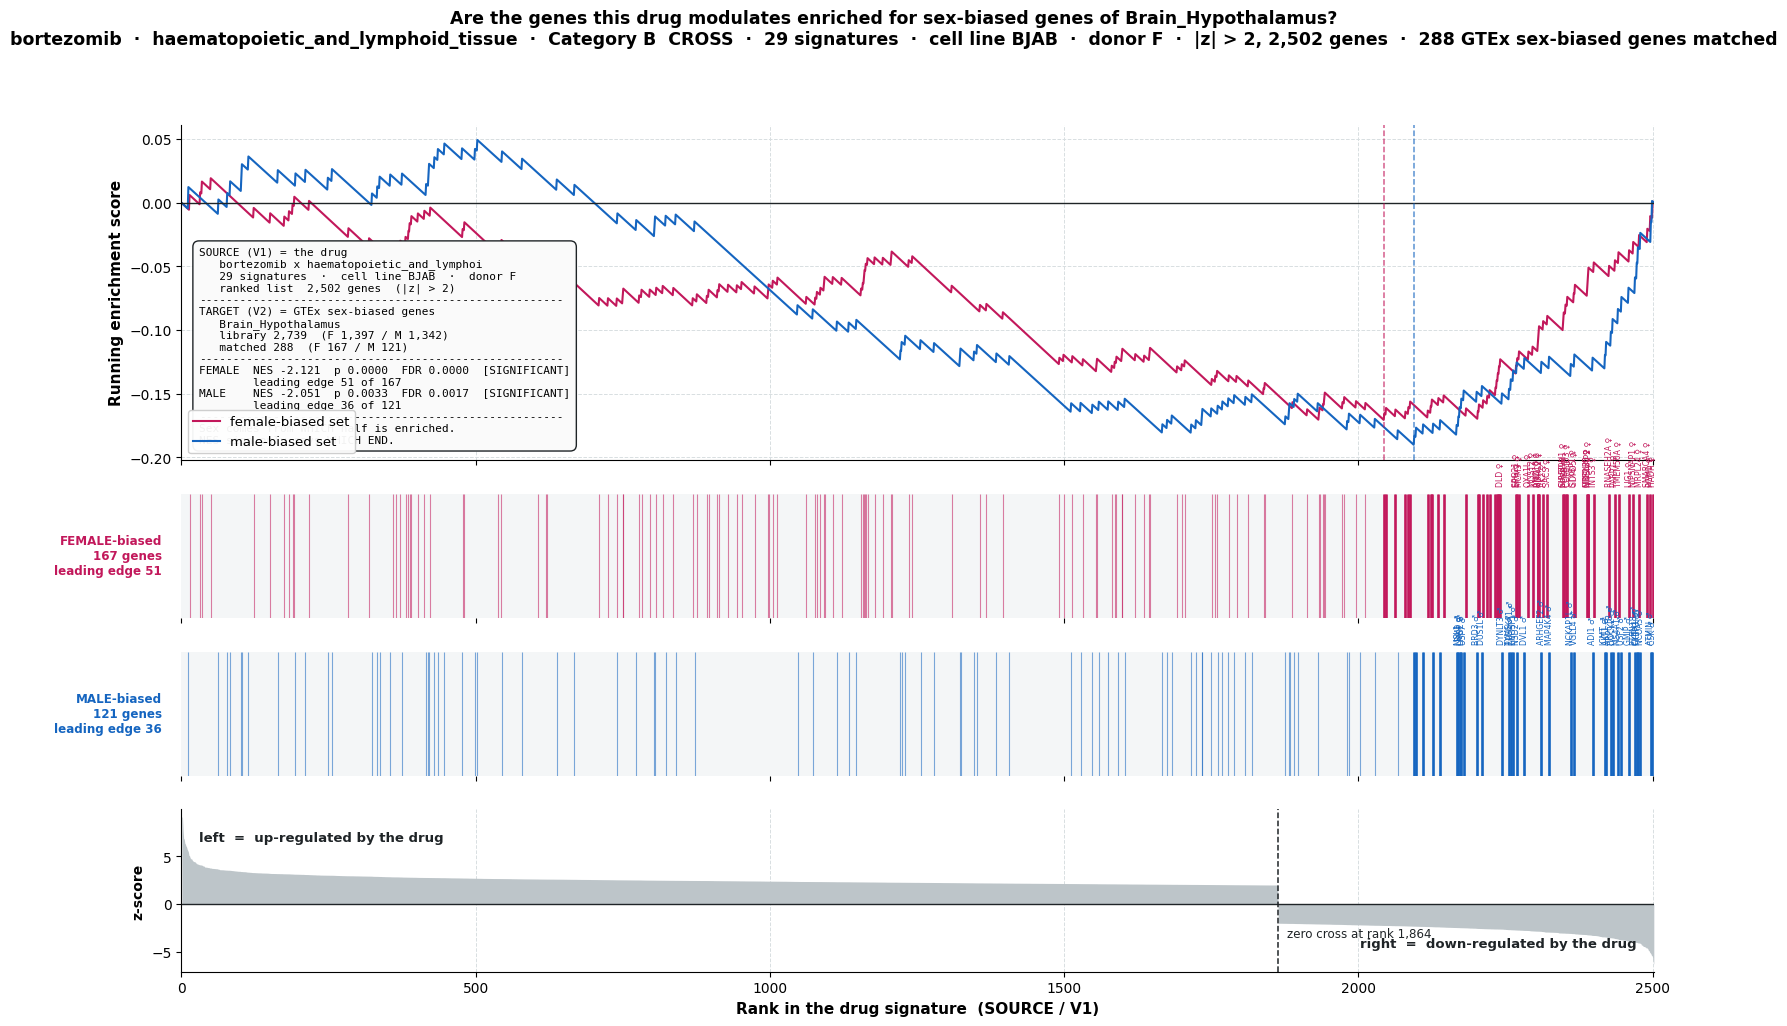


29 signatures  ·  cell line BJAB  ·  donor F   [filtered]
FEMALE  NES -2.121  FDR 0.0000  SIGNIFICANT   (leading edge 51 of 167)
MALE    NES -2.051  FDR 0.0017  SIGNIFICANT   (leading edge 36 of 121)


{'F': (-2.1207386795943104, 0.0, 0.0),
 'M': (-2.0506146363622575, 0.0032679738562091504, 0.0016863406408094434)}

In [76]:
S = sex_panel(DRUG, LIN, T_B, mode='filtered', cell_line=CELL)
sex_enrichment(DRUG, LIN, T_B, mode='filtered', cell_line=CELL)

In [10]:
# ============================================================
#  CELL A  —  restore: gctx + reference + core functions
#  download me 15-20 min lagenge
# ============================================================
!pip install cmapPy gseapy -q

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, json, glob, numpy as np, pandas as pd, gseapy
from cmapPy.pandasGEXpress.parse import parse

BASE = '/content/drive/MyDrive/Project59'
REF  = f'{BASE}/data/reference'

# ---------- gctx ----------
os.makedirs('/content/cmap', exist_ok=True)
gctx_file = '/content/cmap/level5_beta_trt_cp_n720216x12328.gctx'
if os.path.exists(gctx_file):
    print(f"gctx already here: {os.path.getsize(gctx_file)/1e9:.1f} GB")
else:
    print("downloading 33 GB — tab band mat karna\n")
    !cd /content/cmap && curl -O https://cmapreg.s3.amazonaws.com/galenAI/level5_beta_trt_cp_n720216x12328.gctx

gctx_sigs = set(parse(gctx_file, col_meta_only=True).index)
print(f"gctx signatures : {len(gctx_sigs):,}")

# ---------- reference ----------
cmap_to_gtex = {k: set(v) for k, v in json.load(open(f'{REF}/cmap_to_gtex.json')).items()}
gid_to_ensg  = json.load(open(f'{REF}/gid_to_ensg.json'))
top50_names  = json.load(open(f'{REF}/top50_names.json'))
genes_info   = pd.read_csv(f'{BASE}/data/cmap/geneinfo.csv')
sig_known    = pd.read_csv(f'{BASE}/results/sig_known/sig_known.csv', low_memory=False)

# ---------- sbg (GTEx significant sex-biased genes) ----------
cands = ([f'{BASE}/data/gtex/sbgenes_raw.csv'] +
         glob.glob(f'{BASE}/data/gtex/*sbgene*') +
         glob.glob(f'{BASE}/data/**/*signif*sbgene*', recursive=True))
sbg = None
for c in cands:
    if os.path.exists(c):
        sbg = pd.read_csv(c, sep='\t' if c.endswith(('.txt','.tsv')) else ',')
        print(f"sbg loaded from : {c}  ({len(sbg):,} rows)"); break
if sbg is None:
    raise FileNotFoundError("sbg nahi mila — data/gtex folder ki listing bhejo")

# ---------- ENS2SYM ----------
gi = genes_info[['gene_id','gene_symbol']].astype({'gene_id':str}).copy()
gi['ens'] = gi['gene_id'].map(gid_to_ensg)
ENS2SYM = dict(gi.dropna(subset=['ens']).drop_duplicates('ens')[['ens','gene_symbol']].values)
print(f"ENS2SYM         : {len(ENS2SYM):,} genes")

# ---------- palette ----------
F_COL, M_COL = '#C2185B', '#1565C0'
INK, GRID, GREY, MUTED = '#1F2427', '#D8DEE1', '#BDC5C9', '#6E777C'
MIN_SET = 15

# ============================================================
#  CORE FUNCTIONS
# ============================================================
def build_V1(drug, lineage, mode='full', sig_id=None, cell_line=None, quiet=False):
    s = sig_known[(sig_known['cmap_name'] == drug) &
                  (sig_known['cell_lineage'] == lineage)]
    s = s[s['sig_id'].isin(gctx_sigs)]
    if sig_id    is not None: s = s[s['sig_id']     == sig_id]
    elif cell_line is not None: s = s[s['cell_iname'] == cell_line]
    ids = s['sig_id'].tolist()
    if not ids:
        print("   koi signature nahi mila"); return None, None
    mz = parse(gctx_file, cid=ids).data_df
    mz = mz.iloc[:, 0] if len(ids) == 1 else mz.mean(axis=1)
    n0 = len(mz)
    if mode != 'full':
        mz = mz[mz.abs() > 2]
        if not quiet: print(f"   |z| > 2 : {n0:,} -> {len(mz):,} genes")
        if len(mz) == 0:
            print("   filter ke baad kuch nahi bacha"); return None, None
    cl = sorted(s['cell_iname'].dropna().unique())
    sx = sorted(s['donor_sex'].dropna().unique())
    src = (f"{len(ids)} signature{'s' if len(ids)>1 else ''}  ·  "
           f"cell line {cl[0] if len(cl)==1 else f'{len(cl)} lines'}  ·  "
           f"donor {sx[0] if len(sx)==1 else '/'.join(sx)}")
    d = pd.DataFrame({'gene_id': mz.index.astype(str), 'z': mz.values})
    d['ensembl_id'] = d['gene_id'].map(gid_to_ensg)
    V1 = (d.dropna(subset=['ensembl_id'])
            .groupby('ensembl_id')['z'].mean().sort_values(ascending=False))
    return V1, src


def split_sets(tissue, effsize_min=0.0):
    t = sbg[sbg['tissue'] == tissue].copy()
    t['ens'] = t['gene'].astype(str).str.split('.').str[0]
    eff = t.groupby('ens')['effsize'].mean()
    eff = eff[eff.abs() >= effsize_min]
    return {f'{tissue}__FEMALE': set(eff[eff > 0].index),
            f'{tissue}__MALE'  : set(eff[eff < 0].index)}


def _running_es(rnk, gene_set):
    hits = np.isin(rnk.index.values, list(gene_set))
    w    = np.abs(rnk.values)
    if hits.sum() == 0 or (~hits).sum() == 0:
        return np.zeros(len(rnk)), hits
    step = np.where(hits, w / w[hits].sum(), -1.0 / (~hits).sum())
    return np.cumsum(step), hits


def _leading_edge(cum, hits):
    i   = int(np.argmax(np.abs(cum)))
    es  = float(cum[i])
    idx = np.where(hits)[0]
    return i, es, (idx[idx >= i] if es < 0 else idx[idx <= i])


def _gsea(V1, tissue, n_perm=1000, quiet=False):
    halves = split_sets(tissue)
    Fk, Mk = f'{tissue}__FEMALE', f'{tissue}__MALE'
    idx = set(V1.index)
    use = {k: v for k, v in halves.items() if len(v & idx) >= MIN_SET}
    if not quiet:
        for k in halves:
            n = len(halves[k] & idx)
            print(f"   {k.split('__')[1]:<7} matched {n}"
                  + ("" if k in use else f"   SKIP (< {MIN_SET})"))
    if not use:
        print(f"   dono halves {MIN_SET} se chhote"); return None
    res = gseapy.prerank(rnk=V1, gene_sets=use, permutation_num=n_perm,
                         min_size=MIN_SET, max_size=100000, seed=42,
                         no_plot=True, verbose=False)
    r, stat = res.res2d.set_index('Term'), {}
    for key, lab in [(Fk, 'F'), (Mk, 'M')]:
        stat[lab] = ((float(r.loc[key, 'NES']), float(r.loc[key, 'NOM p-val']),
                      float(r.loc[key, 'FDR q-val'])) if key in r.index
                     else (np.nan, np.nan, np.nan))
    gs = V1.index.values
    def le(S):
        cum, hit = _running_es(V1, S)
        return np.array([], int) if hit.sum() == 0 else _leading_edge(cum, hit)[2]
    return dict(gs=gs,
                kF=np.isin(gs, list(halves[Fk])),
                kM=np.isin(gs, list(halves[Mk])),
                stat=stat, leF=le(halves[Fk]), leM=le(halves[Mk]))


def check_sizes(drug, lineage, tissue, sig_id=None, cell_line=None):
    h = split_sets(tissue)
    F, M = h[f'{tissue}__FEMALE'], h[f'{tissue}__MALE']
    home = set(cmap_to_gtex.get(lineage, []))
    print(f"\n{tissue}  library {len(F)+len(M):,}  (F {len(F):,} / M {len(M):,})")
    print(f"category : {'A  HOME' if tissue in home else 'B  CROSS'}")
    print(f"\n{drug} × {lineage} → {tissue}")
    print(f"{'mode':<12}{'ranked list':>14}{'F match':>10}{'M match':>10}   verdict")
    print("-"*62)
    for m in ['full', 'filtered']:
        V1, _ = build_V1(drug, lineage, m, sig_id, cell_line, quiet=True)
        if V1 is None: continue
        i = set(V1.index); nf, nm = len(F & i), len(M & i)
        ok = ('both halves' if min(nf, nm) >= MIN_SET else
              'one half'    if max(nf, nm) >= MIN_SET else 'NEITHER — skip')
        print(f"{m:<12}{len(V1):>14,}{nf:>10}{nm:>10}   {ok}")
    print(f"\n(ek half ko kam se kam {MIN_SET} genes chahiye)")

print("\nCELL A ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.2/150.2 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 7.3 MB/s eta 0:00:00
Mounted at /content/drive
downloading 33 GB — tab band mat karna

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 33.0G  100 33.0G    0     0  36.8M      0  0:15:18  0:15:18 --:--:-- 39.5M


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


gctx signatures : 720,216
sbg loaded from : /content/drive/MyDrive/Project59/data/gtex/sbgenes_raw.csv  (104,864 rows)
ENS2SYM         : 12,276 genes

CELL A ready


In [11]:
# ============================================================
#  CELL C  —  emetine ka naksha
# ============================================================
DRUG2 = 'emetine'

R = pd.read_csv(f'{BASE}/results/per_signature_v4_ABCD.csv')
CAT = 'cat' if 'cat' in R.columns else 'category'
LIN = 'lineage' if 'lineage' in R.columns else 'cell_lineage'

es = sig_known[(sig_known['cmap_name'] == DRUG2) &
               (sig_known['sig_id'].isin(gctx_sigs))]
e  = R[R['drug'] == DRUG2]

print("="*70); print(DRUG2.upper()); print("="*70)
print(f"signatures : {es['sig_id'].nunique():,}")
print(f"cell lines : {es['cell_iname'].nunique()}")
print(f"lineages   : {es['cell_lineage'].nunique()}")
print(f"donor sex  : {dict(es['donor_sex'].value_counts())}")
print(f"categories : {dict(e[CAT].value_counts())}")

L = (es.groupby('cell_lineage')
       .agg(sigs=('sig_id','nunique'), lines=('cell_iname','nunique'))
       .sort_values('sigs', ascending=False))
print(f"\n{'lineage':<42}{'signatures':>12}{'cell_lines':>12}")
print("-"*66)
for l, r in L.iterrows():
    print(f"{l:<42}{r.sigs:>12,}{r.lines:>12}")

for c, label in [('A', 'CATEGORY A  —  home tissue'),
                 ('B', 'CATEGORY B  —  cross tissue (top 10)')]:
    sub = e[e[CAT] == c].copy()
    sub = sub.merge(L.reset_index().rename(columns={'cell_lineage': LIN})[[LIN,'sigs']],
                    on=LIN, how='left')
    cols = [x for x in [LIN,'tissue','NES','FDR','sigs'] if x in sub.columns]
    print(f"\n{'='*70}\n{label}   ({len(sub)})\n{'='*70}")
    print(sub[cols].sort_values('FDR').head(10).to_string(index=False)
          if len(sub) else "   koi nahi")

EMETINE
signatures : 310
cell lines : 95
lineages   : 17
donor sex  : {'F': np.int64(170), 'M': np.int64(140)}
categories : {'C': np.int64(365), 'B': np.int64(219), 'D': np.int64(153), 'A': np.int64(11)}

lineage                                     signatures  cell_lines
------------------------------------------------------------------
lung                                                73          19
breast                                              49           5
skin                                                26           7
ovary                                               26          13
large_intestine                                     24          13
prostate                                            20           4
bone                                                19           4
liver                                               17           4
endometrium                                         15           7
central_nervous_system                               9    

In [12]:
# ============================================================
#  CELL B  —  sex_panel + sex_enrichment
# ============================================================
import numpy as np, pandas as pd, gseapy
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


def sex_panel(drug, lineage, tissue, mode='filtered', sig_id=None,
              cell_line=None, n_perm=1000, save=True):
    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line, quiet=True)
    if V1 is None: return None
    G = _gsea(V1, tissue, n_perm, quiet=True)
    if G is None: return None

    gs, stat = G['gs'], G['stat']
    Fset, Mset = set(gs[G['kF']]), set(gs[G['kM']])
    le = ({V1.index[i] for i in G['leF']} | {V1.index[i] for i in G['leM']})

    t = sbg[sbg['tissue'] == tissue].copy()
    t['ens'] = t['gene'].astype(str).str.split('.').str[0]
    eff = t.groupby('ens')['effsize'].mean()

    D = pd.DataFrame({'ens': V1.index, 'z': V1.values})
    D['rank'] = np.arange(1, len(D) + 1)
    D['gene'] = D['ens'].map(lambda g: ENS2SYM.get(g, g))
    D['sex']  = np.where(D['ens'].isin(Fset), 'F',
                np.where(D['ens'].isin(Mset), 'M', ''))
    D['eff']  = D['ens'].map(eff)
    D['LE']   = D['ens'].isin(le)

    S = D[D['sex'] != ''].copy()
    if len(S) == 0: print("koi sex-biased gene match nahi hua"); return None
    if len(S) > 400: print(f"WARNING: {len(S)} genes — figure bahut lamba hoga")

    blocks = [('UP by drug  \u2640  female-biased',
               S[(S.sex=='F') & (S.z>0)].sort_values('z', ascending=False), F_COL),
              ('UP by drug  \u2642  male-biased',
               S[(S.sex=='M') & (S.z>0)].sort_values('z', ascending=False), M_COL),
              ('DOWN by drug  \u2640  female-biased',
               S[(S.sex=='F') & (S.z<0)].sort_values('z'), F_COL),
              ('DOWN by drug  \u2642  male-biased',
               S[(S.sex=='M') & (S.z<0)].sort_values('z'), M_COL)]
    upF, upM, dnF, dnM = [len(b[1]) for b in blocks]
    nF, nM = int((S.sex=='F').sum()), int((S.sex=='M').sum())
    base = 100 * nF / len(S)
    rows = max(1, max(len(b[1]) for b in blocks))

    fig = plt.figure(figsize=(18.5, max(8.5, .175*rows + 2.6)))
    gsp = fig.add_gridspec(2, 4, height_ratios=[1, max(6, .175*rows)],
                           hspace=.10, wspace=.50)
    axS = fig.add_subplot(gsp[0, :])
    for i, (lab, f, m) in enumerate([('DOWN-regulated', dnF, dnM),
                                     ('UP-regulated',   upF, upM)]):
        tot = f + m; pf = 100*f/tot if tot else 0
        axS.barh(i, pf, .5, color=F_COL, edgecolor='white')
        axS.barh(i, 100-pf, .5, left=pf, color=M_COL, edgecolor='white')
        if f: axS.text(pf/2, i, f'{f}  ({pf:.0f}%)', ha='center', va='center',
                       color='white', fontsize=10.5, fontweight='bold')
        if m: axS.text(pf+(100-pf)/2, i, f'{m}  ({100-pf:.0f}%)', ha='center',
                       va='center', color='white', fontsize=10.5, fontweight='bold')
    axS.axvline(base, ls='--', lw=1.6, color=INK)
    axS.text(base+.8, 1.62, f'expected {base:.0f}% female\nif there were no pattern',
             fontsize=8.6, color=INK, va='top')
    axS.set_yticks([0,1]); axS.set_yticklabels(['DOWN-regulated','UP-regulated'],
                                               fontsize=10.5, fontweight='bold')
    axS.set_xlim(0,100); axS.set_ylim(-.5, 2.0); axS.set_xticks([])
    axS.tick_params(left=False)
    axS.spines[['top','right','left','bottom']].set_visible(False)
    axS.set_title('Of the sex-biased genes, what share is female-biased?',
                  fontsize=10.5, fontweight='bold', loc='left', pad=6)

    pad = S['z'].abs().max() * 2.15
    for j, (lab, B, col) in enumerate(blocks):
        ax = fig.add_subplot(gsp[1, j]); B = B.reset_index(drop=True)
        if len(B):
            y = np.arange(len(B))
            ax.barh(y, B['z'], .78, color=col, edgecolor='white', linewidth=.45)
            for i, r in enumerate(B.itertuples()):
                ax.text(r.z + (pad*.03 if r.z > 0 else -pad*.03), i,
                        f"z {r.z:+.2f}  eff {r.eff:+.3f}  #{r.rank:,}",
                        va='center', ha='left' if r.z > 0 else 'right',
                        fontsize=6.0, color=col)
            ax.set_yticks(y); ax.set_yticklabels(B['gene'], fontsize=6.6)
            for tl, le_ in zip(ax.get_yticklabels(), B['LE']):
                tl.set_color(col)
                if le_: tl.set_fontweight('bold')
        ax.axvline(0, color=INK, lw=1.1)
        ax.set_xlim(-pad, pad); ax.set_ylim(rows-.4, -.6)
        ax.set_title(f'{lab}\n{len(B)} genes', fontsize=9.5,
                     fontweight='bold', color=col, loc='left', pad=8)
        ax.set_xlabel('z-score', fontsize=9, fontweight='bold')
        ax.grid(axis='x', color=GRID, lw=.7, ls='--'); ax.set_axisbelow(True)
        ax.spines[['top','right','left']].set_visible(False)
        ax.tick_params(left=False, labelsize=7.5)

    g  = lambda k,i: stat[k][i] if k in stat else float('nan')
    sg = lambda q: 'SIGNIFICANT' if (q == q and q < 0.05) else 'not significant'
    home = set(cmap_to_gtex.get(lineage, []))
    fig.suptitle(
        f'{drug}  ×  {lineage}   →   {tissue}\n'
        f'Category {"A  HOME" if tissue in home else "B  CROSS"}  ·  {src}  ·  '
        f'{"full" if mode=="full" else "|z| > 2"}, {len(V1):,} genes  ·  '
        f'ALL {len(S)} sex-biased genes shown  (\u2640 {nF} · \u2642 {nM})\n'
        f'FEMALE  NES {g("F",0):+.3f}  FDR {g("F",2):.4f}  {sg(g("F",2))}      |      '
        f'MALE  NES {g("M",0):+.3f}  FDR {g("M",2):.4f}  {sg(g("M",2))}      |      '
        f'bold = leading edge', fontsize=11, fontweight='bold', y=.998)
    plt.tight_layout(rect=[0, 0, 1, .965])
    tag = (sig_id or cell_line or 'lineage').replace(':', '_')
    if save:
        fn = f'{BASE}/figures/panel_{drug}_{tissue[:16]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=165, bbox_inches='tight'); print("saved:", fn)
    plt.show()
    print(f"\n{src}   [{mode}]   ranked list {len(V1):,}")
    print(f"sex-biased matched : {len(S)}   (\u2640 {nF} / \u2642 {nM})")
    print(f"   UP   \u2640 {upF:>4}   \u2642 {upM:>4}")
    print(f"   DOWN \u2640 {dnF:>4}   \u2642 {dnM:>4}   -> DOWN is "
          f"{100*dnF/max(1,dnF+dnM):.0f}% female vs {base:.0f}% expected")
    S[['gene','ens','sex','z','rank','eff','LE']].sort_values('z', ascending=False)\
     .to_csv(f'{BASE}/results/sexgenes_{drug}_{tissue[:16]}_{tag}_{mode}.csv', index=False)
    return S


def sex_enrichment(drug, lineage, tissue, mode='filtered', sig_id=None,
                   cell_line=None, n_perm=1000, max_labels=30, save=True):
    V1, src = build_V1(drug, lineage, mode, sig_id, cell_line, quiet=True)
    if V1 is None: return None
    halves = split_sets(tissue)
    Fk, Mk = f'{tissue}__FEMALE', f'{tissue}__MALE'
    idx = set(V1.index); mF, mM = halves[Fk] & idx, halves[Mk] & idx
    libN = len(halves[Fk]) + len(halves[Mk])
    print(f"library {libN:,}  ->  matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})")

    G = _gsea(V1, tissue, n_perm, quiet=True)
    if G is None: return None
    stat = G['stat']

    def walk(S_):
        cum, hit = _running_es(V1, S_)
        if hit.sum() == 0: return np.zeros(len(V1)), hit, 0, np.array([], int)
        i, es, le = _leading_edge(cum, hit); return cum, hit, i, le
    cumF, hitF, iF, leF = walk(halves[Fk])
    cumM, hitM, iM, leM = walk(halves[Mk])

    z, x = V1.values, np.arange(1, len(V1)+1)
    zero = int((z > 0).sum())
    home = set(cmap_to_gtex.get(lineage, []))
    sg = lambda q: 'SIGNIFICANT' if (q == q and q < 0.05) else 'not significant'

    fig = plt.figure(figsize=(19, 11))
    gsp = fig.add_gridspec(4, 1, height_ratios=[3.1, 1.15, 1.15, 1.5], hspace=.18)
    ax = fig.add_subplot(gsp[0])
    ax.plot(x, cumF, color=F_COL, lw=1.5, label='female-biased set')
    ax.plot(x, cumM, color=M_COL, lw=1.5, label='male-biased set')
    ax.axhline(0, color=INK, lw=1.0)
    if hitF.sum(): ax.axvline(iF+1, color=F_COL, ls='--', lw=1.1, alpha=.7)
    if hitM.sum(): ax.axvline(iM+1, color=M_COL, ls='--', lw=1.1, alpha=.7)
    ax.set_ylabel('Running enrichment score', fontsize=11, fontweight='bold')
    ax.set_xlim(0, len(V1)); ax.set_xticklabels([])
    ax.grid(color=GRID, lw=.7, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.legend(loc='lower left', fontsize=9.5, framealpha=.95)
    ax.text(.012, .045,
        f"SOURCE (V1) = the drug\n   {drug} x {lineage[:26]}\n   {src}\n"
        f"   ranked list  {len(V1):,} genes  "
        f"({'no filter' if mode=='full' else '|z| > 2'})\n{'-'*54}\n"
        f"TARGET (V2) = GTEx sex-biased genes\n   {tissue}\n"
        f"   library {libN:,}  (F {len(halves[Fk]):,} / M {len(halves[Mk]):,})\n"
        f"   matched {len(mF)+len(mM):,}  (F {len(mF)} / M {len(mM)})\n{'-'*54}\n"
        f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  [{sg(stat['F'][2])}]\n"
        f"        leading edge {len(leF)} of {int(hitF.sum())}\n"
        f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  [{sg(stat['M'][2])}]\n"
        f"        leading edge {len(leM)} of {int(hitM.sum())}",
        transform=ax.transAxes, fontsize=8.0, family='monospace',
        va='bottom', ha='left',
        bbox=dict(boxstyle='round,pad=0.55', facecolor='#FAFAFA',
                  edgecolor=INK, linewidth=1.0))

    for k, (hit, le, col, lab, tot) in enumerate([
            (hitF, leF, F_COL, 'FEMALE-biased', len(mF)),
            (hitM, leM, M_COL, 'MALE-biased',   len(mM))]):
        axb = fig.add_subplot(gsp[1+k])
        axb.vlines(np.where(hit)[0]+1, 0, 1, color=col, lw=.9, alpha=.55)
        if len(le):
            axb.vlines(le+1, 0, 1, color=col, lw=2.0)
            sel = le if len(le) <= max_labels else le[np.argsort(-np.abs(z[le]))][:max_labels]
            for i in sorted(sel):
                axb.text(i+1, 1.06, f"{ENS2SYM.get(V1.index[i], V1.index[i])} "
                         f"{'\u2640' if col==F_COL else '\u2642'}",
                         rotation=90, fontsize=5.8, color=col, ha='center', va='bottom')
        axb.set_xlim(0, len(V1)); axb.set_ylim(0,1)
        axb.set_yticks([]); axb.set_xticklabels([])
        axb.set_ylabel(f'{lab}\n{tot} genes\nleading edge {len(le)}',
                       fontsize=8.6, fontweight='bold', color=col, rotation=0,
                       ha='right', va='center', labelpad=14)
        axb.spines[['top','right','left','bottom']].set_visible(False)
        axb.set_facecolor('#F4F6F7')

    axz = fig.add_subplot(gsp[3])
    axz.fill_between(x, z, 0, color=GREY, lw=0)
    axz.axhline(0, color=INK, lw=1.0); axz.axvline(zero, color=INK, ls='--', lw=1.1)
    axz.text(zero + len(V1)*.006, z.min()*.55, f'zero cross at rank {zero:,}',
             fontsize=8.6, color=INK)
    axz.text(len(V1)*.012, z.max()*.72, 'left  =  up-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK)
    axz.text(len(V1)*.988, z.min()*.72, 'right  =  down-regulated by the drug',
             fontsize=9.5, fontweight='bold', color=INK, ha='right')
    axz.set_xlim(0, len(V1))
    axz.set_ylabel('z-score', fontsize=10, fontweight='bold')
    axz.set_xlabel('Rank in the drug signature  (SOURCE / V1)',
                   fontsize=11, fontweight='bold')
    axz.grid(axis='x', color=GRID, lw=.7, ls='--'); axz.set_axisbelow(True)
    axz.spines[['top','right']].set_visible(False)

    fig.suptitle(
        f'Are the genes this drug modulates enriched for sex-biased genes of {tissue}?\n'
        f'{drug}  ·  {lineage}  ·  '
        f'Category {"A  HOME" if tissue in home else "B  CROSS"}  ·  {src}  ·  '
        f'{"no filter" if mode=="full" else "|z| > 2"}, {len(V1):,} genes  ·  '
        f'{len(mF)+len(mM)} GTEx sex-biased genes matched',
        fontsize=12.5, fontweight='bold', y=.985)
    plt.tight_layout(rect=[0, 0, 1, .955])
    tag = (sig_id or cell_line or 'lineage').replace(':', '_')
    if save:
        fn = f'{BASE}/figures/enrich_{drug}_{tissue[:18]}_{tag}_{mode}.png'
        plt.savefig(fn, dpi=165, bbox_inches='tight'); print("saved:", fn)
    plt.show()
    print(f"\n{src}   [{mode}]")
    print(f"FEMALE  NES {stat['F'][0]:+.3f}  FDR {stat['F'][2]:.4f}  {sg(stat['F'][2])}")
    print(f"MALE    NES {stat['M'][0]:+.3f}  FDR {stat['M'][2]:.4f}  {sg(stat['M'][2])}")
    return stat

print("CELL B ready")

CELL B ready


In [13]:
# ============================================================
#  CELL D  —  emetine × lung → Adipose_Visceral_Omentum
# ============================================================
DRUG = 'emetine'
LIN  = 'lung'
T_B  = 'Adipose_Visceral_Omentum'

# ---- lung ka home tissue kaunsa hai? ----
print("lung ke home tissues (GTEx) :", sorted(cmap_to_gtex.get(LIN, [])))

# ---- signatures ----
s = sig_known[(sig_known['cmap_name'] == DRUG) &
              (sig_known['cell_lineage'] == LIN)]
s = s[s['sig_id'].isin(gctx_sigs)]
print(f"\n{DRUG} × {LIN}")
print(f"   signatures : {len(s)}")
print(f"   cell lines : {s['cell_iname'].nunique()}")
print(f"   donor sex  : {dict(s['donor_sex'].value_counts())}")

# ---- pre-flight ----
check_sizes(DRUG, LIN, T_B)

lung ke home tissues (GTEx) : ['Lung']

emetine × lung
   signatures : 73
   cell lines : 19
   donor sex  : {'M': np.int64(58), 'F': np.int64(15)}

Adipose_Visceral_Omentum  library 2,438  (F 1,178 / M 1,260)
category : B  CROSS

emetine × lung → Adipose_Visceral_Omentum
mode           ranked list   F match   M match   verdict
--------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


full                12,276       698       765   both halves


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


filtered               470        18        26   both halves

(ek half ko kam se kam 15 genes chahiye)


In [78]:
import numpy as np, pandas as pd

DRUG, LIN = 'bortezomib', 'haematopoietic_and_lymphoid_tissue'
TIS, CELL = 'Brain_Hypothalamus', 'BJAB'      # ya jo run dikhana ho

V1, src = build_V1(DRUG, LIN, 'filtered', cell_line=CELL, quiet=True)
h = split_sets(TIS)
F = h[f'{TIS}__FEMALE'] & set(V1.index)
M = h[f'{TIS}__MALE']   & set(V1.index)

z, ens = V1.values, V1.index
up_n, dn_n = int((z > 0).sum()), int((z < 0).sum())
tot = len(V1)

rows = []
for lab, S in [('FEMALE', F), ('MALE', M), ('BOTH', F | M)]:
    m  = np.isin(ens, list(S))
    oU, oD = int((m & (z > 0)).sum()), int((m & (z < 0)).sum())
    eU, eD = len(S) * up_n / tot, len(S) * dn_n / tot
    rows.append(dict(set=lab, total=len(S),
                     UP_obs=oU, UP_exp=round(eU, 1), UP_ratio=round(oU/eU, 2),
                     DN_obs=oD, DN_exp=round(eD, 1), DN_ratio=round(oD/eD, 2)))

print(f"{DRUG} × {LIN} → {TIS}   [{CELL}]")
print(f"ranked list {tot:,}   UP region {up_n:,} ({100*up_n/tot:.0f}%)   "
      f"DOWN region {dn_n:,} ({100*dn_n/tot:.0f}%)\n")
print(pd.DataFrame(rows).to_string(index=False))
print("\nratio 1.0 = exactly as expected by chance")
print("ratio > 1 = more genes than the region's size allows  ->  enrichment")

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


bortezomib × haematopoietic_and_lymphoid_tissue → Brain_Hypothalamus   [BJAB]
ranked list 2,502   UP region 1,863 (74%)   DOWN region 639 (26%)

   set  total  UP_obs  UP_exp  UP_ratio  DN_obs  DN_exp  DN_ratio
FEMALE    167     105   124.3      0.84      62    42.7      1.45
  MALE    121      74    90.1      0.82      47    30.9      1.52
  BOTH    288     179   214.4      0.83     109    73.6      1.48

ratio 1.0 = exactly as expected by chance
ratio > 1 = more genes than the region's size allows  ->  enrichment


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


filtered   ranked list     470   F   18   M   26   OK


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


full       ranked list  12,276   F  698   M  765   OK

-> using mode = 'filtered'



/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/tmp/ipykernel_1499/2947330476.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .965])


saved: /content/drive/MyDrive/Project59/figures/panel_emetine_Adipose_Visceral_lineage_filtered.png


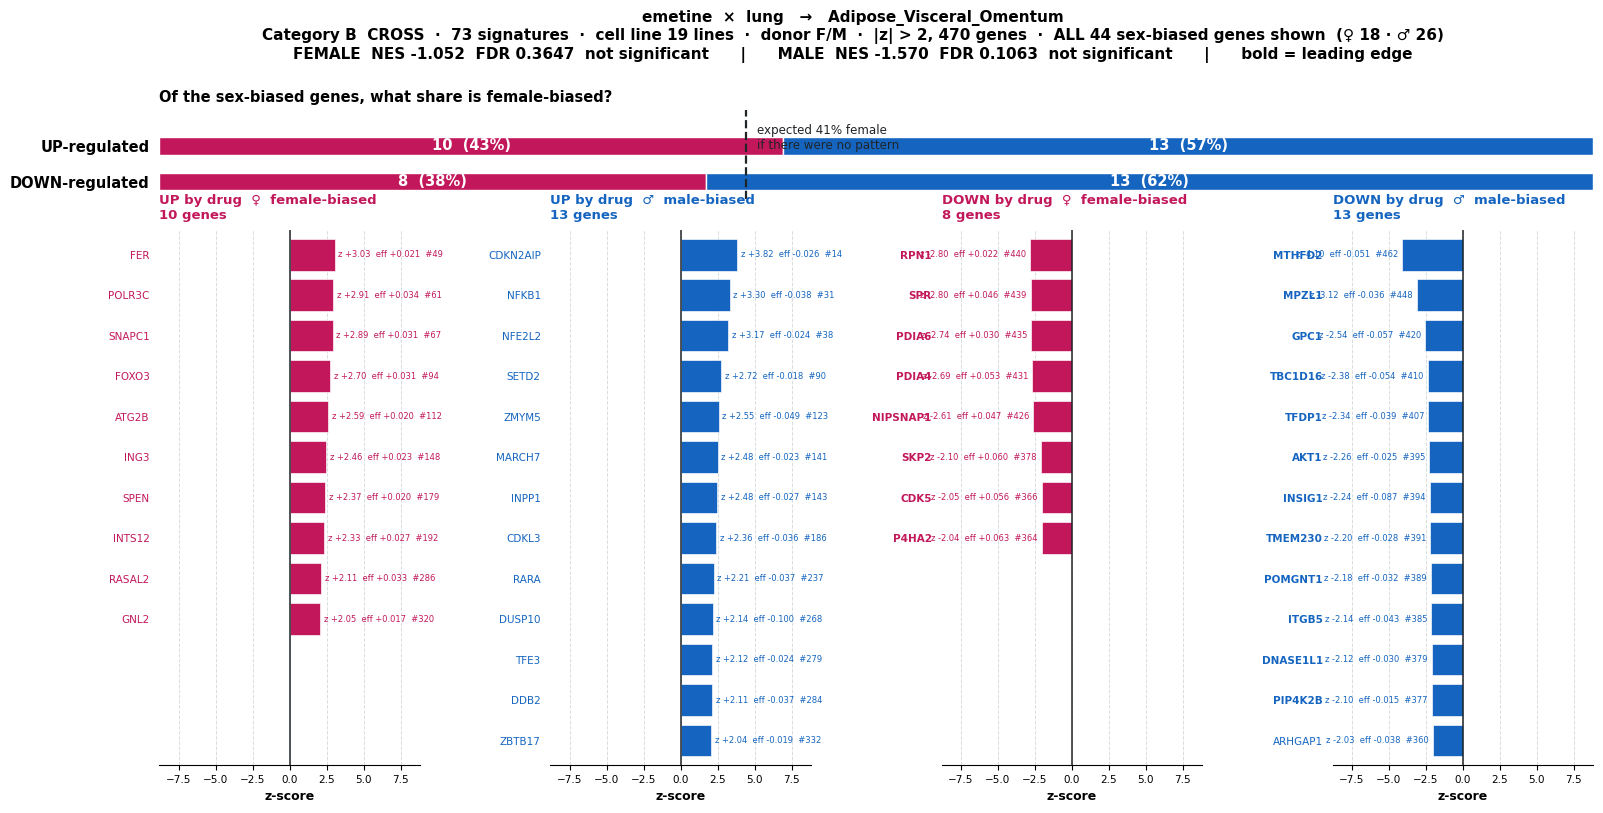


73 signatures  ·  cell line 19 lines  ·  donor F/M   [filtered]   ranked list 470
sex-biased matched : 44   (♀ 18 / ♂ 26)
   UP   ♀   10   ♂   13
   DOWN ♀    8   ♂   13   -> DOWN is 38% female vs 41% expected


/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


library 2,438  ->  matched 44  (F 18 / M 26)


/tmp/ipykernel_1499/2947330476.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_emetine_Adipose_Visceral_O_lineage_filtered.png


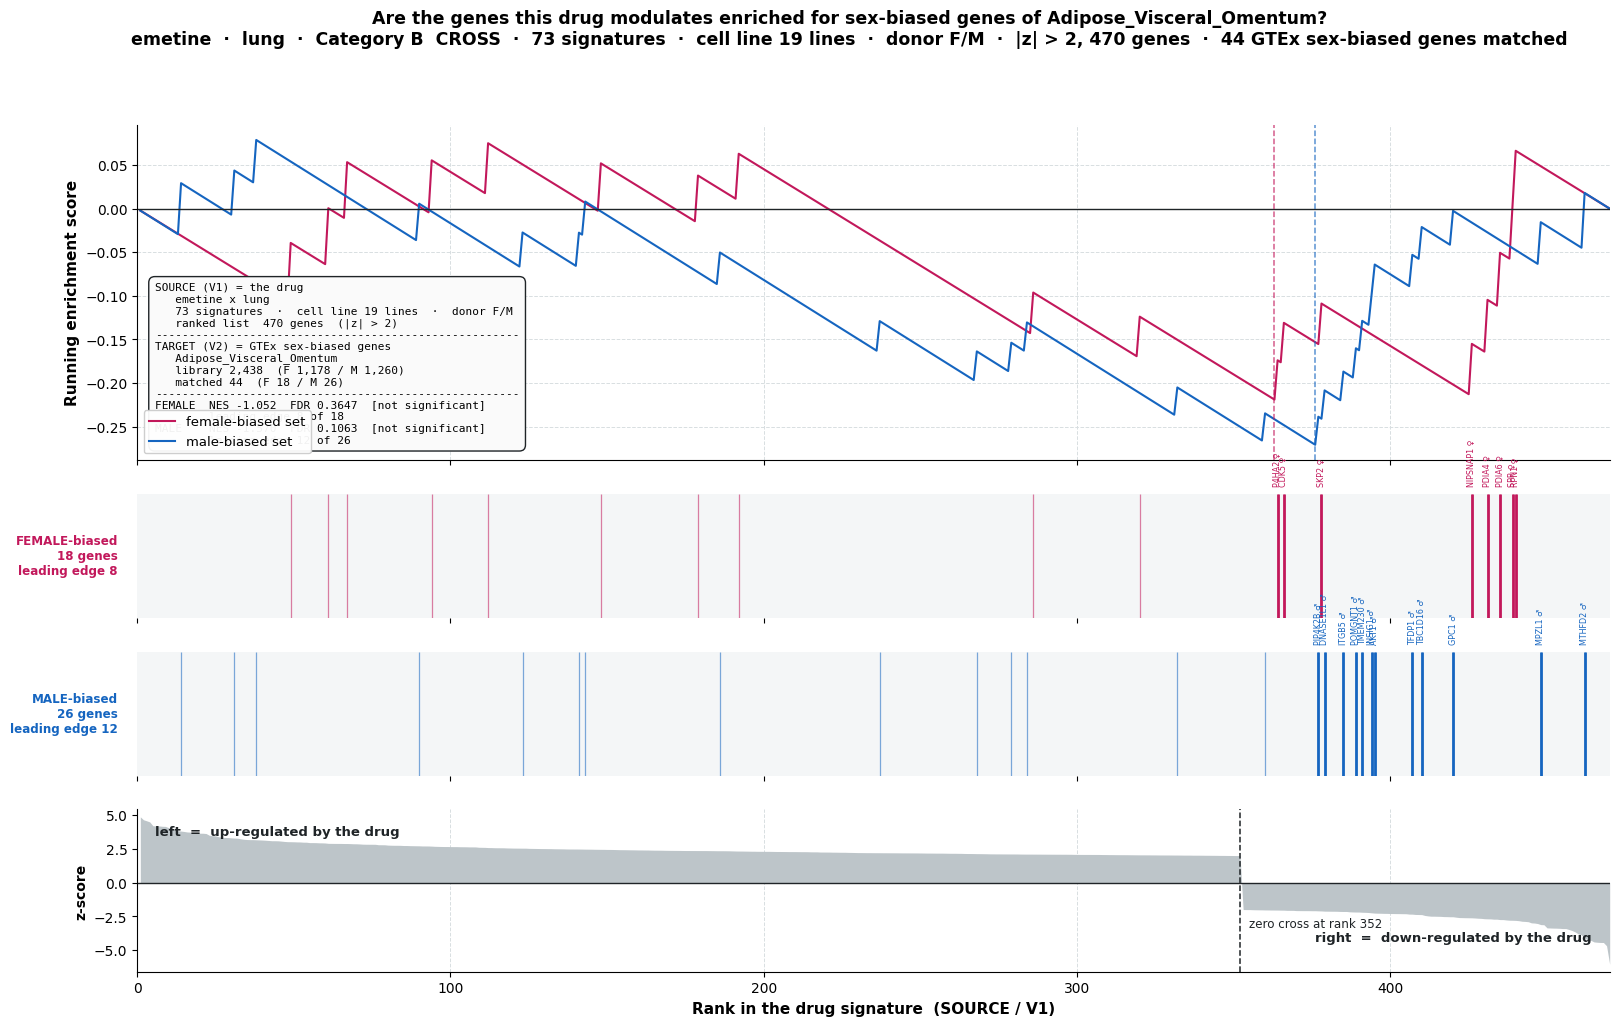


73 signatures  ·  cell line 19 lines  ·  donor F/M   [filtered]
FEMALE  NES -1.052  FDR 0.3647  not significant
MALE    NES -1.570  FDR 0.1063  not significant


{'F': (-1.051909476201194, 0.372960372960373, 0.3647342995169082),
 'M': (-1.570194154992002, 0.05764411027568922, 0.10628019323671498)}

In [14]:
# ============================================================
#  emetine × lung → Adipose_Visceral_Omentum   (Category B)
#  bar chart + enrichment plot
# ============================================================
DRUG = 'emetine'
LIN  = 'lung'
T_B  = 'Adipose_Visceral_Omentum'

# ---- kaunsa mode chalega, apne aap chun lo ----
MODE = None
for m in ['filtered', 'full']:
    V1, _ = build_V1(DRUG, LIN, m, quiet=True)
    if V1 is None: continue
    h = split_sets(T_B); i = set(V1.index)
    nf = len(h[f'{T_B}__FEMALE'] & i); nm = len(h[f'{T_B}__MALE'] & i)
    print(f"{m:<10} ranked list {len(V1):>7,}   F {nf:>4}   M {nm:>4}"
          f"   {'OK' if min(nf,nm) >= 15 else 'half too small'}")
    if MODE is None and min(nf, nm) >= 15:
        MODE = m
MODE = MODE or 'full'
print(f"\n-> using mode = '{MODE}'\n")

# ---- 1. BAR CHART ----
S = sex_panel(DRUG, LIN, T_B, mode=MODE)

# ---- 2. ENRICHMENT PLOT ----
sex_enrichment(DRUG, LIN, T_B, mode=MODE)

In [2]:
# ---------- 1. drive mount + BASE ----------
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, json, pandas as pd, numpy as np
BASE = '/content/drive/MyDrive/Project59'
REF  = f'{BASE}/data/reference'
print("BASE exists:", os.path.exists(BASE))

# ---------- 2. kya kya saved hai, dekh lo ----------
for folder in ['results', 'data/reference', 'data']:
    p = f'{BASE}/{folder}'
    if os.path.exists(p):
        print(f"\n--- {folder} ---")
        for f in sorted(os.listdir(p)):
            sz = os.path.getsize(f'{p}/{f}') / 1e6
            print(f"   {f:<55} {sz:>8.1f} MB")

Mounted at /content/drive
BASE exists: True

--- results ---
   50_drugs                                                     0.0 MB
   Project59_ABCD_MASTER.xlsx                                   0.2 MB
   all_genes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv      0.1 MB
   allgenes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv      0.1 MB
   bortezomib_comparisons.xlsx                                  0.0 MB
   bortezomib_lineage_x_tissue.xlsx                             0.0 MB
   category_A_hits.csv                                          0.0 MB
   per_drug_summary.csv                                         0.0 MB
   per_signature_categories.csv                                 2.7 MB
   per_signature_v3_no_filter.csv                               3.2 MB
   per_signature_v4_ABCD.csv                                    3.2 MB
   sexgenes_bortezomib_Brain_Hypothalam_BJAB_filtered.csv       0.0 MB
   sexgenes_bortezomib_Brain_Hypothalam_lineage_filtered.csv      0.0 MB

In [4]:
# ============================================================
#  STEP 1  —  setup + signature count
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, json, pandas as pd, numpy as np

BASE = '/content/drive/MyDrive/Project59'
REF  = f'{BASE}/data/reference'

# ---- load ----
top50_names = json.load(open(f'{REF}/top50_names.json'))
sig_known   = pd.read_csv(f'{BASE}/results/sig_known/sig_known.csv', low_memory=False)
R           = pd.read_csv(f'{BASE}/results/per_signature_v4_ABCD.csv')

print(f"top50_names : {len(top50_names)} drugs")
print(f"sig_known   : {len(sig_known):,} rows")
print(f"R (pairs)   : {len(R):,} rows")
print(f"R columns   : {list(R.columns)}\n")

# ---- gctx filter, sirf agar file already downloaded hai ----
gctx_file = '/content/cmap/level5_beta_trt_cp_n720216x12328.gctx'
if os.path.exists(gctx_file):
    from cmapPy.pandasGEXpress.parse import parse
    gctx_sigs = set(parse(gctx_file, col_meta_only=True).index)
    print(f"gctx_sigs   : {len(gctx_sigs):,}  (filter lagega)")
else:
    gctx_sigs = None
    print("gctx file nahi hai — bina filter ke chalenge (33 GB download ki zaroorat nahi)")

# ============================================================
#  SAWAAL 1 : 50 drugs me kitne signatures?
# ============================================================
S = sig_known[sig_known['cmap_name'].isin(top50_names)].copy()
if gctx_sigs is not None:
    S = S[S['sig_id'].isin(gctx_sigs)]

print("\n" + "="*64)
print("SAWAAL 1  —  50 drugs ke signatures")
print("="*64)
print(f"signatures (unique sig_id) : {S['sig_id'].nunique():,}")
print(f"drugs                      : {S['cmap_name'].nunique()}")
print(f"cell lines                 : {S['cell_iname'].nunique()}")
print(f"lineages                   : {S['cell_lineage'].nunique()}")
print(f"drug x lineage pairs       : {S.groupby(['cmap_name','cell_lineage']).ngroups:,}")
print(f"\ndonor sex : {dict(S['donor_sex'].value_counts())}")

# ---- Marouen ne 'drug-tissue-dose pairs' bhi poocha tha ----
n_tis = R['tissue'].nunique() if 'tissue' in R.columns else 44
print(f"\nGTEx tissues               : {n_tis}")
print(f"signature x tissue rows    : {S['sig_id'].nunique() * n_tis:,}")

# ---- per drug ----
per_drug = (S.groupby('cmap_name')
              .agg(signatures=('sig_id','nunique'),
                   cell_lines=('cell_iname','nunique'),
                   lineages=('cell_lineage','nunique'))
              .sort_values('signatures', ascending=False))
print(f"\n{'drug':<24}{'signatures':>12}{'cell_lines':>12}{'lineages':>10}")
print("-"*58)
for d, r in per_drug.iterrows():
    print(f"{d:<24}{r.signatures:>12,}{r.cell_lines:>12}{r.lineages:>10}")
print("-"*58)
print(f"{'TOTAL':<24}{per_drug.signatures.sum():>12,}")

S.to_csv(f'{BASE}/results/signatures_50drugs.csv', index=False)
per_drug.to_csv(f'{BASE}/results/signature_counts_per_drug.csv')
print(f"\nsaved: signatures_50drugs.csv  +  signature_counts_per_drug.csv")

Mounted at /content/drive
top50_names : 50 drugs
sig_known   : 596,117 rows
R (pairs)   : 39,996 rows
R columns   : ['drug', 'lineage', 'tissue', 'is_home_tissue', 'n_M', 'n_F', 'n_signatures', 'NES', 'FDR', 'category', 'skip_reason']

gctx file nahi hai — bina filter ke chalenge (33 GB download ki zaroorat nahi)

SAWAAL 1  —  50 drugs ke signatures
signatures (unique sig_id) : 36,523
drugs                      : 50
cell lines                 : 135
lineages                   : 20
drug x lineage pairs       : 909

donor sex : {'F': np.int64(22813), 'M': np.int64(13710)}

GTEx tissues               : 44
signature x tissue rows    : 1,607,012

drug                      signatures  cell_lines  lineages
----------------------------------------------------------
bortezomib                     7,300         108        19
vorinostat                     2,641         116        20
mitoxantrone                   1,516          92        20
dasatinib                      1,098          79        

Mounted at /content/drive
gctx filter OFF  (file local nahi hai)

50 DRUGS  —  TOTAL SIGNATURES  =  36,523
drugs      : 50
biggest    : bortezomib  (7,300)
smallest   : BRD-K61033289  (241)
median     : 529

drug                        signatures  cell_lines  lineages
------------------------------------------------------------
bortezomib                       7,300         108        19
vorinostat                       2,641         116        20
mitoxantrone                     1,516          92        20
dasatinib                        1,098          79        20
afatinib                           976         100        19
selumetinib                        952         117        19
erlotinib                          888          83        19
gefitinib                          860          82        19
tozasertib                         854         116        19
troglitazone                       820         105        18
BI-2536                            806         107        19

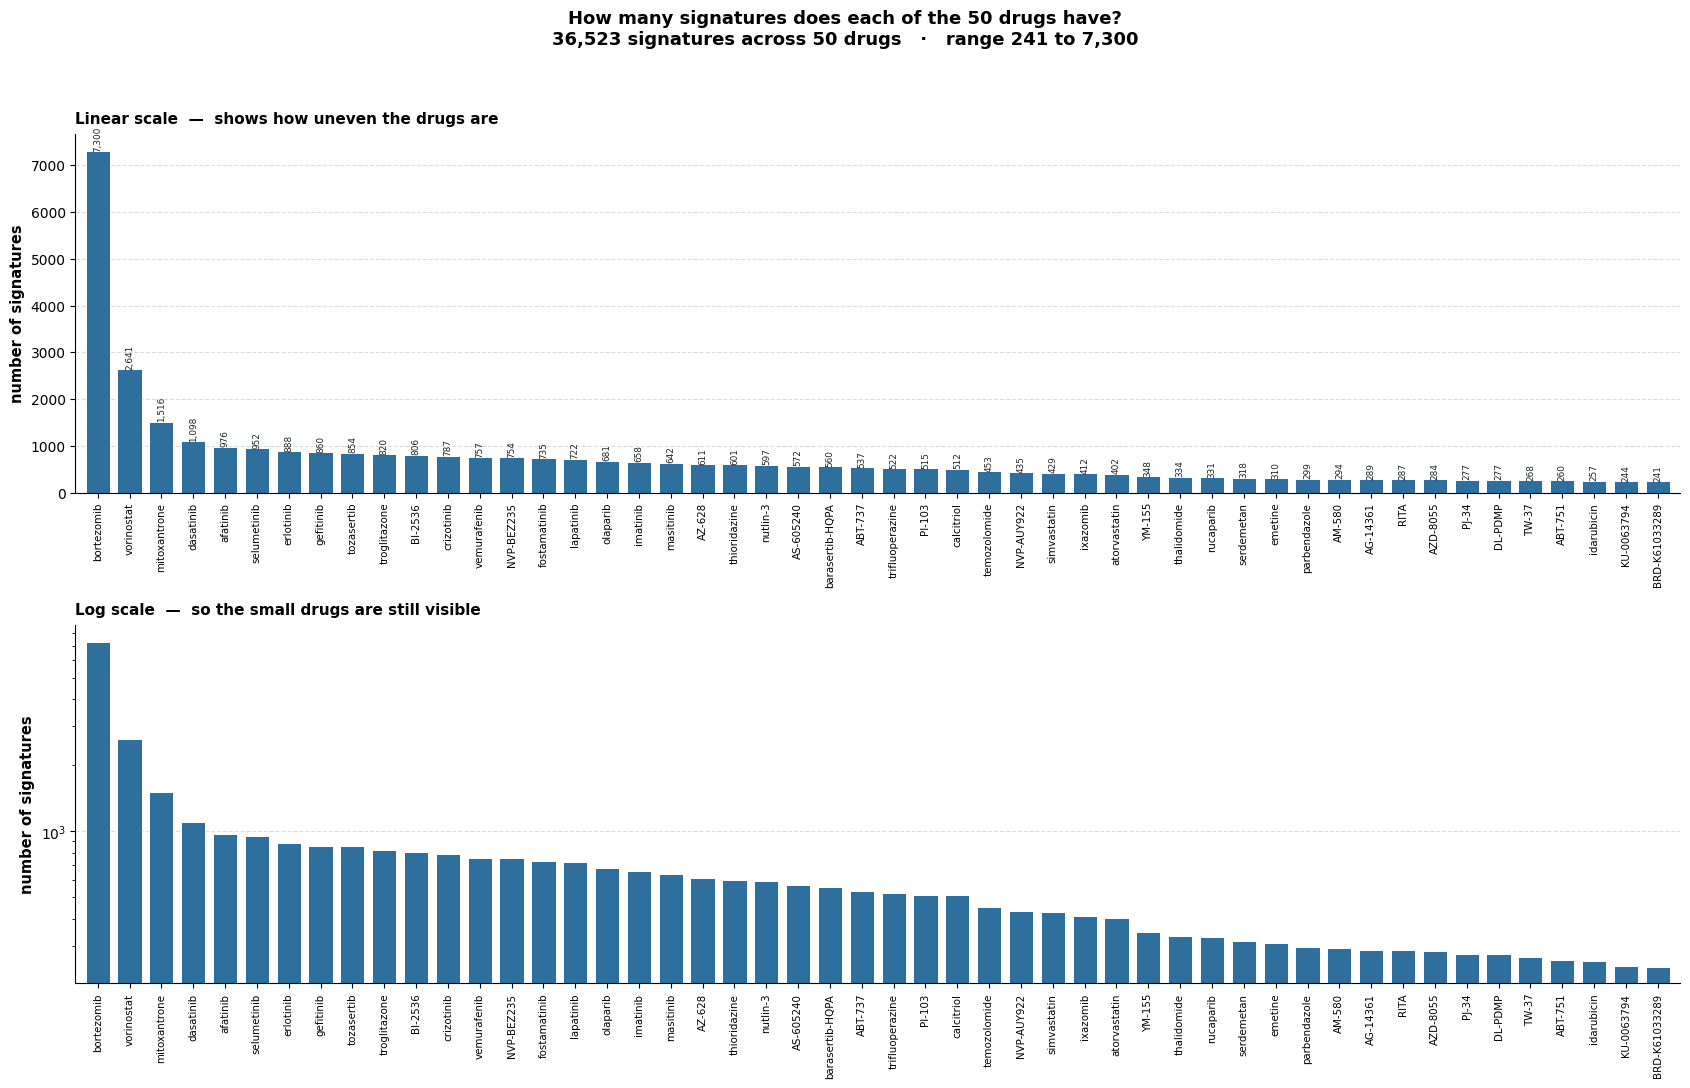


saved: figures/signatures_per_drug.png
saved: results/signatures_50drugs.csv  +  signature_counts_per_drug.csv


In [5]:
# ============================================================
#  STEP 1  —  har drug me kitne signatures
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, json, pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/Project59'
REF  = f'{BASE}/data/reference'

top50_names = json.load(open(f'{REF}/top50_names.json'))
sig_known   = pd.read_csv(f'{BASE}/results/sig_known/sig_known.csv', low_memory=False)

# gctx filter sirf agar file already hai (33 GB download ki zaroorat nahi)
gctx_file = '/content/cmap/level5_beta_trt_cp_n720216x12328.gctx'
if os.path.exists(gctx_file):
    from cmapPy.pandasGEXpress.parse import parse
    gctx_sigs = set(parse(gctx_file, col_meta_only=True).index)
    print(f"gctx filter ON  ({len(gctx_sigs):,} signatures)")
else:
    gctx_sigs = None
    print("gctx filter OFF  (file local nahi hai)")

# ---------- signatures nikalo ----------
S = sig_known[sig_known['cmap_name'].isin(top50_names)].copy()
if gctx_sigs is not None:
    S = S[S['sig_id'].isin(gctx_sigs)]

C = (S.groupby('cmap_name')
       .agg(signatures=('sig_id', 'nunique'),
            cell_lines=('cell_iname', 'nunique'),
            lineages=('cell_lineage', 'nunique'))
       .sort_values('signatures', ascending=False))

print("\n" + "="*66)
print(f"50 DRUGS  —  TOTAL SIGNATURES  =  {C.signatures.sum():,}")
print("="*66)
print(f"drugs      : {len(C)}")
print(f"biggest    : {C.index[0]}  ({C.signatures.iloc[0]:,})")
print(f"smallest   : {C.index[-1]}  ({C.signatures.iloc[-1]:,})")
print(f"median     : {int(C.signatures.median()):,}")
print(f"\n{'drug':<26}{'signatures':>12}{'cell_lines':>12}{'lineages':>10}")
print("-"*60)
for d, r in C.iterrows():
    print(f"{d:<26}{r.signatures:>12,}{r.cell_lines:>12}{r.lineages:>10}")
print("-"*60)
print(f"{'TOTAL':<26}{C.signatures.sum():>12,}")

# ---------- bar chart ----------
INK, GRID, BAR = '#1F2427', '#D8DEE1', '#2E6F9E'
x = np.arange(len(C))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(17, 11))

for ax, logy, title in [
        (ax1, False, 'Linear scale  —  shows how uneven the drugs are'),
        (ax2, True,  'Log scale  —  so the small drugs are still visible')]:
    ax.bar(x, C.signatures.values, .76, color=BAR,
           edgecolor='white', linewidth=.7)
    if logy:
        ax.set_yscale('log')
    else:
        for i, v in enumerate(C.signatures.values):
            ax.text(i, v, f'{v:,}', ha='center', va='bottom',
                    fontsize=6.4, color=INK, rotation=90)
    ax.set_ylabel('number of signatures', fontsize=10.5, fontweight='bold')
    ax.set_title(title, fontsize=11, fontweight='bold', loc='left', pad=8)
    ax.set_xticks(x)
    ax.set_xticklabels(C.index, rotation=90, fontsize=7.4)
    ax.set_xlim(-.7, len(C) - .3)
    ax.grid(axis='y', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle(
    f'How many signatures does each of the 50 drugs have?\n'
    f'{C.signatures.sum():,} signatures across {len(C)} drugs   ·   '
    f'range {C.signatures.min():,} to {C.signatures.max():,}',
    fontsize=13, fontweight='bold', y=.985)

plt.tight_layout(rect=[0, 0, 1, .955])
plt.savefig(f'{BASE}/figures/signatures_per_drug.png', dpi=170, bbox_inches='tight')
plt.show()

S.to_csv(f'{BASE}/results/signatures_50drugs.csv', index=False)
C.to_csv(f'{BASE}/results/signature_counts_per_drug.csv')
print(f"\nsaved: figures/signatures_per_drug.png")
print(f"saved: results/signatures_50drugs.csv  +  signature_counts_per_drug.csv")

total signatures : 36,523

#   drug                        signatures    share  cumulative
---------------------------------------------------------------
1   bortezomib                       7,300    20.0%       20.0%
2   vorinostat                       2,641     7.2%       27.2%
3   mitoxantrone                     1,516     4.2%       31.4%
4   dasatinib                        1,098     3.0%       34.4%
5   afatinib                           976     2.7%       37.0%
6   selumetinib                        952     2.6%       39.7%
7   erlotinib                          888     2.4%       42.1%
8   gefitinib                          860     2.4%       44.4%
9   tozasertib                         854     2.3%       46.8%
10  troglitazone                       820     2.2%       49.0%
11  BI-2536                            806     2.2%       51.2%
12  crizotinib                         787     2.2%       53.4%
13  vemurafenib                        757     2.1%       55.5%
14  NVP-BEZ23

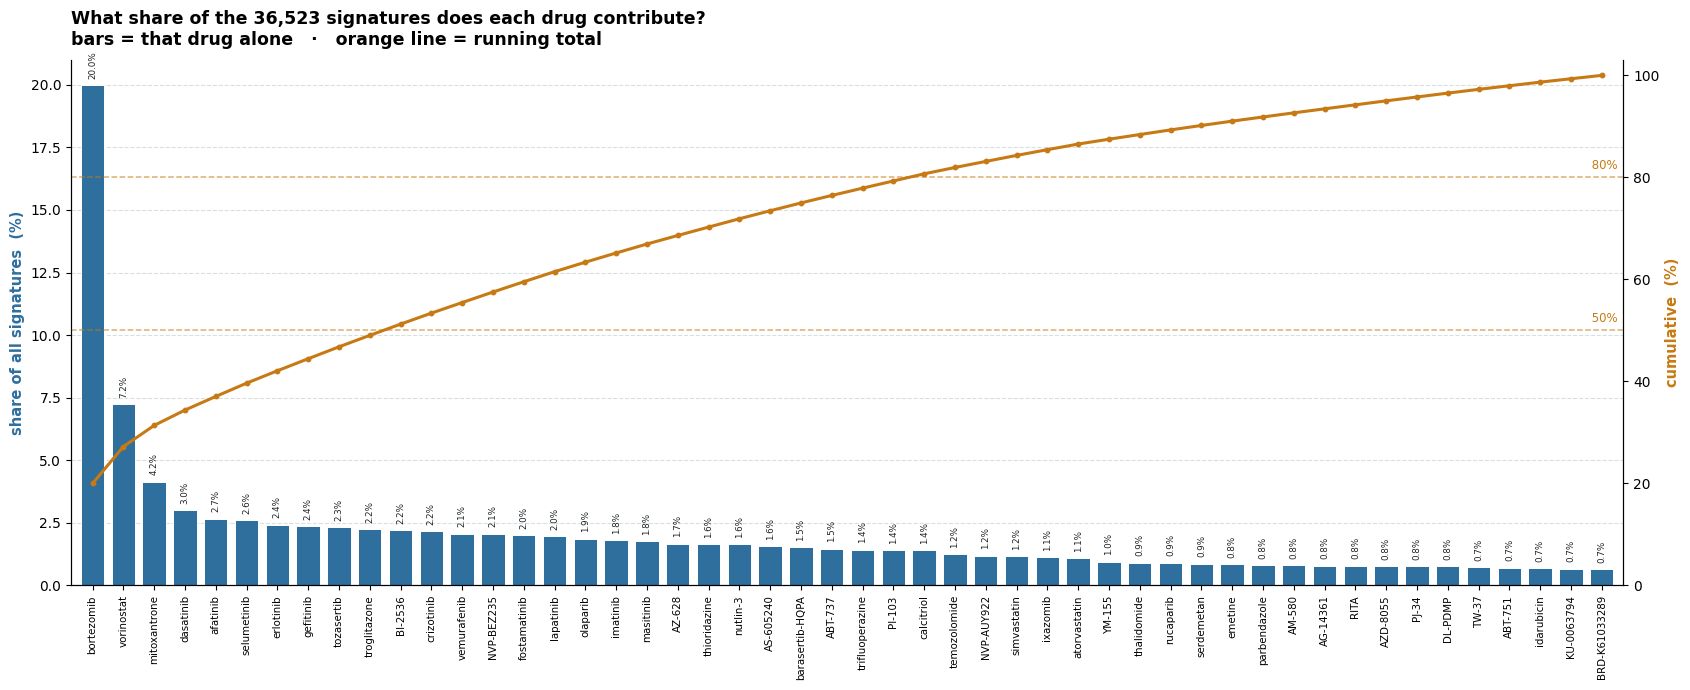


saved: figures/signature_share_pareto.png


In [6]:
# ============================================================
#  har drug ka hissa  —  36,523 me se kitne %
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

C = pd.read_csv(f'{BASE}/results/signature_counts_per_drug.csv', index_col=0)
C = C.sort_values('signatures', ascending=False)

tot = C['signatures'].sum()
C['pct']     = 100 * C['signatures'] / tot
C['cum_pct'] = C['pct'].cumsum()

print(f"total signatures : {tot:,}\n")
print(f"{'#':<4}{'drug':<26}{'signatures':>12}{'share':>9}{'cumulative':>12}")
print("-"*63)
for i, (d, r) in enumerate(C.iterrows(), 1):
    print(f"{i:<4}{d:<26}{r.signatures:>12,.0f}{r.pct:>8.1f}%{r.cum_pct:>11.1f}%")

for n in [1, 3, 5, 10, 25]:
    print(f"\ntop {n:>2} drugs  ->  {C['pct'].head(n).sum():.1f}% of all signatures")

# ---------- Pareto chart ----------
INK, GRID, BAR, LINE = '#1F2427', '#D8DEE1', '#2E6F9E', '#C77A14'
x = np.arange(len(C))

fig, ax = plt.subplots(figsize=(17, 7))
ax.bar(x, C['pct'].values, .76, color=BAR, edgecolor='white', linewidth=.7)
for i, v in enumerate(C['pct'].values):
    ax.text(i, v + .25, f'{v:.1f}%', ha='center', va='bottom',
            fontsize=6.3, color=INK, rotation=90)
ax.set_ylabel('share of all signatures  (%)', fontsize=10.5,
              fontweight='bold', color=BAR)
ax.set_xticks(x); ax.set_xticklabels(C.index, rotation=90, fontsize=7.4)
ax.set_xlim(-.7, len(C) - .3)
ax.grid(axis='y', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top']].set_visible(False)

ax2 = ax.twinx()
ax2.plot(x, C['cum_pct'].values, color=LINE, lw=2.2, marker='o', ms=3.2)
ax2.axhline(50, color=LINE, ls='--', lw=1.1, alpha=.6)
ax2.axhline(80, color=LINE, ls='--', lw=1.1, alpha=.6)
ax2.text(len(C)-.5, 51, ' 50%', fontsize=8.5, color=LINE, va='bottom', ha='right')
ax2.text(len(C)-.5, 81, ' 80%', fontsize=8.5, color=LINE, va='bottom', ha='right')
ax2.set_ylabel('cumulative  (%)', fontsize=10.5, fontweight='bold', color=LINE)
ax2.set_ylim(0, 103); ax2.spines[['top']].set_visible(False)

ax.set_title(
    f'What share of the {tot:,} signatures does each drug contribute?\n'
    f'bars = that drug alone   ·   orange line = running total',
    fontsize=12.5, fontweight='bold', loc='left', pad=11)

plt.tight_layout()
plt.savefig(f'{BASE}/figures/signature_share_pareto.png', dpi=170, bbox_inches='tight')
plt.show()

C.to_csv(f'{BASE}/results/signature_share_per_drug.csv')
print("\nsaved: figures/signature_share_pareto.png")

In [32]:
sh = pd.read_csv(f'{BASE}/results/signature_share_per_drug.csv')
print('columns :', sh.columns.tolist())
print()
print(sh.head(3))

columns : ['cmap_name', 'signatures', 'cell_lines', 'lineages', 'pct', 'cum_pct']

      cmap_name  signatures  cell_lines  lineages        pct    cum_pct
0    bortezomib        7300         108        19  19.987405  19.987405
1    vorinostat        2641         116        20   7.231060  27.218465
2  mitoxantrone        1516          92        20   4.150809  31.369274


In [33]:
sh = pd.read_csv(f'{BASE}/results/signature_share_per_drug.csv')

# share column auto-detect
cand = [c for c in sh.columns
        if any(k in c.lower() for k in ['share','pct','percent','prop'])]
if cand:
    col = cand[0]
    print(f'using share column: {col}')
    sh = sh.sort_values(col, ascending=False).reset_index(drop=True)
    sh['cum'] = sh[col].cumsum()
else:
    # koi share column nahi -> count se khud bana lo
    ccand = [c for c in sh.columns
             if any(k in c.lower() for k in ['n_sig','count','signatures','total'])]
    col = ccand[0]
    print(f'no share column; computing from counts: {col}')
    sh = sh.sort_values(col, ascending=False).reset_index(drop=True)
    sh['cum'] = 100 * sh[col].cumsum() / sh[col].sum()

dcol = next(c for c in sh.columns
            if any(k in c.lower() for k in ['drug','cmap_name','name']))

for t in [50, 80, 90, 95]:
    i = (sh['cum'] >= t).idxmax()
    print(f'{t}% reached at drug #{i+1:>2}  ->  {sh.loc[i, dcol]}  (cum {sh.loc[i,"cum"]:.1f}%)')

using share column: pct
50% reached at drug #11  ->  BI-2536  (cum 51.2%)
80% reached at drug #28  ->  calcitriol  (cum 80.7%)
90% reached at drug #37  ->  serdemetan  (cum 90.2%)
95% reached at drug #43  ->  AZD-8055  (cum 95.0%)


In [35]:
sh = pd.read_csv(f'{BASE}/results/signature_share_per_drug.csv')
sh = sh.sort_values('pct', ascending=False).reset_index(drop=True)
sh['cum'] = sh['pct'].cumsum()
print('50% reached at drug #', (sh['cum'] >= 50).idxmax() + 1)
print('80% reached at drug #', (sh['cum'] >= 80).idxmax() + 1)
print('90% reached at drug #', (sh['cum'] >= 90).idxmax() + 1)

50% reached at drug # 11
80% reached at drug # 28
90% reached at drug # 37


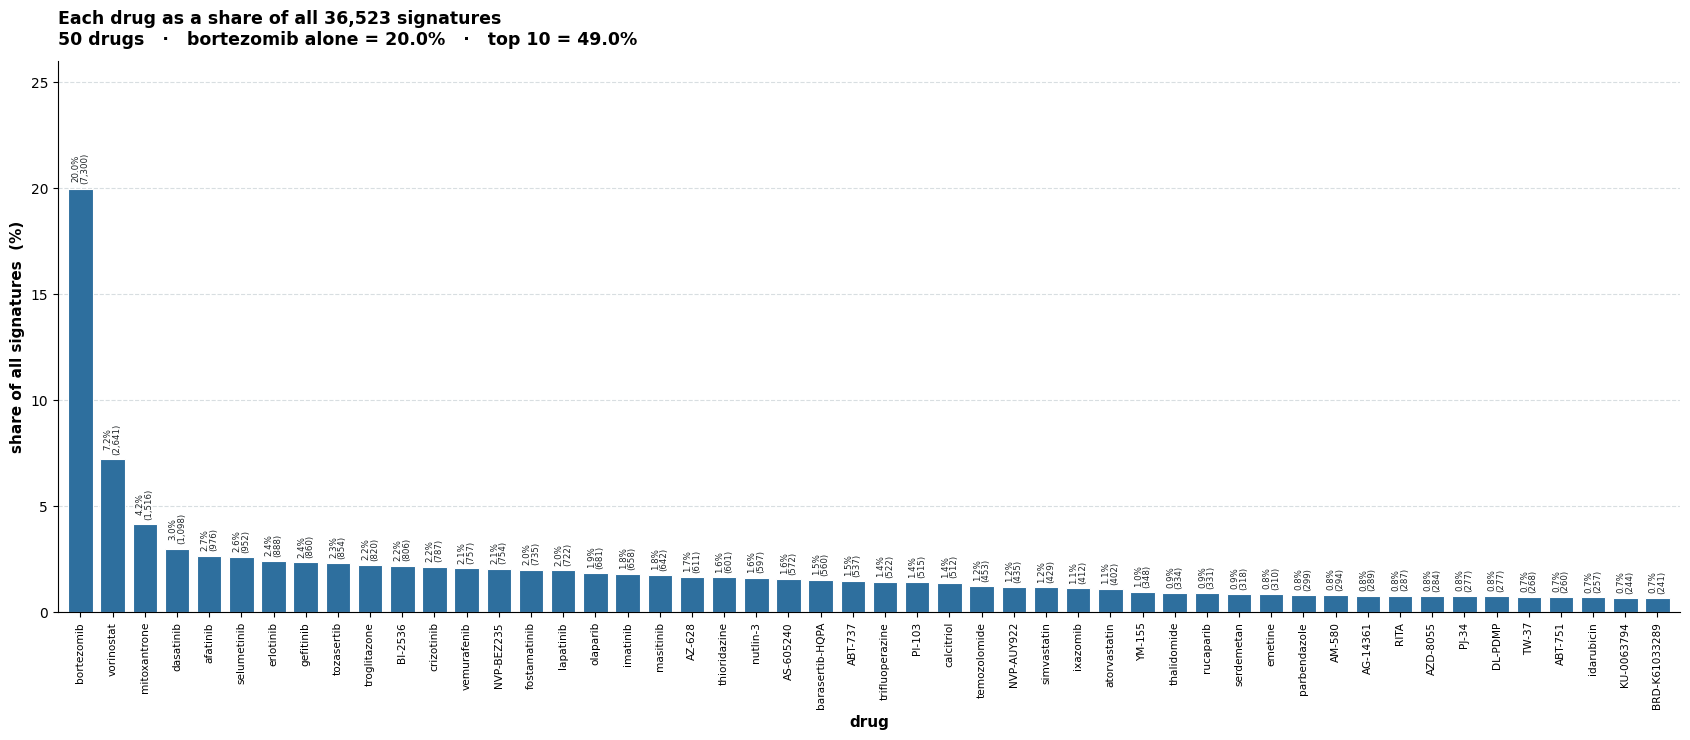

#   drug                        signatures    share
---------------------------------------------------
1   bortezomib                       7,300    20.0%
2   vorinostat                       2,641     7.2%
3   mitoxantrone                     1,516     4.2%
4   dasatinib                        1,098     3.0%
5   afatinib                           976     2.7%
6   selumetinib                        952     2.6%
7   erlotinib                          888     2.4%
8   gefitinib                          860     2.4%
9   tozasertib                         854     2.3%
10  troglitazone                       820     2.2%
11  BI-2536                            806     2.2%
12  crizotinib                         787     2.2%
13  vemurafenib                        757     2.1%
14  NVP-BEZ235                         754     2.1%
15  fostamatinib                       735     2.0%
16  lapatinib                          722     2.0%
17  olaparib                           681     1.9%
18  imatinib

In [7]:
# ============================================================
#  PERCENTAGE BAR CHART  —  har drug ka hissa
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt

C = pd.read_csv(f'{BASE}/results/signature_counts_per_drug.csv', index_col=0)
C = C.sort_values('signatures', ascending=False)

tot = C['signatures'].sum()
C['pct'] = 100 * C['signatures'] / tot

INK, GRID, BAR = '#1F2427', '#D8DEE1', '#2E6F9E'
x = np.arange(len(C))

fig, ax = plt.subplots(figsize=(17, 7.5))
ax.bar(x, C['pct'].values, .76, color=BAR, edgecolor='white', linewidth=.8)

for i, (v, n) in enumerate(zip(C['pct'].values, C['signatures'].values)):
    ax.text(i, v + .2, f'{v:.1f}%\n({n:,.0f})', ha='center', va='bottom',
            fontsize=6.2, color=INK, rotation=90, linespacing=.95)

ax.set_ylabel('share of all signatures  (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('drug', fontsize=11, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(C.index, rotation=90, fontsize=7.6)
ax.set_xlim(-.7, len(C) - .3)
ax.set_ylim(0, C['pct'].max() * 1.30)
ax.grid(axis='y', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

ax.set_title(
    f'Each drug as a share of all {tot:,} signatures\n'
    f'{len(C)} drugs   ·   bortezomib alone = {C["pct"].iloc[0]:.1f}%   ·   '
    f'top 10 = {C["pct"].head(10).sum():.1f}%',
    fontsize=12.5, fontweight='bold', loc='left', pad=12)

plt.tight_layout()
plt.savefig(f'{BASE}/figures/signature_share_bar.png', dpi=170, bbox_inches='tight')
plt.show()

print(f"{'#':<4}{'drug':<26}{'signatures':>12}{'share':>9}")
print("-"*51)
for i, (d, r) in enumerate(C.iterrows(), 1):
    print(f"{i:<4}{d:<26}{r.signatures:>12,.0f}{r.pct:>8.1f}%")
print("-"*51)
print(f"{'':<4}{'TOTAL':<26}{tot:>12,}{100.0:>8.1f}%")

In [8]:
# ============================================================
#  STEP 2  —  signature-level A / B / C / D
# ============================================================
import pandas as pd, numpy as np

R = pd.read_csv(f'{BASE}/results/per_signature_v4_ABCD.csv')
S = pd.read_csv(f'{BASE}/results/signatures_50drugs.csv', low_memory=False)

print("R (pair-level) :", f"{len(R):,} rows")
print("columns        :", list(R.columns))
print("S (signatures) :", f"{S['sig_id'].nunique():,} unique sig_id\n")

# ---- column names auto-detect ----
CAT = 'cat'     if 'cat'     in R.columns else 'category'
LIN = 'lineage' if 'lineage' in R.columns else 'cell_lineage'
TIS = 'tissue'
print(f"using -> drug='drug'  lineage='{LIN}'  tissue='{TIS}'  category='{CAT}'")
print(f"\npair-level category counts:")
print(R[CAT].value_counts().reindex(['A','B','C','D']).fillna(0).astype(int).to_string())
print(f"tissues per pair: {R.groupby(['drug', LIN]).size().median():.0f} (median)\n")

# ============================================================
#  VERSION 1  —  har signature ko EK category  (best of 44)
#               A > B > C > D   ('A' < 'B' alphabetically, to min() = best)
# ============================================================
best = (R.groupby(['drug', LIN])[CAT].min()
          .reset_index().rename(columns={CAT: 'sig_cat'}))

S1 = S.merge(best, left_on=['cmap_name', 'cell_lineage'],
                   right_on=['drug', LIN], how='left')
S1['sig_cat'] = S1['sig_cat'].fillna('D')      # pair hi nahi bana -> D

v1 = S1['sig_cat'].value_counts().reindex(['A','B','C','D']).fillna(0).astype(int)

print("="*66)
print("VERSION 1  —  one category per signature (best across 44 tissues)")
print("="*66)
tot1 = v1.sum()
for c in ['A','B','C','D']:
    print(f"   {c}  {v1[c]:>8,}   {100*v1[c]/tot1:>5.1f}%")
print(f"   {'─'*24}")
print(f"   total {tot1:>8,}")

# ============================================================
#  VERSION 2  —  signature x tissue rows  (har signature 44 baar)
# ============================================================
nsig = (S.groupby(['cmap_name','cell_lineage'])['sig_id'].nunique()
          .reset_index().rename(columns={'sig_id':'n_sig'}))

R2 = R.merge(nsig, left_on=['drug', LIN],
                   right_on=['cmap_name','cell_lineage'], how='left')
R2['n_sig'] = R2['n_sig'].fillna(0)
v2 = R2.groupby(CAT)['n_sig'].sum().reindex(['A','B','C','D']).fillna(0).astype(int)

print("\n" + "="*66)
print("VERSION 2  —  signature x tissue rows")
print("="*66)
tot2 = v2.sum()
for c in ['A','B','C','D']:
    print(f"   {c}  {v2[c]:>10,}   {100*v2[c]/tot2:>5.1f}%")
print(f"   {'─'*28}")
print(f"   total {tot2:>10,}")
print(f"\n   check: {S['sig_id'].nunique():,} signatures x 44 tissues "
      f"= {S['sig_id'].nunique()*44:,}")

# ============================================================
#  per-drug tables  (dono versions)
# ============================================================
T1 = (S1.pivot_table(index='cmap_name', columns='sig_cat',
                     values='sig_id', aggfunc='nunique')
        .reindex(columns=['A','B','C','D']).fillna(0).astype(int))
T1['total'] = T1.sum(axis=1)
T1 = T1.sort_values('total', ascending=False)

print("\n" + "="*72)
print("PER DRUG  —  version 1  (one category per signature)")
print("="*72)
print(f"{'drug':<26}{'A':>8}{'B':>8}{'C':>8}{'D':>8}{'total':>10}")
print("-"*68)
for d, r in T1.iterrows():
    print(f"{d:<26}{r.A:>8,}{r.B:>8,}{r.C:>8,}{r.D:>8,}{r.total:>10,}")
print("-"*68)
print(f"{'TOTAL':<26}{T1.A.sum():>8,}{T1.B.sum():>8,}{T1.C.sum():>8,}"
      f"{T1.D.sum():>8,}{T1.total.sum():>10,}")

S1.to_csv(f'{BASE}/results/signature_level_ABCD.csv', index=False)
T1.to_csv(f'{BASE}/results/signature_ABCD_per_drug.csv')
print(f"\nsaved: signature_level_ABCD.csv  +  signature_ABCD_per_drug.csv")

R (pair-level) : 39,996 rows
columns        : ['drug', 'lineage', 'tissue', 'is_home_tissue', 'n_M', 'n_F', 'n_signatures', 'NES', 'FDR', 'category', 'skip_reason']
S (signatures) : 36,523 unique sig_id

using -> drug='drug'  lineage='lineage'  tissue='tissue'  category='category'

pair-level category counts:
category
A       29
B      717
C     5376
D    33874
tissues per pair: 44 (median)

VERSION 1  —  one category per signature (best across 44 tissues)
   A     2,656     7.3%
   B     5,163    14.1%
   C     4,684    12.8%
   D    24,020    65.8%
   ────────────────────────
   total   36,523

VERSION 2  —  signature x tissue rows
   A       2,828     0.2%
   B      93,247     5.8%
   C     396,645    24.7%
   D   1,114,292    69.3%
   ────────────────────────────
   total  1,607,012

   check: 36,523 signatures x 44 tissues = 1,607,012

PER DRUG  —  version 1  (one category per signature)
drug                             A       B       C       D     total
-------------------------

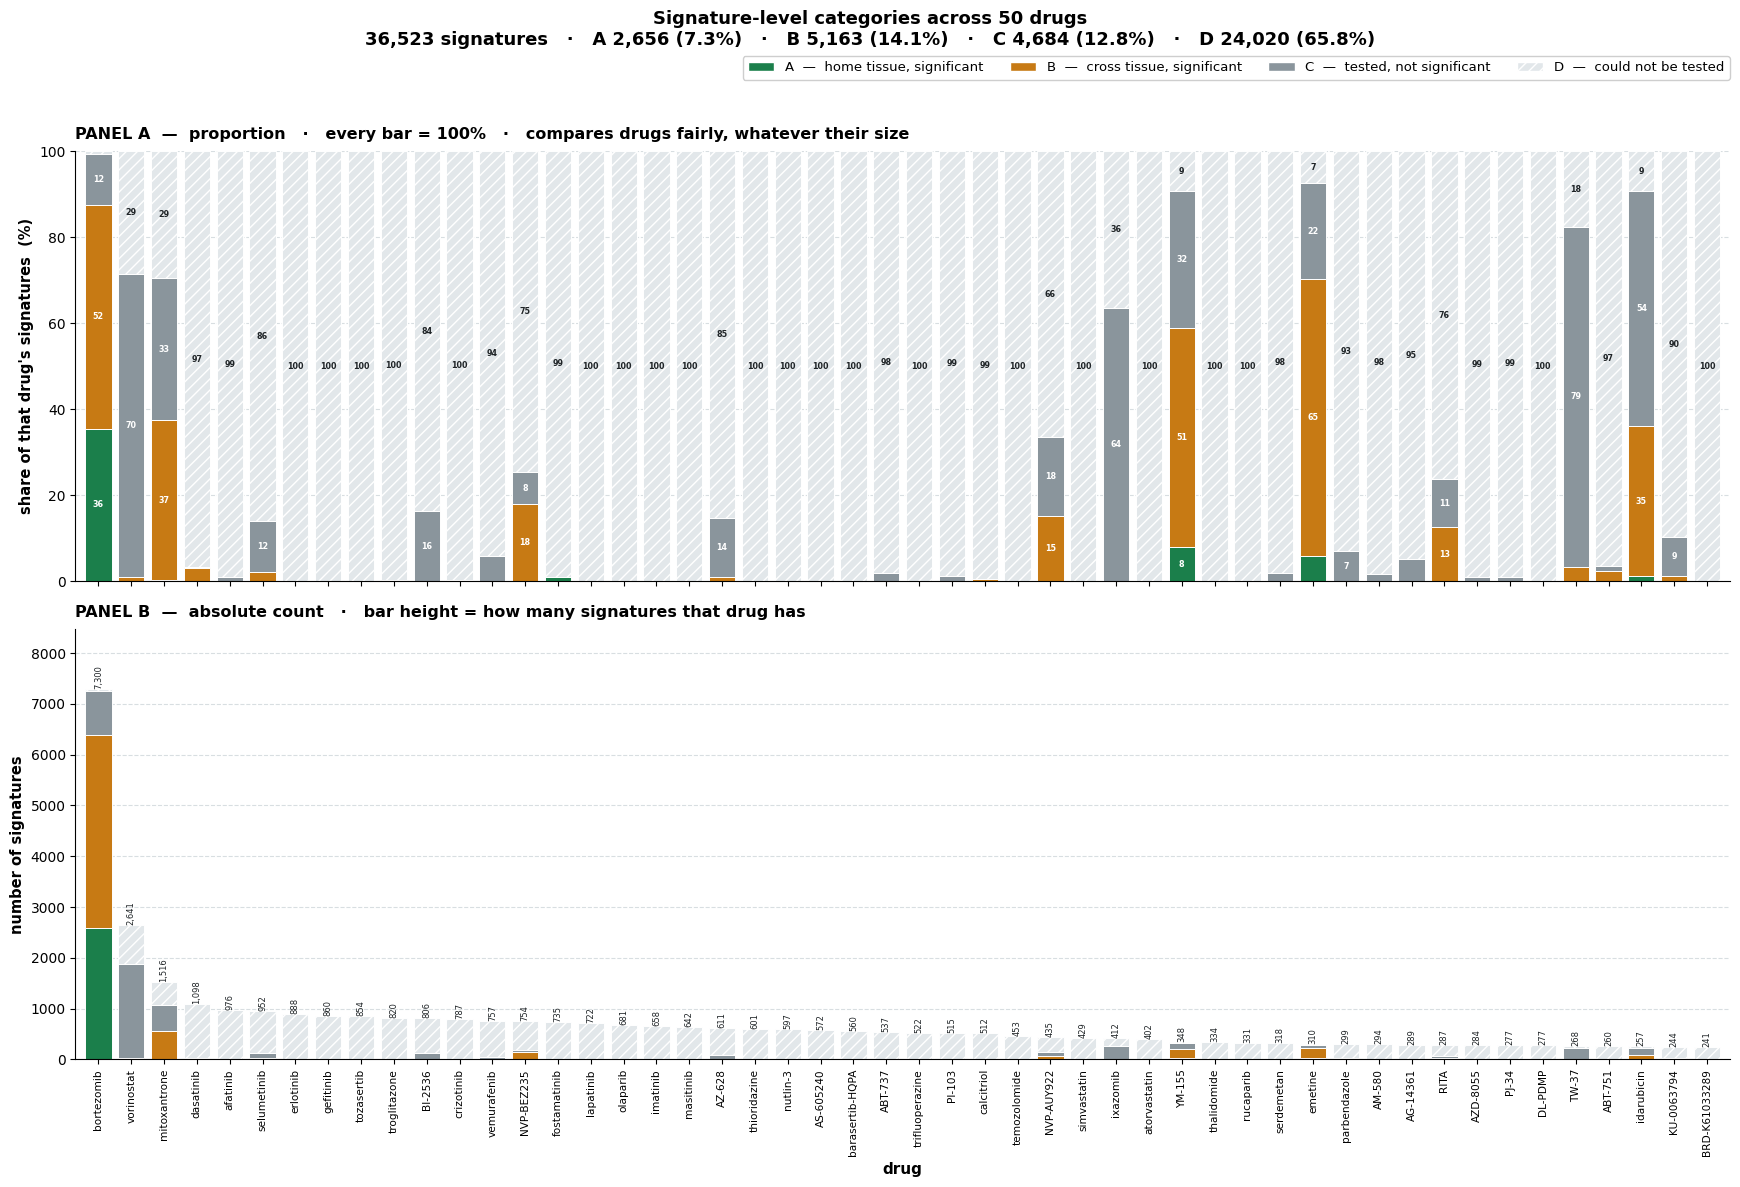

saved: /content/drive/MyDrive/Project59/figures/signature_ABCD_2panel.png


In [9]:
# ============================================================
#  STEP 3  —  har drug ka bar, A/B/C/D me stacked
#  Panel A = percentage (har bar 100%)
#  Panel B = actual numbers (bar height = signature count)
# ============================================================
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

T = pd.read_csv(f'{BASE}/results/signature_ABCD_per_drug.csv', index_col=0)
T = T.sort_values('total', ascending=False)
P = T[['A','B','C','D']].div(T['total'], axis=0) * 100

COL  = {'A':'#1B7F4B',   # green  — home tissue, significant
        'B':'#C77A14',   # orange — cross tissue, significant
        'C':'#8A959C',   # grey   — tested, not significant
        'D':'#E2E7EA'}   # pale   — could not be tested
INK, GRID = '#1F2427', '#D8DEE1'
x = np.arange(len(T))

fig, (axA, axB) = plt.subplots(2, 1, figsize=(17.5, 12), sharex=True)

# ---------- PANEL A : percentage ----------
bottom = np.zeros(len(T))
for c in ['A','B','C','D']:
    v = P[c].values
    axA.bar(x, v, .80, bottom=bottom, color=COL[c],
            edgecolor='white', linewidth=.7,
            hatch='///' if c == 'D' else None)
    for i, (val, b) in enumerate(zip(v, bottom)):
        if val >= 7:                       # sirf bade tukdon pe label
            axA.text(i, b + val/2, f'{val:.0f}', ha='center', va='center',
                     fontsize=5.8, color='white' if c != 'D' else INK,
                     fontweight='bold')
    bottom += v
axA.set_ylim(0, 100)
axA.set_ylabel('share of that drug\'s signatures  (%)',
               fontsize=10.5, fontweight='bold')
axA.set_title('PANEL A  —  proportion   ·   every bar = 100%   ·   '
              'compares drugs fairly, whatever their size',
              fontsize=11.5, fontweight='bold', loc='left', pad=9)

# ---------- PANEL B : absolute ----------
bottom = np.zeros(len(T))
for c in ['A','B','C','D']:
    v = T[c].values
    axB.bar(x, v, .80, bottom=bottom, color=COL[c],
            edgecolor='white', linewidth=.7,
            hatch='///' if c == 'D' else None)
    bottom += v
for i, t in enumerate(T['total'].values):
    axB.text(i, t, f'{t:,}', ha='center', va='bottom',
             fontsize=6.0, color=INK, rotation=90)
axB.set_ylabel('number of signatures', fontsize=10.5, fontweight='bold')
axB.set_title('PANEL B  —  absolute count   ·   bar height = how many '
              'signatures that drug has',
              fontsize=11.5, fontweight='bold', loc='left', pad=9)
axB.set_ylim(0, T['total'].max() * 1.16)

for ax in (axA, axB):
    ax.grid(axis='y', color=GRID, lw=.8, ls='--'); ax.set_axisbelow(True)
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-.7, len(T) - .3)

axB.set_xticks(x)
axB.set_xticklabels(T.index, rotation=90, fontsize=7.6)
axB.set_xlabel('drug', fontsize=11, fontweight='bold')

fig.suptitle(
    f'Signature-level categories across {len(T)} drugs\n'
    f'{T["total"].sum():,} signatures   ·   '
    f'A {T.A.sum():,} ({100*T.A.sum()/T["total"].sum():.1f}%)   ·   '
    f'B {T.B.sum():,} ({100*T.B.sum()/T["total"].sum():.1f}%)   ·   '
    f'C {T.C.sum():,} ({100*T.C.sum()/T["total"].sum():.1f}%)   ·   '
    f'D {T.D.sum():,} ({100*T.D.sum()/T["total"].sum():.1f}%)',
    fontsize=13, fontweight='bold', y=.985)

fig.legend(handles=[
    Patch(fc=COL['A'], ec='white', label='A  —  home tissue, significant'),
    Patch(fc=COL['B'], ec='white', label='B  —  cross tissue, significant'),
    Patch(fc=COL['C'], ec='white', label='C  —  tested, not significant'),
    Patch(fc=COL['D'], ec='white', hatch='///', label='D  —  could not be tested')],
    loc='upper right', bbox_to_anchor=(.995, .952),
    fontsize=9.5, framealpha=.96, ncol=4)

plt.tight_layout(rect=[0, 0, 1, .945])
plt.savefig(f'{BASE}/figures/signature_ABCD_2panel.png', dpi=175, bbox_inches='tight')
plt.show()
print(f"saved: {BASE}/figures/signature_ABCD_2panel.png")

In [37]:
S = pd.read_csv(f'{BASE}/results/signatures_50drugs.csv')

tab = (S.groupby(['cmap_name', 'cell_lineage'])
         .size().reset_index(name='n_signatures')
         .sort_values(['cmap_name', 'n_signatures'], ascending=[True, False]))

tab.to_csv(f'{BASE}/results/signatures_per_drug_per_lineage.csv', index=False)

print('rows (drug x lineage pairs) :', len(tab))
print('unique drugs                :', tab['cmap_name'].nunique())
print('unique lineages             :', tab['cell_lineage'].nunique())
print('total signatures            :', tab['n_signatures'].sum())
print()
print('--- bortezomib ---')
print(tab[tab['cmap_name'] == 'bortezomib'].to_string(index=False))

rows (drug x lineage pairs) : 909
unique drugs                : 50
unique lineages             : 20
total signatures            : 36523

--- bortezomib ---
 cmap_name                       cell_lineage  n_signatures
bortezomib                             breast          1875
bortezomib                               lung           868
bortezomib                             cervix           801
bortezomib                           prostate           791
bortezomib                    large_intestine           741
bortezomib                               skin           633
bortezomib                           pancreas           628
bortezomib                             kidney           455
bortezomib haematopoietic_and_lymphoid_tissue           255
bortezomib                              liver            88
bortezomib                              ovary            45
bortezomib                               bone            33
bortezomib                        endometrium            27
bort

In [15]:
T = pd.read_csv(f'{BASE}/results/signature_ABCD_per_drug.csv', index_col=0)
A = T[T['A'] > 0][['A','B','C','D','total']].sort_values('A', ascending=False)
A['A_share_of_all_A'] = (100 * A['A'] / T['A'].sum()).round(1)
print(f"total Category A signatures : {T['A'].sum():,}\n")
print(A.to_string())

total Category A signatures : 2,656

                 A     B    C    D  total  A_share_of_all_A
cmap_name                                                  
bortezomib    2593  3791  874   42   7300              97.6
YM-155          28   177  111   32    348               1.1
emetine         18   200   69   23    310               0.7
fostamatinib     8     0    0  727    735               0.3
mitoxantrone     6   561  502  447   1516               0.2
idarubicin       3    90  140   24    257               0.1


In [36]:
S = pd.read_csv(f'{BASE}/results/signatures_50drugs.csv')

tab = (S.groupby(['cmap_name', 'cell_lineage'])
         .size().reset_index(name='n_signatures')
         .sort_values(['cmap_name', 'n_signatures'], ascending=[True, False]))

tab.to_csv(f'{BASE}/results/signatures_per_drug_per_lineage.csv', index=False)

print('rows (drug x lineage pairs) :', len(tab))
print('unique drugs                :', tab['cmap_name'].nunique())
print('unique lineages             :', tab['cell_lineage'].nunique())
print('total signatures            :', tab['n_signatures'].sum())
print()
print('--- bortezomib ---')
print(tab[tab['cmap_name'] == 'bortezomib'].to_string(index=False))

rows (drug x lineage pairs) : 909
unique drugs                : 50
unique lineages             : 20
total signatures            : 36523

--- bortezomib ---
 cmap_name                       cell_lineage  n_signatures
bortezomib                             breast          1875
bortezomib                               lung           868
bortezomib                             cervix           801
bortezomib                           prostate           791
bortezomib                    large_intestine           741
bortezomib                               skin           633
bortezomib                           pancreas           628
bortezomib                             kidney           455
bortezomib haematopoietic_and_lymphoid_tissue           255
bortezomib                              liver            88
bortezomib                              ovary            45
bortezomib                               bone            33
bortezomib                        endometrium            27
bort

In [16]:
# ---- fair denominator: kitne home tissues the ----
S1 = pd.read_csv(f'{BASE}/results/signature_level_ABCD.csv', low_memory=False)
S1['n_home'] = S1['cell_lineage'].map(lambda l: len(cmap_to_gtex.get(l, [])))

elig = S1[S1['n_home'] > 0]           # A possible hi tabhi hai jab home tissue ho
r = (elig.groupby('cmap_name')
       .agg(A=('sig_cat', lambda s: (s=='A').sum()),
            eligible=('sig_id','nunique'),
            home_opps=('n_home','sum'),
            lineages=('cell_lineage','nunique'))
       .query('eligible > 0'))
r['A_per_eligible_sig'] = (100*r['A']/r['eligible']).round(2)
r['A_per_opportunity']  = (100*r['A']/r['home_opps']).round(3)

print(f"signatures with at least one home tissue : {len(elig):,} of {len(S1):,}\n")
print(r.sort_values('A_per_opportunity', ascending=False).head(15).to_string())

# bortezomib ke andar lineage-wise
b = S1[S1['cmap_name']=='bortezomib']
print("\nbortezomib, lineage wise:")
print(b.groupby(['cell_lineage','n_home'])['sig_cat']
        .value_counts().unstack(fill_value=0)
        .sort_values('A', ascending=False).to_string())

signatures with at least one home tissue : 35,128 of 36,523

                 A  eligible  home_opps  lineages  A_per_eligible_sig  A_per_opportunity
cmap_name                                                                               
bortezomib    2593      7258      10524        17               35.73             24.639
YM-155          28       334        500        17                8.38              5.600
emetine         18       291        478        16                6.19              3.766
idarubicin       3       245        379        16                1.22              0.792
fostamatinib     8       705       1205        17                1.13              0.664
mitoxantrone     6      1412       2361        18                0.42              0.254
ABT-751          0       244        422        16                0.00              0.000
AG-14361         0       273        455        16                0.00              0.000
AS-605240        0       547        825        17

In [18]:
import os, glob, pandas as pd, numpy as np

print("results folder:")
for f in sorted(os.listdir(f'{BASE}/results')):
    p = f'{BASE}/results/{f}'
    if os.path.isfile(p):
        print(f"   {f:<55} {os.path.getsize(p)/1e6:>8.2f} MB")
    else:
        print(f"   {f}/")

results folder:
   50_drugs/
   Project59_ABCD_MASTER.xlsx                                  0.20 MB
   all_genes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv     0.06 MB
   allgenes_bortezomib_haematopoiet_Cells_EBV.transf_filtered.csv     0.06 MB
   bortezomib_comparisons.xlsx                                 0.01 MB
   bortezomib_lineage_x_tissue.xlsx                            0.04 MB
   category_A_hits.csv                                         0.00 MB
   per_drug_summary.csv                                        0.00 MB
   per_signature_categories.csv                                2.74 MB
   per_signature_v3_no_filter.csv                              3.23 MB
   per_signature_v4_ABCD.csv                                   3.16 MB
   sexgenes_bortezomib_Brain_Hypothalam_BJAB_filtered.csv      0.02 MB
   sexgenes_bortezomib_Brain_Hypothalam_lineage_filtered.csv     0.01 MB
   sexgenes_bortezomib_Cells_EBV.transf_NALM6_filtered.csv     0.01 MB
   sexgenes_emetine_Adipose_Vis

In [20]:
import os, glob, pandas as pd

# ---- subfolders ----
for sub in ['50_drugs', 'tables', 'sig_known']:
    p = f'{BASE}/results/{sub}'
    if os.path.isdir(p):
        print(f"\n--- {sub}/ ---")
        for f in sorted(os.listdir(p)):
            print(f"   {f:<58} {os.path.getsize(f'{p}/{f}')/1e6:>7.2f} MB")

# ---- master Excel ke sheets ----
xl = f'{BASE}/results/Project59_ABCD_MASTER.xlsx'
if os.path.exists(xl):
    print(f"\n--- Project59_ABCD_MASTER.xlsx sheets ---")
    for sh in pd.ExcelFile(xl).sheet_names:
        d = pd.read_excel(xl, sheet_name=sh, nrows=3)
        print(f"   {sh:<30} cols: {list(d.columns)[:7]}")

# ---- gender_lean kahan hai, poora scan ----
print("\n--- 'gender_lean' wali files ---")
for f in glob.glob(f'{BASE}/results/**/*.csv', recursive=True):
    try:
        if 'gender_lean' in pd.read_csv(f, nrows=1).columns:
            n = len(pd.read_csv(f))
            print(f"   FOUND  {f.replace(BASE,'')}   ({n:,} rows)")
    except Exception:
        pass


--- 50_drugs/ ---
   per_drug_4category_counts.csv                                 0.00 MB
   per_drug_lineage.csv                                          0.05 MB
   significant_hits.csv                                          0.01 MB

--- tables/ ---
   4_category_breakdown.xlsx                                     0.01 MB
   4_category_breakdown_FIXED.xlsx                               0.01 MB
   50_drugs_44_tissues_FULL.csv                                  0.08 MB
   50_drugs_44_tissues_FULL.xlsx                                 0.05 MB
   50_drugs_complete_table.csv                                   0.01 MB
   50_drugs_complete_table.xlsx                                  0.01 MB
   FULL_50drugs_table.xlsx                                       2.31 MB
   all50_drug_counts.xlsx                                        0.01 MB
   cat_a_enrichment_scores.csv                                   0.00 MB
   cat_a_enrichment_scores.xlsx                                  0.01 MB
   category_sum

In [21]:
import pandas as pd
xl = f'{BASE}/results/Project59_ABCD_MASTER.xlsx'

bl = pd.read_excel(xl, sheet_name='by_lineage')
bl['A_per_home_test'] = (100 * bl['A'] / bl['home_tests'].replace(0, pd.NA)).round(2)
print(bl.sort_values('A', ascending=False).to_string(index=False))

print("\n--- why not tested ---")
print(pd.read_excel(xl, sheet_name='why_not_tested').to_string(index=False))

print("\n--- category A hits ---")
print(pd.read_excel(xl, sheet_name='category_A').to_string(index=False))

                           lineage  A  B   C    D  n_home_tissues  home_tests  A_rate_%  A_per_home_test
            central_nervous_system 19 18 394 1769              13       131.0      14.5            14.50
                            kidney  3 78 334 1785               2         9.0      33.3            33.33
haematopoietic_and_lymphoid_tissue  2 32 215 1951               3         9.0      22.2            22.22
                       soft_tissue  2 58 366 1774               3        32.0       6.2             6.25
                              skin  2 73 403 1722               2        24.0       8.3             8.33
                            breast  1 26 202 1971               1         3.0      33.3            33.33
                 autonomic_ganglia  0  6  81  353               1         2.0       0.0             0.00
                              bone  0  0   0 2200               0         NaN       NaN              NaN
                   large_intestine  0 16 274 1910      

In [22]:
A = pd.read_excel(f'{BASE}/results/Project59_ABCD_MASTER.xlsx', sheet_name='category_A')
A['min_sex'] = A[['n_M','n_F']].min(axis=1)

print(f"total Category A hits : {len(A)}")
print(f"   zero female lines  : {(A['n_F']==0).sum()}")
print(f"   zero male lines    : {(A['n_M']==0).sum()}")
print(f"   both sexes present : {(A['min_sex']>0).sum()}")
print(f"   both sexes AND >=50 signatures : {((A['min_sex']>0) & (A['n_signatures']>=50)).sum()}\n")

print(A.groupby(['drug','lineage'])
       .agg(hits=('tissue','size'), n_M=('n_M','first'), n_F=('n_F','first'),
            sigs=('n_signatures','first'))
       .sort_values('hits', ascending=False).to_string())

total Category A hits : 29
   zero female lines  : 20
   zero male lines    : 1
   both sexes present : 8
   both sexes AND >=50 signatures : 2

                                                 hits  n_M  n_F  sigs
drug         lineage                                                 
bortezomib   central_nervous_system                10    2    0     8
emetine      central_nervous_system                 9    3    0     9
YM-155       skin                                   2    3    3    28
bortezomib   breast                                 1    0    7  1875
             haematopoietic_and_lymphoid_tissue     1   10    5   255
             kidney                                 1    1    1   455
emetine      haematopoietic_and_lymphoid_tissue     1    5    1     6
             kidney                                 1    1    0     3
fostamatinib soft_tissue                            1    1    1     8
idarubicin   soft_tissue                            1    1    1     3
mitoxantrone ki

/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))
/usr/local/lib/python3.13/dist-packages/cmapPy/pandasGEXpress/parse_gctx.py:275: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  meta_df = meta_df.apply(lambda x: pd.to_numeric(x, errors="ignore"))


library 2,438  ->  matched 44  (F 18 / M 26)


/tmp/ipykernel_1499/2947330476.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, .955])


saved: /content/drive/MyDrive/Project59/figures/enrich_emetine_Adipose_Visceral_O_lineage_filtered.png


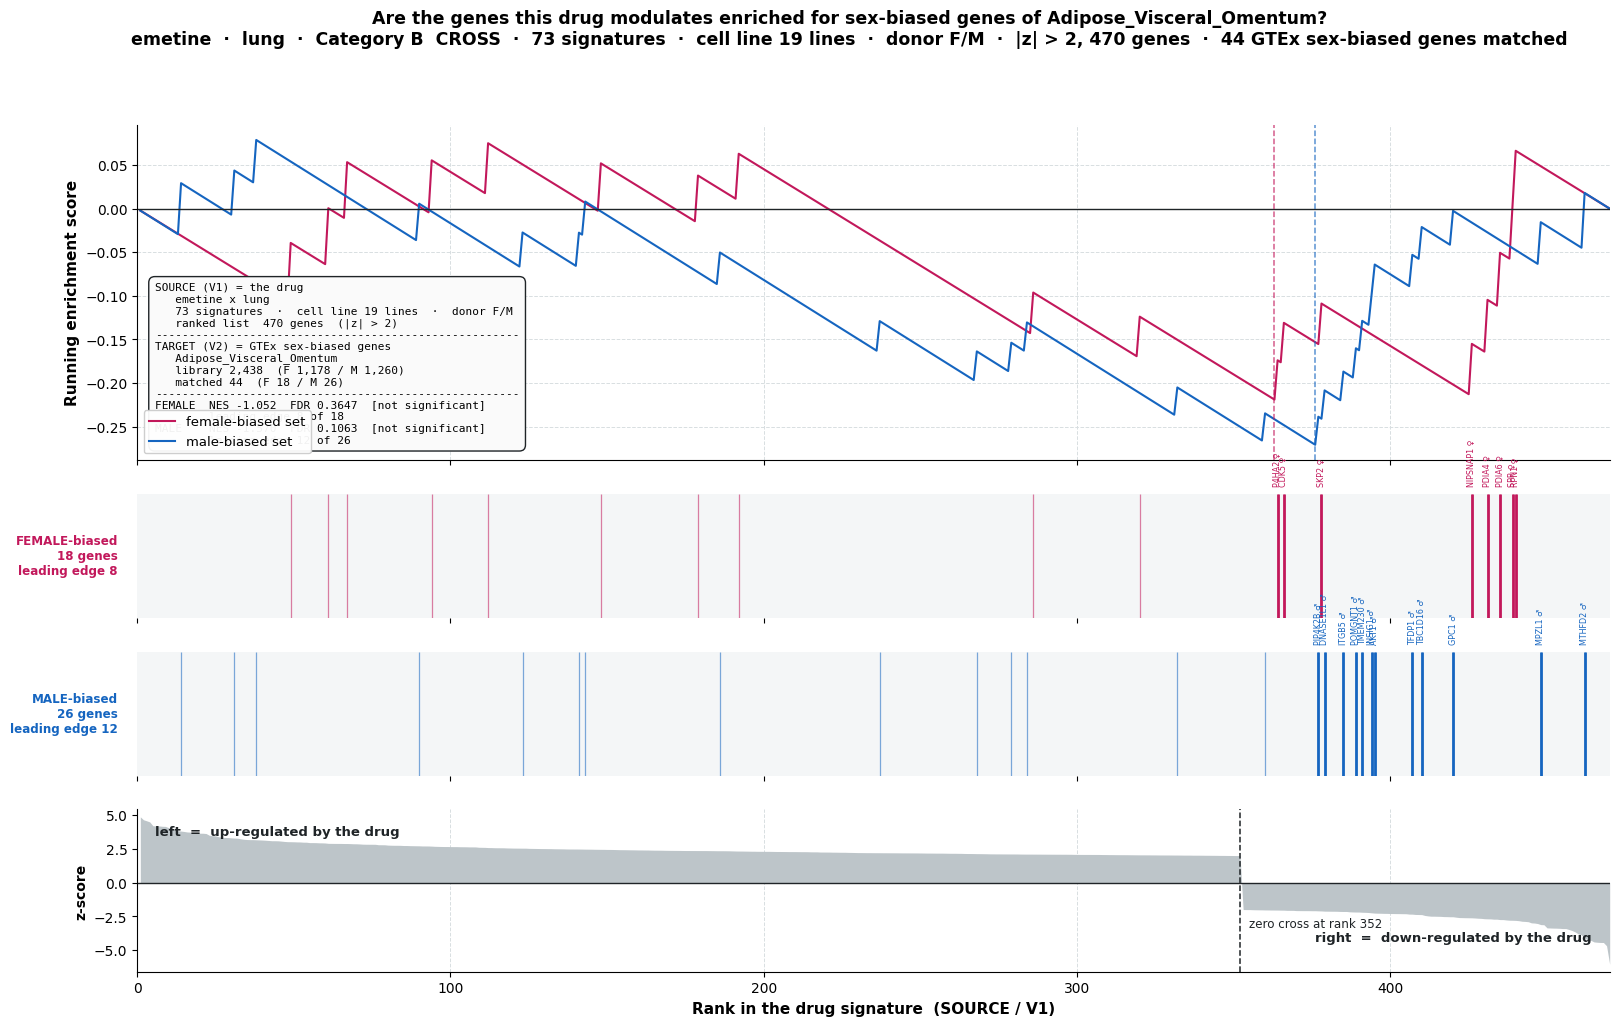


73 signatures  ·  cell line 19 lines  ·  donor F/M   [filtered]
FEMALE  NES -1.052  FDR 0.3647  not significant
MALE    NES -1.570  FDR 0.1063  not significant


{'F': (-1.051909476201194, 0.372960372960373, 0.3647342995169082),
 'M': (-1.570194154992002, 0.05764411027568922, 0.10628019323671498)}

In [23]:
sex_enrichment('emetine', 'lung', 'Adipose_Visceral_Omentum', mode='filtered')

In [24]:
d = sig_known[(sig_known['cmap_name']=='bortezomib') &
              (sig_known['sig_id'].isin(gctx_sigs))]
t = (d.groupby('cell_lineage')
       .agg(signatures=('sig_id','nunique'),
            cell_lines=('cell_iname','nunique'),
            M=('donor_sex', lambda s:(s=='M').sum()),
            F=('donor_sex', lambda s:(s=='F').sum()))
       .sort_values('signatures', ascending=False))
print(t.to_string())
print(f"\nTOTAL : {t.signatures.sum():,}   <- ye hai 7,300")
print("har row ko 44 tissues ke against test kiya jaata hai")
print(f"tests = {len(t)} lineages x 44 = {len(t)*44}")

                                    signatures  cell_lines    M     F
cell_lineage                                                         
breast                                    1875           7    0  1875
lung                                       868          19  762   106
cervix                                     801           1    0   801
prostate                                   791           4  791     0
large_intestine                            741          13   13   728
skin                                       633           8    7   626
pancreas                                   628           1  628     0
kidney                                     455           2    5   450
haematopoietic_and_lymphoid_tissue         255          15  190    65
liver                                       88           3   88     0
ovary                                       45          13    0    45
bone                                        33           4    4    29
endometrium         

In [26]:
# ============================================================
#  SNAPSHOT  —  aaj ka saara kaam ek folder me
# ============================================================
import os, shutil, glob, json
from datetime import datetime

BASE  = '/content/drive/MyDrive/Project59'
STAMP = datetime.now().strftime('%Y-%m-%d')
OUT   = f'{BASE}/deliverables/{STAMP}'

for sub in ['figures', 'results', 'tables', 'notebook']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

# ---------- copy ----------
copied = {'figures': [], 'results': [], 'tables': []}

for src_dir, dst in [(f'{BASE}/figures', 'figures'),
                     (f'{BASE}/results', 'results'),
                     (f'{BASE}/results/tables', 'tables')]:
    if not os.path.isdir(src_dir): continue
    for f in sorted(os.listdir(src_dir)):
        s = f'{src_dir}/{f}'
        if not os.path.isfile(s): continue
        mb = os.path.getsize(s) / 1e6
        if mb > 200:                      # bahut badi files skip
            print(f"   SKIP (too big, {mb:.0f} MB): {f}")
            continue
        shutil.copy2(s, f'{OUT}/{dst}/{f}')
        copied[dst].append((f, mb))

for k, v in copied.items():
    print(f"{k:<10} {len(v):>3} files   {sum(m for _, m in v):>8.1f} MB")

# ---------- README ----------
readme = f"""# Project 59 — snapshot {STAMP}

Sex differences in cancer drug response
CMap LINCS 2020 (Level 5) x GTEx v8 sex-biased genes
Matina Jahan  ·  Fatima Fellowship 2026  ·  advisor: Dr. Marouen Ben Guebila

---

## What was asked (meeting of 29 Sep 2026)

1. How many signatures are there across the 50 drugs?
2. Map those signatures to categories A / B / C / D
3. Bar plot of the 50 drugs: Panel A = percentage, Panel B = absolute counts
4. Run the analysis on one more drug

---

## Headline numbers

| | |
|---|---|
| signatures across 50 drugs | 36,523 |
| A — home tissue, significant | 2,656 (7.3%) |
| B — cross tissue, significant | 5,163 (14.1%) |
| C — tested, not significant | 4,684 (12.8%) |
| D — could not be tested | 24,020 (65.8%) |

Signature distribution is highly uneven: bortezomib alone has 7,300
signatures (20% of the total); the smallest drug has 241.
Eleven of the fifty drugs account for half of all signatures.

---

## Two findings that were not asked for

**1. Category A is almost entirely one drug.**
Of 2,656 Category A signatures, 2,593 (97.6%) are bortezomib.
Only 6 of 50 drugs produced any home-tissue hit; 44 produced none.

**2. Most Category A hits have no female cell lines.**
Of the 29 Category A pair-hits:
- 20 come from cell-line panels with ZERO female donors
- 1 comes from a panel with zero male donors
- 19 of the 29 come from just two pairs (bortezomib x CNS, emetine x CNS),
  each resting on 2-3 male cell lines and 8-9 signatures, spread over
  13 correlated brain subregions

After requiring both sexes present and >= 50 signatures, 2 hits survive.
After requiring more than one cell line per sex, **1** survives:

    bortezomib x haematopoietic_and_lymphoid_tissue -> Cells_EBV.transformed_lymphocytes
    10 male / 5 female cell lines  ·  255 signatures
    FEMALE NES -1.606, FDR < 0.001
    MALE   NES +0.999, FDR 0.487  (null — negative control behaved)
    Fisher exact on raw counts: OR 0.598, p = 0.034

Cause: the >=5 male / >=5 female filter was applied at drug level,
not at drug x lineage level. Within a lineage the balance collapses.

---

## Open questions for the next meeting

1. Keep or drop the |z| > 2 filter? It leaves 65.8% of signatures untestable,
   and every drug with signal is cytotoxic while every targeted kinase
   inhibitor is 100% Category D.
2. Add a lineage-level sex-balance rule (e.g. >= 2 cell lines of each sex)?
3. Add a minimum signature count per pair?
4. CNS maps to 13 brain subregions — count as 13 hits or one?
5. FDR is corrected within each GSEA call (2 gene sets), not across the
   39,996 tests. A project-wide Benjamini-Hochberg pass is still pending.
6. Signature counting: 36,523 unique signatures, or 1,607,012 signature x
   tissue combinations? The bar plot uses unique signatures, with each
   signature given its best category across the 44 tissues.

---

## Method summary

SOURCE (V1)  drug ranked list — CMap Level 5 z-scores, averaged across the
             signatures of one drug x lineage, optionally filtered to |z| > 2
TARGET (V2)  GTEx sex-biased genes for one tissue, split into a FEMALE half
             (effsize > 0) and a MALE half (effsize < 0)
TEST         gseapy.prerank(rnk=V1, gene_sets=halves), 1000 permutations,
             min_size=15, seed=42

Direction verified: ranked list 12,276 genes vs library 473 genes,
overlap 298. The drug is the source, GTEx is the target.

Sex comes from WHICH half is enriched. The NES sign only indicates which
end of the ranking.

---

## Files

See manifest.json in this folder for the full list.

figures/   all plots
results/   per-signature and per-drug tables
tables/    earlier pair-level summaries
"""

open(f'{OUT}/README.md', 'w').write(readme)

# ---------- manifest ----------
manifest = {'date': STAMP,
            'files': {k: [{'name': n, 'size_mb': round(m, 3)} for n, m in v]
                      for k, v in copied.items()}}
json.dump(manifest, open(f'{OUT}/manifest.json', 'w'), indent=2)

print(f"\nREADME.md  +  manifest.json likhe gaye")
print(f"folder: {OUT}")

figures    112 files       30.3 MB
results     20 files       37.2 MB
tables      19 files        5.3 MB

README.md  +  manifest.json likhe gaye
folder: /content/drive/MyDrive/Project59/deliverables/2026-10-05


In [28]:
import shutil
zip_path = shutil.make_archive(f'{BASE}/Project59_{STAMP}', 'zip', OUT)
print(f"zip: {zip_path}   ({os.path.getsize(zip_path)/1e6:.1f} MB)")

# download karna ho to
from google.colab import files
files.download(zip_path)

zip: /content/drive/MyDrive/Project59/Project59_2026-10-05.zip   (34.9 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>